# Гибридная рекомендательная система книг (Goodbooks-10k)

Итоговый проект по рекомендательным системам. Это продолжение домашнего задания №1 (`goodbooks_recommender.ipynb`): те же данные, то же разбиение, те же метрики и модели, поэтому цифры можно сравнивать с ДЗ напрямую.

| Часть | Что сделано | Где |
|---|---|---|
| Этап 1 | Расширенные признаки пользователей, книг и взаимодействий, тематические категории | раздел 1 |
| Этап 2 | Гибрид: взвешенное усреднение, веса по типам пользователей, пул кандидатов, баланс релевантности и разнообразия, популярное, фильтрация прочитанного | раздел 2 |
| Этап 3 | Сравнение гибрида с одиночными моделями, анализ по сегментам, оптимизация весов, метрики, выводы | раздел 3 |
| Продвинутая часть | Нейросеть Two-Tower, интеграция в гибрид, сквозной пайплайн с перезапуском на новых данных | разделы 4 и 5 |

Весь проект лежит в этом ноутбуке и запускается сверху вниз. Сначала идёт код (данные, признаки, метрики, модели, нейросеть, гибрид, пайплайн), потом отчёт, который вызывает этапы пайплайна по очереди. Чтобы запустить всё на других данных, нужно поменять `DATA_DIR` в ячейке «Запуск».

Как оцениваем (так же, как в ДЗ). Временных меток нет, поэтому разбиение случайное внутри каждого пользователя: train 70%, val 10%, test 20%. Релевантной считаем книгу с оценкой >= 4, кандидаты это все книги, которых нет в обучающей части пользователя. Гиперпараметры и веса гибрида подбираем на val (модели обучены на train), финальные модели обучаем на train+val и оцениваем на test один раз

# Код проекта

Код идёт в том порядке, в котором он используется: данные, признаки, метрики, модели, нейросеть, гибрид, пайплайн. Здесь только определения, ничего тяжёлого не запускается. Запуск в ячейке «Запуск» ниже, после неё идёт отчёт.

Зависимости: `numpy<2`, `pandas`, `scipy`, `scikit-learn`, `scikit-surprise`, `torch`, `matplotlib`, `seaborn`, `jupyter` (см. README)

In [1]:
from __future__ import annotations

import copy
import dataclasses
import itertools
import json
import os
import re
import time
import warnings
from abc import ABC, abstractmethod
from contextlib import contextmanager
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display, Markdown
from scipy import sparse
from scipy.sparse.linalg import svds
from sklearn.decomposition import NMF, PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import normalize

warnings.filterwarnings("ignore")

## К1. Данные

Загрузка, очистка и разбиение Goodbooks-10k. Код взят из ДЗ №1, протокол разбиения и нумерация не менялись, так что метрики сопоставимы с ДЗ

In [2]:
LIKE_THRESHOLD = 4  # оценка >= 4 считается «понравилось»

# Служебные теги-«полки» Goodreads: описывают действие читателя, а не содержание книги
SHELF_TAGS = {
    "to-read", "currently-reading", "favorites", "favourites", "favorite", "favourite",
    "all-time-favorites", "books-i-own", "owned", "owned-books", "i-own", "my-books",
    "my-library", "default", "kindle", "library", "to-buy", "ebook", "ebooks", "e-book",
    "e-books", "audiobook", "audiobooks", "audio", "audio-books", "audible", "book-club",
    "read", "finished", "did-not-finish", "dnf", "abandoned", "tbr", "wish-list",
    "wishlist", "borrowed", "own", "have", "owned-but-unread", "unread", "to-read-fiction",
    "my-bookshelf", "books", "bookshelf", "read-more-than-once", "re-read", "reread",
}
SHELF_REGEX = re.compile(r"(read|owned?|shelf).*\d{4}|^\d{4}$|^(read|to-read)-in-")

REQUIRED_COLUMNS = {
    "ratings": {"user_id", "book_id", "rating"},
    "books": {"id", "book_id", "title", "authors", "ratings_count", "average_rating",
              "ratings_1", "ratings_2", "ratings_3", "ratings_4", "ratings_5"},
    "tags": {"tag_id", "tag_name"},
    "book_tags": {"goodreads_book_id", "tag_id", "count"},
}


def is_shelf_tag(name: str) -> bool:
    return name in SHELF_TAGS or bool(SHELF_REGEX.search(name))


@dataclass
class Dataset:
    ratings: pd.DataFrame      # user_id, book_id, rating, u, i (без дублей)
    books: pd.DataFrame        # индекс = i
    book_tags: pd.DataFrame    # goodreads_book_id, tag_id, count, tag_name
    user_ids: np.ndarray       # u -> user_id
    n_users: int
    n_items: int

    @property
    def shape(self) -> tuple[int, int]:
        return self.n_users, self.n_items

    def user_index(self, user_id: int) -> int:
        return int(np.searchsorted(self.user_ids, user_id))


def load_raw(data_dir: str | Path = "data") -> dict[str, pd.DataFrame]:
    """Читает четыре CSV и проверяет, что в них есть нужные колонки (чтобы пайплайн падал сразу и понятно)"""
    d = Path(data_dir)
    raw = {}
    for name, cols in REQUIRED_COLUMNS.items():
        path = d / f"{name}.csv"
        if not path.exists():
            raise FileNotFoundError(f"Не найден файл {path}")
        df = pd.read_csv(path)
        missing = cols - set(df.columns)
        if missing:
            raise ValueError(f"В {path.name} нет колонок: {sorted(missing)}")
        raw[name] = df
    return raw


def build_dataset(raw: dict[str, pd.DataFrame]) -> Dataset:
    """Очистка данных: дубли оценок, отрицательные count у тегов, переименование ключей books"""
    books = raw["books"].rename(columns={"id": "book_id", "book_id": "goodreads_book_id"})
    books = books.sort_values("book_id").reset_index(drop=True)      # индекс = i

    ratings = raw["ratings"].drop_duplicates(["user_id", "book_id"], keep="last")
    ratings = ratings[ratings["book_id"].isin(books["book_id"])]
    user_ids = np.sort(ratings["user_id"].unique())
    item_of_book = pd.Series(books.index.to_numpy(), index=books["book_id"])
    ratings = ratings.assign(
        u=np.searchsorted(user_ids, ratings["user_id"].to_numpy()),
        i=item_of_book.loc[ratings["book_id"]].to_numpy(),
    ).reset_index(drop=True)

    book_tags = raw["book_tags"]
    book_tags = book_tags[book_tags["count"] > 0].merge(raw["tags"], on="tag_id", how="left")
    return Dataset(ratings, books, book_tags, user_ids, len(user_ids), len(books))


def to_csr(df: pd.DataFrame, shape: tuple[int, int], value: str | None = "rating",
           dtype=np.float32) -> sparse.csr_matrix:
    """Таблица (u, i, rating) -> разреженная матрица пользователь x книга (value=None даёт 0/1)"""
    data = np.ones(len(df), dtype=dtype) if value is None else df[value].to_numpy(dtype)
    return sparse.csr_matrix((data, (df["u"].to_numpy(), df["i"].to_numpy())), shape=shape)


def split_per_user(df: pd.DataFrame, test_frac: float, seed: int = 42):
    """Случайное разбиение внутри каждого пользователя.

    В тест уходит round(test_frac * n) оценок пользователя, минимум одна, но не все
    """
    shuffled = df.sample(frac=1.0, random_state=seed)
    grp = shuffled.groupby("u")["u"]
    n = grp.transform("size").to_numpy()
    pos = grp.cumcount().to_numpy()
    n_test = np.minimum(np.maximum(1, np.round(n * test_frac)), n - 1)
    is_test = pos < n_test
    return shuffled[~is_test].sort_index(), shuffled[is_test].sort_index()


@dataclass
class Splits:
    """train / val / trainval / test: протокол из ДЗ (70% / 10% / 20%, внутри каждого пользователя)"""
    train_df: pd.DataFrame
    val_df: pd.DataFrame
    trainval_df: pd.DataFrame
    test_df: pd.DataFrame
    R_train: sparse.csr_matrix
    R_trainval: sparse.csr_matrix


def make_splits(ds: Dataset, test_frac: float = 0.20, val_frac_of_trainval: float = 0.125,
                seed: int = 42) -> Splits:
    trainval_df, test_df = split_per_user(ds.ratings, test_frac, seed=seed)
    train_df, val_df = split_per_user(trainval_df, val_frac_of_trainval, seed=seed + 1)
    assert not set(zip(trainval_df.u, trainval_df.i)) & set(zip(test_df.u, test_df.i)), "утечка train -> test!"
    return Splits(train_df, val_df, trainval_df, test_df,
                  to_csr(train_df, ds.shape), to_csr(trainval_df, ds.shape))

## К2. Признаки (этап 1)

Признаки двух типов:

- статические признаки книг (`ItemContent`): темы (NMF по тегам), текстовые эмбеддинги (SVD от TF-IDF), автор, серия, метаданные Goodreads. От оценок они не зависят и считаются один раз;
- признаки по оценкам (`FeatureStore`): считаются только по обучающей части (для подбора весов по train, для финальной оценки по train+val), поэтому утечки из test нет

#### тексты, автор, серия

In [3]:
def build_book_profiles(books: pd.DataFrame, book_tags: pd.DataFrame,
                        max_tags: int = 30, max_repeat: int = 5) -> pd.Series:
    """Текстовый профиль книги: original_title + теги (из ДЗ)"""
    title = books["original_title"].fillna(books["title"].str.replace(r"\s*\(.*\)\s*$", "", regex=True))

    tags = book_tags[~book_tags["tag_name"].fillna("").map(is_shelf_tag)].copy()
    tags = tags.sort_values(["goodreads_book_id", "count"], ascending=[True, False])
    tags = tags.groupby("goodreads_book_id").head(max_tags)               # самые частые теги книги
    peak = tags.groupby("goodreads_book_id")["count"].transform("max")
    repeat = np.ceil(max_repeat * tags["count"] / peak).astype(int)      # популярный тег повторяем чаще
    token = tags["tag_name"].str.lower().str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")
    tags["text"] = [" ".join([t] * r) for t, r in zip(token, repeat)]
    tag_text = tags.groupby("goodreads_book_id")["text"].agg(" ".join)

    tag_text = books["goodreads_book_id"].map(tag_text).fillna("")
    return (title.fillna("") + " " + tag_text).str.lower()


def first_author(books: pd.DataFrame) -> pd.Series:
    return books["authors"].fillna("").str.split(",").str[0].str.strip()


def series_name(books: pd.DataFrame) -> pd.Series:
    """Название серии из заголовка вида «Title (Series, #1)». У книг без серии: NaN"""
    return books["title"].str.extract(r"\(([^()]*?),?\s*#\d+[^()]*\)")[0]


def _codes(keys: pd.Series) -> np.ndarray:
    """Целочисленные коды ключей; NaN/пустое значение получает уникальный код (не склеивается с другими)"""
    keys = keys.copy()
    empty = keys.isna() | (keys == "")
    keys[empty] = "__none__" + pd.Series(np.arange(len(keys)), index=keys.index).astype(str)[empty]
    return pd.factorize(keys)[0]

#### статические признаки книг

In [4]:
@dataclass
class ItemContent:
    """Признаки книг, которые не зависят от оценок пользователей"""
    tfidf: sparse.csr_matrix          # строки нормированы, (книги x термины)
    item_emb: np.ndarray              # (книги x d), L2-нормированные SVD-эмбеддинги текстового профиля
    genre: np.ndarray                 # (книги x n_genres), строки суммируются в 1 (темы NMF по тегам)
    genre_names: list[str]            # человекочитаемые названия тем (по топ-тегам)
    author_code: np.ndarray           # код первого автора
    series_code: np.ndarray           # код серии (у книг без серии: уникальный)
    has_series: np.ndarray            # книга входит в серию
    meta: pd.DataFrame                # метаданные Goodreads: log_gr_count, gr_avg_rating, gr_rating_entropy, ...
    profiles: pd.Series = field(repr=False, default=None)

    @property
    def n_genres(self) -> int:
        return self.genre.shape[1]

    def book_entities(self, codes: np.ndarray) -> sparse.csr_matrix:
        """Матрица книга -> автор/серия (one-hot, разреженная)"""
        n = len(codes)
        return sparse.csr_matrix((np.ones(n, dtype=np.float32), (np.arange(n), codes)), shape=(n, codes.max() + 1))


def _topic_model(books: pd.DataFrame, book_tags: pd.DataFrame, n_topics: int, seed: int,
                 n_tags: int = 1500) -> tuple[np.ndarray, list[str]]:
    """Тематические категории: NMF по матрице «книга x содержательный тег».

    Берём n_tags самых распространённых содержательных (не «полочных») тегов, вес тега в книге: log1p(count), затем нормировка
    строк. Каждая тема получает название из трёх самых характерных тегов
    """
    tags = book_tags[~book_tags["tag_name"].fillna("").map(is_shelf_tag)]
    top = tags.groupby("tag_name").size().sort_values(ascending=False).head(n_tags).index
    tags = tags[tags["tag_name"].isin(top)]
    item_of = pd.Series(np.arange(len(books)), index=books["goodreads_book_id"])
    rows = item_of.reindex(tags["goodreads_book_id"]).to_numpy()
    ok = ~np.isnan(rows)
    cols_of = pd.Series(np.arange(len(top)), index=top)
    cols = cols_of.loc[tags["tag_name"]].to_numpy()
    mat = sparse.csr_matrix((np.log1p(tags["count"].to_numpy(dtype=np.float32))[ok],
                             (rows[ok].astype(int), cols[ok])), shape=(len(books), len(top)))
    mat = normalize(mat, norm="l2")
    nmf = NMF(n_components=n_topics, init="nndsvd", random_state=seed, max_iter=300)
    w = nmf.fit_transform(mat)                                        # (книги x темы)
    names = []
    for t in range(n_topics):
        best = np.argsort(-nmf.components_[t])[:3]
        names.append("/".join(str(top[j]) for j in best))
    row_sum = w.sum(axis=1, keepdims=True)
    genre = np.divide(w, row_sum, out=np.full_like(w, 1.0 / n_topics), where=row_sum > 0)
    return genre.astype(np.float32), names


def build_item_content(ds: Dataset, n_topics: int = 20, emb_dim: int = 64, seed: int = 42) -> ItemContent:
    books = ds.books
    profiles = build_book_profiles(books, ds.book_tags)
    vec = TfidfVectorizer(stop_words="english", sublinear_tf=True, min_df=2)
    tfidf = vec.fit_transform(profiles).astype(np.float32).tocsr()
    d = int(min(emb_dim, tfidf.shape[1] - 1, max(2, tfidf.shape[0] - 1)))
    emb = TruncatedSVD(n_components=d, random_state=seed).fit_transform(tfidf)
    emb = normalize(emb).astype(np.float32)

    n_topics = int(min(n_topics, max(2, len(books) // 5)))
    genre, genre_names = _topic_model(books, ds.book_tags, n_topics, seed)

    authors, series = first_author(books), series_name(books)
    cnt = books[[f"ratings_{r}" for r in range(1, 6)]].to_numpy(dtype=np.float64)
    p = cnt / np.maximum(cnt.sum(axis=1, keepdims=True), 1)
    entropy = -(np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0)).sum(axis=1) / np.log(5)
    year = books["original_publication_year"].fillna(books["original_publication_year"].median()) \
        if "original_publication_year" in books else pd.Series(0.0, index=books.index)
    meta = pd.DataFrame({
        "log_gr_count": np.log1p(books["ratings_count"].to_numpy(dtype=np.float64)),
        "gr_avg_rating": books["average_rating"].to_numpy(dtype=np.float64),
        "gr_rating_entropy": entropy,                                       # разнообразие оценок книги
        "gr_like_share": (cnt[:, 3] + cnt[:, 4]) / np.maximum(cnt.sum(axis=1), 1),
        "year": year.clip(lower=1800).to_numpy(dtype=np.float64),
    }, index=books.index)
    return ItemContent(tfidf, emb, genre, genre_names, _codes(authors), _codes(series),
                       series.notna().to_numpy(), meta, profiles)

#### признаки, зависящие от оценок

In [5]:
USER_SEGMENTS = ("new", "regular", "active")


def segment_users(n_ratings: np.ndarray, new_max: int = 4, active_min: int = 30) -> np.ndarray:
    """Тип пользователя по числу оценок в обучающей части: 0: новый (<5), 1: обычный, 2: активный (>=30)"""
    return np.where(n_ratings <= new_max, 0, np.where(n_ratings >= active_min, 2, 1))


@dataclass
class FeatureStore:
    """Признаки пользователей и книг, рассчитанные по одной обучающей выборке"""
    content: ItemContent
    user_features: pd.DataFrame       # индекс u
    item_features: pd.DataFrame       # индекс i
    user_genre: np.ndarray            # (пользователи x темы): профиль тем понравившихся книг, сумма 1 (или 0)
    likes: sparse.csr_matrix          # (пользователи x книги): 1, если оценка >= порога
    user_segment: np.ndarray          # 0/1/2 (см. segment_users)

    @property
    def item_emb(self) -> np.ndarray:
        return self.content.item_emb


def build_features(ds: Dataset, train_df: pd.DataFrame, content: ItemContent,
                   like_threshold: float = LIKE_THRESHOLD, prior_strength: float = 10.0,
                   new_max: int = 4, active_min: int = 30) -> FeatureStore:
    """Расширенные признаки пользователей и книг по обучающей выборке train_df (колонки u, i, rating)"""
    n_users, n_items = ds.shape
    u, i, r = train_df["u"].to_numpy(), train_df["i"].to_numpy(), train_df["rating"].to_numpy(dtype=np.float64)
    like = r >= like_threshold
    gmean = r.mean()
    R_like = to_csr(train_df[like], ds.shape, value=None)

    # ----- признаки пользователей
    n = np.bincount(u, minlength=n_users).astype(np.float64)
    s1 = np.bincount(u, weights=r, minlength=n_users)
    s2 = np.bincount(u, weights=r * r, minlength=n_users)
    n_like = np.bincount(u, weights=like.astype(np.float64), minlength=n_users)
    n_dis = np.bincount(u, weights=(r <= 2).astype(np.float64), minlength=n_users)
    safe_n = np.maximum(n, 1)
    mean_u = np.where(n > 0, s1 / safe_n, gmean)
    std_u = np.sqrt(np.maximum(s2 / safe_n - (s1 / safe_n) ** 2, 0))
    gr_pop = content.meta["log_gr_count"].to_numpy()
    mainstream = np.where(n > 0, np.bincount(u, weights=gr_pop[i], minlength=n_users) / safe_n, gr_pop.mean())

    user_genre = np.asarray(R_like @ content.genre)                                  # суммы по лайкам
    gsum = user_genre.sum(axis=1, keepdims=True)
    user_genre = np.divide(user_genre, gsum, out=np.zeros_like(user_genre), where=gsum > 0)
    ent = -(np.where(user_genre > 0, user_genre * np.log(np.where(user_genre > 0, user_genre, 1)), 0)).sum(axis=1)
    genre_entropy = ent / np.log(content.n_genres)                                   # 0: один жанр, 1: всё поровну

    series_share = np.asarray(R_like @ content.has_series.astype(np.float32)).ravel() / np.maximum(n_like, 1)
    a_mat = content.book_entities(content.author_code)
    distinct_authors = np.asarray((R_like @ a_mat > 0).sum(axis=1)).ravel()
    author_repeat = np.where(n_like > 0, 1 - distinct_authors / np.maximum(n_like, 1), 0.0)

    segment = segment_users(n, new_max, active_min)
    user_features = pd.DataFrame({
        "n_ratings": n, "log_n_ratings": np.log1p(n),
        "activity_pct": pd.Series(n).rank(pct=True).to_numpy(),                      # перцентиль активности
        "mean_rating": mean_u, "rating_bias": mean_u - gmean, "rating_std": std_u,
        "like_share": np.where(n > 0, n_like / safe_n, 0.0),
        "dislike_share": np.where(n > 0, n_dis / safe_n, 0.0),
        "mainstream": mainstream,                                                    # любит ли популярные книги
        "genre_entropy": genre_entropy,                                              # широта вкуса
        "series_share": series_share, "author_repeat": author_repeat,
        "segment": segment,
    })

    # ----- признаки книг (по оценкам из train)
    ni = np.bincount(i, minlength=n_items).astype(np.float64)
    si = np.bincount(i, weights=r, minlength=n_items)
    si2 = np.bincount(i, weights=r * r, minlength=n_items)
    li = np.bincount(i, weights=like.astype(np.float64), minlength=n_items)
    safe_ni = np.maximum(ni, 1)
    mean_i = np.where(ni > 0, si / safe_ni, gmean)
    glob_like = like.mean()
    dist = np.stack([np.bincount(i[r == k], minlength=n_items) for k in range(1, 6)], axis=1).astype(np.float64)
    p = dist / np.maximum(dist.sum(axis=1, keepdims=True), 1)
    ent_i = -(np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0)).sum(axis=1) / np.log(5)
    item_features = pd.DataFrame({
        "n_ratings": ni, "log_n_ratings": np.log1p(ni),
        "popularity_pct": pd.Series(ni).rank(pct=True).to_numpy(),
        "bayes_mean": (si + prior_strength * gmean) / (ni + prior_strength),         # средняя оценка со сжатием
        "rating_std": np.sqrt(np.maximum(si2 / safe_ni - (si / safe_ni) ** 2, 0)),
        "rating_entropy": ent_i,                                                     # разнообразие оценок
        "like_ratio": (li + prior_strength * glob_like) / (ni + prior_strength),
        "main_genre": content.genre.argmax(axis=1),
    })
    item_features = pd.concat([item_features, content.meta], axis=1)
    return FeatureStore(content, user_features, item_features, user_genre.astype(np.float32), R_like, segment)

#### признаки взаимодействий

In [6]:
def author_series_counts(store: FeatureStore, users: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Для каждой пары (пользователь, книга): сколько понравившихся пользователю книг написал тот же автор /
    входит в ту же серию. Возвращает две плотные матрицы (len(users), n_items)"""
    c = store.content
    likes = store.likes[users]
    out = []
    for codes in (c.author_code, c.series_code):
        ent = c.book_entities(codes)                                 # книги x сущности (one-hot)
        out.append((likes @ ent @ ent.T).toarray().astype(np.float32))
    return out[0], out[1]


def genre_affinity(store: FeatureStore, users: np.ndarray) -> np.ndarray:
    """Косинус между профилем тем пользователя и темами книги"""
    ug = normalize(store.user_genre[users])
    ig = normalize(store.content.genre)
    return (ug @ ig.T).astype(np.float32)


def max_history_similarity(store: FeatureStore, users: np.ndarray, max_hist: int = 40,
                           batch: int = 64) -> np.ndarray:
    """Схожесть книги с самой близкой из понравившихся пользователю (по текстовым эмбеддингам)"""
    e = store.item_emb
    out = np.zeros((len(users), e.shape[0]), dtype=np.float32)
    likes = store.likes
    for s in range(0, len(users), batch):
        for k, u in enumerate(users[s:s + batch]):
            liked = likes.indices[likes.indptr[u]:likes.indptr[u + 1]]
            if len(liked) == 0:
                continue
            liked = liked[:max_hist]
            out[s + k] = (e @ e[liked].T).max(axis=1)
    return out


def interaction_features(store: FeatureStore, users: np.ndarray, items: np.ndarray) -> pd.DataFrame:
    """Таблица признаков взаимодействия для пар (users[k], items[k]): для анализа и отладки"""
    users, items = np.asarray(users), np.asarray(items)
    c, rows = store.content, []
    ent_a, ent_s = c.book_entities(c.author_code), c.book_entities(c.series_code)
    likes = store.likes[users]
    same_author = np.asarray((likes @ ent_a).multiply(ent_a[items]).sum(axis=1)).ravel()
    same_series = np.asarray((likes @ ent_s).multiply(ent_s[items]).sum(axis=1)).ravel()
    ug, ig = normalize(store.user_genre[users]), normalize(c.genre[items])
    sim = np.zeros(len(users), dtype=np.float32)
    for k, (u, i) in enumerate(zip(users, items)):
        liked = store.likes.indices[store.likes.indptr[u]:store.likes.indptr[u + 1]]
        if len(liked):
            sim[k] = (store.item_emb[liked] @ store.item_emb[i]).max()
    uf = store.user_features["mainstream"].to_numpy()[users]
    return pd.DataFrame({
        "same_author_likes": same_author, "same_series_likes": same_series,
        "genre_affinity": (ug * ig).sum(axis=1), "max_history_sim": sim,
        "pop_gap": np.abs(store.item_features["log_gr_count"].to_numpy()[items] - uf),
        "item_bias_vs_user": store.item_features["bayes_mean"].to_numpy()[items]
        - store.user_features["mean_rating"].to_numpy()[users],
    })

## К3. Метрики и интерфейс моделей

Precision@K, Recall@K и nDCG@K перенесены из ДЗ. Добавлены метрики разнообразия (ILD, novelty, coverage) и быстрый оценщик `FastEvaluator` для подбора весов гибрида

#### базовые операции со скорами

In [7]:
def top_k(scores: np.ndarray, k: int) -> np.ndarray:
    """Индексы k лучших элементов в каждой строке (по убыванию скора)"""
    k = min(k, scores.shape[1])
    part = np.argpartition(-scores, k - 1, axis=1)[:, :k]          # O(n), без полной сортировки
    order = np.argsort(-np.take_along_axis(scores, part, axis=1), axis=1, kind="stable")
    return np.take_along_axis(part, order, axis=1)


def mask_seen(scores: np.ndarray, seen: sparse.spmatrix | None) -> np.ndarray:
    """Ставит -inf для книг, которые пользователь уже оценил (меняет массив на месте)"""
    if seen is not None:
        coo = seen.tocoo()
        scores[coo.row, coo.col] = -np.inf
    return scores


def zscore(scores: np.ndarray) -> np.ndarray:
    """Стандартизация скоров каждого пользователя (по строкам)"""
    mean = scores.mean(axis=1, keepdims=True)
    std = scores.std(axis=1, keepdims=True)
    return (scores - mean) / np.where(std > 0, std, 1.0)

#### метрики ранжирования

In [8]:
def ranking_metrics(hits: np.ndarray, n_relevant: np.ndarray, ks: tuple[int, ...]) -> dict[str, np.ndarray]:
    """Precision@K, Recall@K и nDCG@K для каждого пользователя.

    hits[u, r]: релевантна ли книга на позиции r (с нуля) в выдаче пользователя u,
    n_relevant[u]: число релевантных книг пользователя в тесте (больше нуля)
    """
    hits = hits.astype(np.float64)
    discounts = 1.0 / np.log2(np.arange(2, hits.shape[1] + 2))      # 1 / log2(позиция + 1)
    ideal_cum = np.cumsum(discounts)
    out = {}
    for k in ks:
        h = hits[:, :k]
        n_hit = h.sum(axis=1)
        dcg = (h * discounts[:k]).sum(axis=1)
        idcg = ideal_cum[np.minimum(k, n_relevant) - 1]             # идеальная выдача
        out[f"P@{k}"] = n_hit / k
        out[f"R@{k}"] = n_hit / n_relevant
        out[f"nDCG@{k}"] = dcg / idcg
    return out


def rmse(pred, true) -> float:
    return float(np.sqrt(np.mean((np.asarray(pred, dtype=np.float64) - np.asarray(true, dtype=np.float64)) ** 2)))

#### метрики разнообразия

In [9]:
def list_diversity(recs: np.ndarray, ks: tuple[int, ...], item_pop: np.ndarray, n_users_train: int,
                   n_cand: int, item_emb: np.ndarray | None = None) -> dict[str, float]:
    """Метрики выдач целиком (не зависят от релевантности).

    coverage@K: доля каталога, попавшая хоть в одну выдачу;
    avg_pop@K: среднее число train-оценок у рекомендованных книг;
    novelty@K: средняя «информативность» книги -log2(p_i), p_i = (n_i + 1) / (n_users + 1): чем больше, тем реже книги;
    ild@K: Intra-List Diversity: средняя попарная (1: косинус) эмбеддингов книг внутри выдачи
    """
    out = {}
    self_info = -np.log2((item_pop + 1.0) / (n_users_train + 1.0))
    for k in ks:
        r = recs[:, :k]
        out[f"coverage@{k}"] = len(np.unique(r)) / n_cand
        out[f"avg_pop@{k}"] = float(item_pop[r].mean())
        out[f"novelty@{k}"] = float(self_info[r].mean())
        if item_emb is not None and k > 1:
            v = item_emb[r]                                           # (users, k, d), строки нормированы
            gram = np.einsum("ukd,ujd->ukj", v, v)
            out[f"ild@{k}"] = float(((k * k - gram.sum(axis=(1, 2))) / (k * (k - 1))).mean())
    return out

#### интерфейс моделей

In [10]:
class Recommender(ABC):
    name: str = "model"

    @abstractmethod
    def score(self, users: np.ndarray) -> np.ndarray:
        """Матрица скоров (len(users), n_items): чем больше, тем выше книга в выдаче"""

    def recommend(self, users: np.ndarray, n: int = 10, seen: sparse.csr_matrix | None = None) -> np.ndarray:
        """Индексы top-n книг, которых пользователь ещё не оценил"""
        users = np.asarray(users)
        scores = np.array(self.score(users), dtype=np.float32)
        mask_seen(scores, None if seen is None else seen[users])
        return top_k(scores, n)


class PrecomputedScores(Recommender):
    """Отдаёт заранее посчитанную матрицу скоров (для быстрого перебора весов)"""
    name = "precomputed"

    def __init__(self, scores: np.ndarray):
        self.scores = scores

    def score(self, users: np.ndarray) -> np.ndarray:
        assert len(users) == len(self.scores)
        return self.scores


@dataclass
class EvalResult:
    summary: pd.Series      # метрики, усреднённые по пользователям
    per_user: pd.DataFrame  # метрики каждого пользователя
    recs: np.ndarray | None = None   # выдачи (строки соответствуют per_user.index)


def evaluate_ranking(model, train: sparse.csr_matrix, test_df: pd.DataFrame,
                     ks: tuple[int, ...] = (5, 10, 20), threshold: float = LIKE_THRESHOLD,
                     users: np.ndarray | None = None, candidates: np.ndarray | None = None,
                     batch_size: int = 2000, item_emb: np.ndarray | None = None) -> EvalResult:
    """Считает Precision/Recall/nDCG@K (+ coverage, avg_pop, novelty и ild, если передан item_emb).

    Релевантные книги пользователя: его оценки в test_df не ниже threshold. Кандидаты -
    все книги, которых нет в train (или только candidates). Усредняем по пользователям,
    у которых есть хотя бы одна релевантная книга.

    Если у модели есть метод `rank(users, k, seen)`, возвращающий готовые выдачи (так устроена
    итоговая гибридная система с пулом кандидатов и переранжированием), используется он,
    иначе выдача строится по `score`
    """
    n_users, n_items = train.shape
    rel = to_csr(test_df[test_df["rating"] >= threshold], train.shape, value=None, dtype=np.int8)
    rel_counts = np.asarray(rel.sum(axis=1)).ravel()
    eval_users = np.flatnonzero(rel_counts > 0)
    if users is not None:
        eval_users = np.intersect1d(eval_users, users)

    allowed = None
    if candidates is not None:
        allowed = np.zeros(n_items, dtype=bool)
        allowed[candidates] = True

    k_max = max(ks)
    recs, metrics = [], {}
    for start in range(0, len(eval_users), batch_size):
        batch = eval_users[start:start + batch_size]
        if hasattr(model, "rank") and allowed is None:
            rec = model.rank(batch, k_max, train[batch])
        else:
            scores = np.array(model.score(batch), dtype=np.float32)    # копия, дальше пишем в неё
            mask_seen(scores, train[batch])
            if allowed is not None:
                scores[:, ~allowed] = -np.inf
            rec = top_k(scores, k_max)
        hits = np.take_along_axis(rel[batch].toarray(), rec, axis=1).astype(bool)
        for name, values in ranking_metrics(hits, rel_counts[batch], ks).items():
            metrics.setdefault(name, []).append(values)
        recs.append(rec)

    recs = np.vstack(recs)
    per_user = pd.DataFrame({k: np.concatenate(v) for k, v in metrics.items()}, index=eval_users)
    per_user.index.name = "u"
    per_user["n_train"] = np.asarray(train[eval_users].getnnz(axis=1)).ravel()

    summary = per_user.drop(columns="n_train").mean()
    item_pop = np.asarray(train.getnnz(axis=0)).ravel()
    n_cand = n_items if candidates is None else len(candidates)
    for name, value in list_diversity(recs, ks, item_pop, n_users, n_cand, item_emb).items():
        summary[name] = value
    summary["n_users"] = len(eval_users)
    return EvalResult(summary, per_user, recs)


def results_table(results: dict[str, EvalResult], columns: list[str]) -> pd.DataFrame:
    """Сводная таблица: строки: модели, колонки: выбранные метрики"""
    return pd.DataFrame({name: r.summary for name, r in results.items()}).T[columns]


def paired_diff(a: EvalResult, b: EvalResult, metric: str) -> pd.Series:
    """Разность метрики по пользователям (парное сравнение) и 95% доверительный интервал"""
    idx = a.per_user.index.intersection(b.per_user.index)
    d = a.per_user.loc[idx, metric] - b.per_user.loc[idx, metric]
    m, se = d.mean(), d.std() / np.sqrt(len(d))
    return pd.Series({"разность": m, "95% ДИ от": m - 1.96 * se, "95% ДИ до": m + 1.96 * se,
                      "значимо": bool(m - 1.96 * se > 0 or m + 1.96 * se < 0)})

#### быстрый оценщик для подбора весов

In [11]:
class FastEvaluator:
    """Считает nDCG/Recall/Precision@K для заранее посчитанных матриц скоров фиксированной выборки пользователей.

    Маски «уже оценено» и релевантные книги хранятся плотными булевыми матрицами, поэтому одна оценка -
    это np.where + argpartition без обращений к разреженным матрицам. Это нужно, потому что при подборе
    весов гибрида оценка вызывается сотни раз
    """

    def __init__(self, train: sparse.csr_matrix, eval_df: pd.DataFrame, users: np.ndarray, k: int = 10,
                 threshold: float = LIKE_THRESHOLD):
        rel = to_csr(eval_df[eval_df["rating"] >= threshold], train.shape, value=None, dtype=np.int8)
        users = np.asarray(users)
        users = users[np.asarray(rel[users].sum(axis=1)).ravel() > 0]
        self.users, self.k = users, k
        self.seen = train[users].toarray() > 0
        self.rel = rel[users].toarray() > 0
        self.n_rel = self.rel.sum(axis=1)
        self.discounts = 1.0 / np.log2(np.arange(2, k + 2))
        self.idcg = np.cumsum(self.discounts)[np.minimum(k, self.n_rel) - 1]

    def evaluate(self, scores: np.ndarray) -> dict[str, float]:
        assert scores.shape == self.seen.shape
        masked = np.where(self.seen, -np.inf, scores)
        rec = top_k(masked, self.k)
        hits = np.take_along_axis(self.rel, rec, axis=1)
        n_hit = hits.sum(axis=1)
        dcg = (hits * self.discounts).sum(axis=1)
        return {f"nDCG@{self.k}": float((dcg / self.idcg).mean()),
                f"R@{self.k}": float((n_hit / self.n_rel).mean()),
                f"P@{self.k}": float((n_hit / self.k).mean())}

## К4. Модели

Модели из ДЗ (Popularity, Content-based, Item-CF, SVD, PureSVD) и две лёгкие модели на признаках (`AuthorSeriesAffinity`, `ItemQualityPrior`). Все наследуются от `Recommender` с одним методом `score(users)`, который возвращает матрицу скоров (пользователи x книги)

#### неперсонализированные

In [12]:
class PopularityRecommender(Recommender):
    """Одинаковый топ для всех.

    mean_rating: средняя оценка среди книг, у которых не меньше min_ratings оценок;
    bayesian: взвешенный рейтинг как в IMDb: (v*R + m*C) / (v + m);
    count: число оценок
    """

    def __init__(self, strategy: str = "mean_rating", min_ratings: int = 50):
        assert strategy in {"mean_rating", "bayesian", "count"}
        self.strategy, self.min_ratings = strategy, min_ratings
        self.name = f"Popularity ({strategy})"

    def fit(self, train: sparse.csr_matrix) -> "PopularityRecommender":
        counts = np.asarray(train.getnnz(axis=0)).ravel().astype(np.float64)
        sums = np.asarray(train.sum(axis=0)).ravel().astype(np.float64)
        self.counts_ = counts
        self.means_ = np.divide(sums, counts, out=np.zeros_like(sums), where=counts > 0)
        if self.strategy == "mean_rating":
            self.scores_ = np.where(counts >= self.min_ratings, self.means_, 0.0)   # 0 меньше любой оценки
        elif self.strategy == "bayesian":
            c_global = sums.sum() / counts.sum()
            self.scores_ = (sums + self.min_ratings * c_global) / (counts + self.min_ratings)
        else:
            self.scores_ = counts
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return np.broadcast_to(self.scores_.astype(np.float32), (len(users), len(self.scores_)))

    def top_n(self, n: int, books: pd.DataFrame) -> pd.DataFrame:
        idx = np.argsort(-self.scores_, kind="stable")[:n]
        out = books.loc[idx, ["book_id", "title", "authors"]].copy()
        out["mean_rating"] = self.means_[idx]
        out["n_ratings"] = self.counts_[idx].astype(int)
        return out.reset_index(drop=True)


class RandomRecommender(Recommender):
    name = "Random"

    def __init__(self, seed: int = 0):
        self.seed = seed

    def fit(self, train: sparse.csr_matrix) -> "RandomRecommender":
        self.n_items = train.shape[1]
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return np.random.default_rng(self.seed).random((len(users), self.n_items), dtype=np.float32)


class ItemQualityPrior(Recommender):
    """Неперсональный «приор качества» книги на признаках: смесь стандартизованных
    Байесовской средней оценки в train и глобальной средней оценки Goodreads.

    В ДЗ роль приора неявно играла компонента SVD (смещение книги b_i). Здесь он задан явно
    """
    name = "Item quality prior"

    def __init__(self, w_train: float = 0.5):
        self.w_train = w_train

    def fit(self, store: FeatureStore) -> "ItemQualityPrior":
        f = store.item_features
        std = lambda x: (x - x.mean()) / (x.std() + 1e-9)
        self.scores_ = (self.w_train * std(f["bayes_mean"]) + (1 - self.w_train) * std(f["gr_avg_rating"])
                        ).to_numpy(np.float32)
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return np.broadcast_to(self.scores_, (len(users), len(self.scores_)))

#### контентная модель

In [13]:
class ContentBasedRecommender(Recommender):
    """TF-IDF по профилям книг. Профиль пользователя: сумма векторов понравившихся книг"""

    name = "Content-based (TF-IDF)"

    def __init__(self, like_threshold: float = LIKE_THRESHOLD):
        self.like_threshold = like_threshold

    def fit_items(self, content: ItemContent, books: pd.DataFrame) -> "ContentBasedRecommender":
        self.books, self.tfidf = books, content.tfidf
        return self

    def fit(self, train: sparse.csr_matrix) -> "ContentBasedRecommender":
        self.likes_ = (train >= self.like_threshold).astype(np.float32).tocsr()
        return self

    def get_similar_books(self, book_id: int, N: int = 5) -> pd.DataFrame:
        """N книг, ближайших к book_id по косинусу TF-IDF-векторов"""
        item = int(self.books.index[self.books["book_id"] == book_id][0])
        sims = (self.tfidf @ self.tfidf[item].T).toarray().ravel()
        sims[item] = -np.inf
        idx = np.argsort(-sims, kind="stable")[:N]
        out = self.books.loc[idx, ["book_id", "title", "authors"]].copy()
        out["similarity"] = sims[idx]
        return out.reset_index(drop=True)

    def score(self, users: np.ndarray) -> np.ndarray:
        profile = (self.likes_[users] @ self.tfidf).toarray()
        norm = np.linalg.norm(profile, axis=1, keepdims=True)
        profile /= np.where(norm > 0, norm, 1.0)
        return np.asarray(self.tfidf @ profile.T).T

#### item-based CF

In [14]:
class ItemBasedCF(Recommender):
    """Item-based CF: top-K соседей для каждой книги, shrinkage, предсказание оценок с демпфированием.

    feedback="explicit": вектор книги: оценки, центрированные по среднему пользователя
    (косинус таких векторов: adjusted cosine); используется для предсказания оценок.
    feedback="implicit": вектор книги: 1, если оценка >= порога, иначе 0; используется для top-N
    """

    def __init__(self, k: int = 50, feedback: str = "implicit", shrinkage: float = 10.0,
                 like_threshold: float = LIKE_THRESHOLD, damping: float = 0.0, chunk: int = 500):
        assert feedback in {"explicit", "implicit"}
        self.k, self.feedback, self.shrinkage = k, feedback, shrinkage
        self.like_threshold, self.damping, self.chunk = like_threshold, damping, chunk
        self.name = f"Item-based CF ({feedback}, K={k})"

    def fit(self, train: sparse.csr_matrix) -> "ItemBasedCF":
        train = train.tocsr().astype(np.float32)
        self.n_items = train.shape[1]
        rated = (train != 0).astype(np.float32).tocsr()

        counts = np.asarray(rated.sum(axis=1)).ravel()
        sums = np.asarray(train.sum(axis=1)).ravel()
        self.user_mean_ = np.divide(sums, counts, out=np.full(len(sums), train.data.mean()),
                                    where=counts > 0).astype(np.float32)
        centred = train.copy()
        centred.data = centred.data - np.repeat(self.user_mean_, np.diff(train.indptr))

        n_i = np.asarray(rated.sum(axis=0)).ravel()
        self.item_dev_ = np.divide(np.asarray(centred.sum(axis=0)).ravel(), n_i,
                                   out=np.zeros(self.n_items), where=n_i > 0).astype(np.float32)

        resid = train.copy()
        row = np.repeat(np.arange(train.shape[0]), np.diff(train.indptr))
        resid.data = train.data - self.user_mean_[row] - self.item_dev_[train.indices]
        self.resid_ = resid

        if self.feedback == "explicit":
            x, support = centred, rated
        else:
            x = (train >= self.like_threshold).astype(np.float32).tocsr()
            support = x
        self.x_, self.rated_ = x.tocsr(), rated
        self.S_ = self._top_k_similarities(self.x_, support.tocsr())
        return self

    def _top_k_similarities(self, x: sparse.csr_matrix, support: sparse.csr_matrix) -> sparse.csr_matrix:
        """Схожести книг считаем блоками по chunk книг и оставляем только K лучших соседей"""
        n_items, k = self.n_items, min(self.k, self.n_items - 1)
        xt, st = x.T.tocsr(), support.T.tocsr()
        norms = np.sqrt(np.asarray(x.multiply(x).sum(axis=0)).ravel()) + 1e-9

        rows, cols, vals = [], [], []
        for start in range(0, n_items, self.chunk):
            sl = slice(start, min(start + self.chunk, n_items))
            dots = (xt[sl] @ x).toarray()
            common = (st[sl] @ support).toarray()
            sim = dots / (norms[sl, None] * norms[None, :])
            sim *= common / (common + self.shrinkage + 1e-9)
            sim[np.arange(sl.stop - sl.start), np.arange(sl.start, sl.stop)] = 0
            sim[sim < 0] = 0
            nb = np.argpartition(-sim, k - 1, axis=1)[:, :k]
            nb_val = np.take_along_axis(sim, nb, axis=1)
            keep = nb_val > 0
            rows.append(np.repeat(np.arange(sl.start, sl.stop), k).reshape(-1, k)[keep])
            cols.append(nb[keep])
            vals.append(nb_val[keep])
        return sparse.csr_matrix((np.concatenate(vals).astype(np.float32),
                                  (np.concatenate(rows), np.concatenate(cols))),
                                 shape=(n_items, n_items))

    def score(self, users: np.ndarray) -> np.ndarray:
        """Скор книги i для пользователя u: сумма схожестей i с понравившимися книгами среди её K соседей"""
        return (self.x_[users] @ self.S_.T).toarray()

    def predict_ratings(self, users: np.ndarray, items: np.ndarray, damping: float | None = None,
                        batch: int = 50_000) -> np.ndarray:
        """r_hat(u, i) = b_ui + sum_j s_ij * (r_uj: b_uj) / (sum_j s_ij + damping)"""
        damping = self.damping if damping is None else damping
        users, items = np.asarray(users), np.asarray(items)
        preds = np.empty(len(users), dtype=np.float64)
        n_with_neighbours = 0
        for s in range(0, len(users), batch):
            u, i = users[s:s + batch], items[s:s + batch]
            neigh = self.S_[i]
            num = np.asarray(neigh.multiply(self.resid_[u]).sum(axis=1)).ravel()
            den = np.asarray(neigh.multiply(self.rated_[u]).sum(axis=1)).ravel()
            has = den > 0
            base = self.user_mean_[u] + self.item_dev_[i]
            preds[s:s + batch] = base + np.where(has, num / (den + damping + 1e-9), 0.0)
            n_with_neighbours += has.sum()
        self.coverage_ = n_with_neighbours / max(len(users), 1)
        return np.clip(preds, 1, 5)

#### SVD (surprise) и PureSVD

In [15]:
class SVDRecommender(Recommender):
    """Обёртка над surprise.SVD: r_hat(u, i) = mu + b_u + b_i + p_u * q_i"""

    name = "SVD (surprise)"

    def __init__(self, n_factors: int = 100, n_epochs: int = 20, lr_all: float = 0.005,
                 reg_all: float = 0.02, random_state: int = 42):
        self.params = dict(n_factors=n_factors, n_epochs=n_epochs, lr_all=lr_all,
                           reg_all=reg_all, random_state=random_state)

    def fit(self, train_df: pd.DataFrame, shape: tuple[int, int]) -> "SVDRecommender":
        from surprise import SVD, Dataset as SurpriseDataset, Reader   # импорт здесь: surprise нужен только этой модели
        reader = Reader(rating_scale=(1, 5))
        trainset = SurpriseDataset.load_from_df(train_df[["u", "i", "rating"]], reader).build_full_trainset()
        algo = SVD(**self.params)
        algo.fit(trainset)
        self.algo, self.trainset = algo, trainset

        n_users, n_items = shape
        f = self.params["n_factors"]
        self.mu = trainset.global_mean
        self.bu, self.bi = np.zeros(n_users), np.zeros(n_items)
        self.P, self.Q = np.zeros((n_users, f), dtype=np.float32), np.zeros((n_items, f), dtype=np.float32)
        raw_u = np.array([trainset.to_raw_uid(k) for k in range(trainset.n_users)])
        raw_i = np.array([trainset.to_raw_iid(k) for k in range(trainset.n_items)])
        self.bu[raw_u], self.P[raw_u] = algo.bu, algo.pu
        self.bi[raw_i], self.Q[raw_i] = algo.bi, algo.qi
        return self

    def predict_ratings(self, users: np.ndarray, items: np.ndarray) -> np.ndarray:
        raw = self.mu + self.bu[users] + self.bi[items] + np.einsum("nf,nf->n", self.P[users], self.Q[items])
        return np.clip(raw, 1, 5)

    def score(self, users: np.ndarray) -> np.ndarray:
        return (self.mu + self.bu[users, None] + self.bi[None, :] + self.P[users] @ self.Q.T).astype(np.float32)


class PureSVDRecommender(Recommender):
    """Усечённое SVD бинарной матрицы лайков X ~ U S V^T. Скор пользователя: проекция x_u V V^T"""

    def __init__(self, n_factors: int = 50, feedback: str = "like",
                 like_threshold: float = LIKE_THRESHOLD, random_state: int = 42):
        assert feedback in {"like", "rated"}
        self.n_factors, self.feedback = n_factors, feedback
        self.like_threshold, self.random_state = like_threshold, random_state
        self.name = f"PureSVD ({feedback}, f={n_factors})"

    def fit(self, train: sparse.csr_matrix) -> "PureSVDRecommender":
        thr = self.like_threshold if self.feedback == "like" else 1
        self.x_ = (train >= thr).astype(np.float32).tocsr()
        k = int(min(self.n_factors, min(self.x_.shape) - 1))
        rng = np.random.default_rng(self.random_state)
        _, s, vt = svds(self.x_, k=k, v0=rng.random(min(self.x_.shape)))
        order = np.argsort(-s)
        self.V_ = np.ascontiguousarray(vt[order].T, dtype=np.float32)
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return (self.x_[users] @ self.V_) @ self.V_.T

#### модель на признаках взаимодействий

In [16]:
class AuthorSeriesAffinity(Recommender):
    """Признаки взаимодействия «тот же автор / та же серия, что у понравившихся книг пользователя».

    В EDA ДЗ у 39% понравившихся в test книг тот же автор, что у понравившейся в train (у случайной 1.5%),
    у 23%: та же серия. Скор = w_s * log(1 + число лайков той же серии) + w_a * log(1 + число лайков того же автора)
    """
    name = "Author/series affinity"

    def __init__(self, w_series: float = 1.0, w_author: float = 1.0):
        self.w_series, self.w_author = w_series, w_author

    def fit(self, store: FeatureStore) -> "AuthorSeriesAffinity":
        self.store = store
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        by_author, by_series = author_series_counts(self.store, users)
        return self.w_series * np.log1p(by_series) + self.w_author * np.log1p(by_author)

## К5. Нейросеть Two-Tower (продвинутая часть)

Пользователь и книга кодируются двумя отдельными сетями в общее пространство, релевантность считается как косинус векторов. Поэтому скоры для всех книг получаются одним матричным произведением, а векторы книг можно посчитать заранее.

- Башня книги: ID-эмбеддинг (с dropout, чтобы башня умела работать и по одному контенту), текстовый эмбеддинг (SVD от TF-IDF), числовые признаки и тематический профиль, затем MLP.
- Башня пользователя: усреднённые эмбеддинги истории лайков (ID и текст), затем MLP. Числовые признаки пользователя можно включить флагом `feat_user`, но по абляции они ухудшают качество, поэтому по умолчанию выключены. Нового пользователя достаточно описать его лайками, переобучать модель не нужно.
- Обучение: пары (пользователь, понравившаяся книга). Целевая книга вырезается из истории, иначе сеть подсматривает ответ. Часть истории случайно скрывается (history dropout). Лосс это softmax по книгам из других пар батча (in-batch negatives) с logQ-коррекцией, чтобы популярные книги не доминировали в негативах

In [17]:
USER_FEATURES = ["log_n_ratings", "mean_rating", "rating_std", "like_share", "dislike_share",
                 "mainstream", "genre_entropy", "series_share", "author_repeat"]
ITEM_FEATURES = ["log_n_ratings", "bayes_mean", "rating_std", "rating_entropy", "like_ratio",
                 "log_gr_count", "gr_avg_rating", "gr_rating_entropy", "gr_like_share", "year"]


@dataclass
class TwoTowerConfig:
    emb_dim: int = 64
    hidden: int = 256
    out_dim: int = 64
    epochs: int = 20
    batch_size: int = 2048
    lr: float = 2e-3
    weight_decay: float = 1e-6
    temperature: float = 0.07
    hist_len: int = 60          # сколько лайков истории учитывает башня пользователя
    hist_dropout: float = 0.3   # доля истории, случайно скрываемая при обучении
    id_dropout: float = 0.3     # вероятность занулить ID-эмбеддинг книги (учит башню работать по контенту)
    use_id: bool = True
    use_content: bool = True
    use_features: bool = True   # числовые признаки пользователей и книг (главный выключатель)
    feat_user: bool = False     # признаки в башне пользователя (если use_features); по абляции вредят, см. ноутбук, п. 4.3
    feat_item: bool = True      # признаки (и тематический профиль) в башне книги (если use_features)
    pool: str = "mean"          # пулинг истории: "mean" или "meanmax" (среднее + максимум, сохраняет резкие сигналы)
    seed: int = 42


def _standardize(x: np.ndarray) -> np.ndarray:
    return ((x - x.mean(axis=0)) / (x.std(axis=0) + 1e-6)).astype(np.float32)


class _TwoTowerNet(nn.Module):
    def __init__(self, n_items: int, content: np.ndarray, user_feat: np.ndarray, item_feat: np.ndarray,
                 cfg: TwoTowerConfig):
        super().__init__()
        self.cfg, self.n_items = cfg, n_items
        d, c = cfg.emb_dim, content.shape[1]
        self.register_buffer("content", torch.from_numpy(np.vstack([content, np.zeros((1, c), np.float32)])))
        self.register_buffer("user_feat", torch.from_numpy(user_feat))
        self.register_buffer("item_feat", torch.from_numpy(item_feat))
        self.hist_emb = nn.Embedding(n_items + 1, d, padding_idx=n_items)
        self.id_emb = nn.Embedding(n_items, d)
        nn.init.normal_(self.hist_emb.weight, std=0.1)
        nn.init.normal_(self.id_emb.weight, std=0.1)
        with torch.no_grad():
            self.hist_emb.weight[n_items].zero_()
        mult = 2 if cfg.pool == "meanmax" else 1
        u_in = (mult * d if cfg.use_id else 0) + (mult * c if cfg.use_content else 0) + (user_feat.shape[1] if cfg.use_features and cfg.feat_user else 0)
        i_in = (d if cfg.use_id else 0) + (c if cfg.use_content else 0) + (item_feat.shape[1] if cfg.use_features and cfg.feat_item else 0)
        assert u_in > 0 and i_in > 0, "включите хотя бы один источник информации"
        mlp = lambda n_in: nn.Sequential(nn.Linear(n_in, cfg.hidden), nn.ReLU(), nn.Linear(cfg.hidden, cfg.out_dim))
        self.user_mlp, self.item_mlp = mlp(u_in), mlp(i_in)
        self.register_buffer("id_trained", torch.ones(n_items))        # 0 для книг без лайков в train

    def user_vec(self, users: torch.Tensor, hist: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        cnt = mask.sum(dim=1, keepdim=True).clamp(min=1.0)
        parts = []
        def pool(x: torch.Tensor) -> list[torch.Tensor]:
            out = [(x * mask.unsqueeze(-1)).sum(dim=1) / cnt]
            if self.cfg.pool == "meanmax":
                out.append(x.masked_fill(mask.unsqueeze(-1) == 0, -1e4).max(dim=1).values * (mask.sum(1, keepdim=True) > 0))
            return out
        if self.cfg.use_id:
            parts += pool(self.hist_emb(hist))
        if self.cfg.use_content:
            parts += pool(self.content[hist])
        if self.cfg.use_features and self.cfg.feat_user:
            parts.append(self.user_feat[users])
        return F.normalize(self.user_mlp(torch.cat(parts, dim=1)), dim=-1)

    def item_vec(self, items: torch.Tensor, id_drop: float = 0.0) -> torch.Tensor:
        parts = []
        if self.cfg.use_id:
            e = self.id_emb(items) * self.id_trained[items].unsqueeze(-1)
            if id_drop > 0:
                e = e * (torch.rand(len(items), 1, device=e.device) > id_drop).float()
            parts.append(e)
        if self.cfg.use_content:
            parts.append(self.content[items])
        if self.cfg.use_features and self.cfg.feat_item:
            parts.append(self.item_feat[items])
        return F.normalize(self.item_mlp(torch.cat(parts, dim=1)), dim=-1)


class TwoTowerRecommender(Recommender):
    """Two-Tower рекомендатель: score(u, i) = cos(user_tower(u), item_tower(i))"""

    def __init__(self, cfg: TwoTowerConfig | None = None, like_threshold: float = 4):
        self.cfg = cfg or TwoTowerConfig()
        self.like_threshold = like_threshold
        self.name = "Two-Tower"

    # ------------------------------------------------------------------ обучение
    def _hist_matrix(self, likes: sparse.csr_matrix, rng: np.random.Generator) -> np.ndarray:
        n_users, n_items = likes.shape
        h = np.full((n_users, self.cfg.hist_len), n_items, dtype=np.int64)
        for u in range(n_users):
            items = likes.indices[likes.indptr[u]:likes.indptr[u + 1]]
            if len(items) > self.cfg.hist_len:
                items = rng.choice(items, self.cfg.hist_len, replace=False)
            h[u, :len(items)] = items
        return h

    def fit(self, train: sparse.csr_matrix, store: FeatureStore, evaluator=None, verbose: bool = False):
        """train: матрица оценок (пользователь x книга); store: признаки, посчитанные по тем же данным.

        evaluator (FastEvaluator, необязательный): после каждой эпохи считается nDCG@10 на его пользователях;
        в конце восстанавливаются веса лучшей эпохи. История обучения: в self.history_
        """
        cfg = self.cfg
        torch.manual_seed(cfg.seed)
        rng = np.random.default_rng(cfg.seed)
        n_users, n_items = train.shape
        likes = (train >= self.like_threshold).astype(np.float32).tocsr()
        likes.eliminate_zeros()
        self.likes_ = likes
        self.hist_ = torch.from_numpy(self._hist_matrix(likes, rng))

        uf = _standardize(store.user_features[USER_FEATURES].to_numpy(np.float64))
        itf = np.hstack([store.item_features[ITEM_FEATURES].to_numpy(np.float64),
                         store.content.genre.astype(np.float64)])
        self.net = _TwoTowerNet(n_items, store.content.item_emb, uf, _standardize(itf), cfg)
        coo = likes.tocoo()
        pos_u, pos_i = torch.from_numpy(coo.row.astype(np.int64)), torch.from_numpy(coo.col.astype(np.int64))
        freq = np.bincount(coo.col, minlength=n_items).astype(np.float64)
        self.net.id_trained.copy_(torch.from_numpy((freq > 0).astype(np.float32)))
        log_q = torch.from_numpy(np.log((freq + 1.0) / (freq.sum() + n_items)).astype(np.float32))

        opt = torch.optim.Adam(self.net.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs)
        n_pos, bs = len(pos_u), cfg.batch_size
        self.history_, best, best_state = [], -1.0, None
        for epoch in range(cfg.epochs):
            self.net.train()
            perm = torch.randperm(n_pos)
            total = 0.0
            for s in range(0, n_pos - bs + 1, bs):
                idx = perm[s:s + bs]
                u, i = pos_u[idx], pos_i[idx]
                hist = self.hist_[u]
                mask = ((hist != i[:, None]) & (hist != n_items) & (torch.rand(hist.shape) > cfg.hist_dropout)).float()
                uv = self.net.user_vec(u, hist, mask)
                iv = self.net.item_vec(i, cfg.id_dropout)
                logits = uv @ iv.T / cfg.temperature - log_q[i][None, :]
                same = (i[:, None] == i[None, :]) & ~torch.eye(len(i), dtype=torch.bool)
                logits = logits.masked_fill(same, -1e9)
                loss = F.cross_entropy(logits, torch.arange(len(i)))
                opt.zero_grad()
                loss.backward()
                opt.step()
                total += loss.item()
            sched.step()
            rec = {"epoch": epoch + 1, "loss": total / max(n_pos // bs, 1)}
            if evaluator is not None:
                self._refresh()
                rec["val_nDCG@10"] = evaluator.evaluate(self.score(evaluator.users))["nDCG@10"]
                if rec["val_nDCG@10"] > best:
                    best, best_state = rec["val_nDCG@10"], copy.deepcopy(self.net.state_dict())
            self.history_.append(rec)
            if verbose:
                print(rec)
        if best_state is not None:
            self.net.load_state_dict(best_state)
            self.best_epoch_ = int(np.argmax([r["val_nDCG@10"] for r in self.history_]) + 1)
        self._refresh()
        return self

    # ------------------------------------------------------------------ инференс
    @torch.no_grad()
    def _refresh(self):
        """Пересчитывает эмбеддинги всех книг (после обучения они фиксированы)"""
        self.net.eval()
        n = self.net.n_items
        self.item_vecs_ = torch.cat([self.net.item_vec(torch.arange(s, min(s + 4096, n)))
                                     for s in range(0, n, 4096)])

    @torch.no_grad()
    def user_vectors(self, users: np.ndarray) -> torch.Tensor:
        u = torch.as_tensor(np.asarray(users), dtype=torch.long)
        hist = self.hist_[u]
        mask = (hist != self.net.n_items).float()
        return self.net.user_vec(u, hist, mask)

    @torch.no_grad()
    def score(self, users: np.ndarray) -> np.ndarray:
        users = np.asarray(users)
        out = [(self.user_vectors(users[s:s + 4096]) @ self.item_vecs_.T).numpy() for s in range(0, len(users), 4096)]
        return np.vstack(out)

    def config_dict(self) -> dict:
        return asdict(self.cfg)

## К6. Гибрид (этапы 2 и 3)

Взвешенное усреднение моделей, типы пользователей, подбор весов, пул кандидатов и баланс релевантности и разнообразия. Схема итоговой системы (`HybridSystem`):

```
скоры моделей → z-score → веса по типу пользователя → гибридный скор
top-N каждой модели → единый пул кандидатов → фильтр прочитанного
→ MMR (разнообразие) + слоты под популярное
```

#### смешивание скоров

In [18]:
def normalize_scores(scores: np.ndarray, clip: float | None = None) -> np.ndarray:
    """z-score по строке (пользователю). Для разреженных скоров (почти все нули) значения у ненулевых
    книг огромны, поэтому по желанию ограничиваем сверху значением clip"""
    z = zscore(np.asarray(scores, dtype=np.float32))
    return np.minimum(z, clip) if clip is not None else z


def blend(z: dict[str, np.ndarray], weights: dict[str, float], conf: np.ndarray,
          cold: dict[str, float] | None = None) -> np.ndarray:
    """score = conf_i * sum_m w_m z_m + (1: conf_i) * sum_c cold_c z_c.

    z: нормированные скоры моделей; conf_i = n_i / (n_i + c): доверие к коллаборативным сигналам
    для книги i; cold: веса моделей, которые работают на «холодных» книгах без оценок (контентная)
    """
    cold = cold or {"content": 1.0}
    total = sum(w for w in weights.values() if w > 0)
    mix = sum((w / total) * z[k] for k, w in weights.items() if w > 0)
    cold_total = sum(cold.values())
    fallback = sum((w / cold_total) * z[k] for k, w in cold.items())
    return conf[None, :] * mix + (1 - conf[None, :]) * fallback


def item_confidence(item_counts: np.ndarray, c: float = 3.0) -> np.ndarray:
    return (item_counts / (item_counts + c)).astype(np.float32)

#### оптимизация весов

In [19]:
@dataclass
class WeightSearch:
    weights: dict[str, float]
    score: float
    history: pd.DataFrame = field(repr=False, default=None)     # все проверенные комбинации


def optimize_weights(parts: list[tuple[dict[str, np.ndarray], FastEvaluator, float]], conf: np.ndarray,
                     names: list[str], cold: dict[str, float] | None = None, metric: str = "nDCG@10",
                     n_random: int = 40, n_sweeps: int = 4, seed: int = 0, min_gain: float = 5e-4,
                     prune: float = 0.03, init: dict[str, float] | None = None) -> WeightSearch:
    """Подбор весов гибрида на val.

    parts: список (z, evaluator, доля): нормированные скоры моделей для выборки пользователей, оценщик для
    этой выборки и её вес в целевой функции. Одна часть: подбор для одного сегмента; несколько частей с долями
    сегментов: подбор общих весов в естественных пропорциях пользователей.

    1) Старт: чистые модели, равные веса, переданный init и n_random случайных точек симплекса (Дирихле).
    2) Покоординатный локальный поиск: по каждому весу пробуем обнулить, уменьшить/увеличить его и
       сдвинуть на шаг; шаг уменьшается после прохода без улучшений.
    3) Защита от подгонки под шум: улучшение принимается, только если оно больше min_gain (порядок
       стандартной ошибки метрики на выборке), а веса меньше prune в конце обнуляются, если это не ухудшает цель.

    Сетка с шагом 0.1 по 6-8 моделям: это 3-20 тысяч комбинаций, поэтому используется поиск.
    Веса нормируются к сумме 1 (на ранжирование масштаб не влияет)
    """
    rng = np.random.default_rng(seed)
    rows, cache = [], {}
    total_share = sum(sh for _, _, sh in parts)

    def f(w: np.ndarray) -> float:
        w = np.maximum(w, 0)
        if w.sum() <= 0:
            return -1.0
        w = w / w.sum()
        key = tuple(np.round(w, 4))
        if key not in cache:
            wd = dict(zip(names, w))
            res = {}
            for z, ev, share in parts:
                for k, v in ev.evaluate(blend(z, wd, conf, cold)).items():
                    res[k] = res.get(k, 0.0) + share / total_share * v
            cache[key] = res[metric]
            rows.append({"eval": len(rows), **wd, **res})
        return cache[key]

    starts = [np.eye(len(names))[k] for k in range(len(names))] + [np.ones(len(names)) / len(names)]
    if init:
        starts.append(np.array([init.get(n, 0.0) for n in names]))
    starts += [rng.dirichlet(np.full(len(names), 0.6)) for _ in range(n_random)]
    best_w = max(starts, key=f)
    best = f(best_w)

    step = 0.2
    for _ in range(n_sweeps):
        improved = False
        for k in rng.permutation(len(names)):
            options = [0.0, best_w[k] * 0.5, best_w[k] * 1.5, best_w[k] + step, max(best_w[k] - step, 0.0)]
            for v in options:
                cand = best_w.copy()
                cand[k] = v
                val = f(cand)
                if val > best + min_gain:
                    best, best_w, improved = val, np.maximum(cand, 0) / np.maximum(cand, 0).sum(), True
        if not improved:
            step /= 2
    pruned = np.where(best_w < prune, 0.0, best_w)
    if pruned.sum() > 0 and f(pruned) >= best - min_gain / 2:
        best_w = pruned / pruned.sum()
        best = f(best_w)
    hist = pd.DataFrame(rows)          # в порядке проверки (колонка eval)
    return WeightSearch({n: float(w) for n, w in zip(names, best_w)}, float(best), hist)

#### гибридная модель со скорами

In [20]:
class HybridRecommender(Recommender):
    """Взвешенное усреднение нормированных скоров моделей с весами по сегментам пользователей.

    weights: либо один словарь {модель: вес} для всех, либо {сегмент (0/1/2): словарь}.
    segments: сегмент каждого пользователя (по числу оценок в обучающей выборке)
    """
    name = "Hybrid"

    def __init__(self, models: dict[str, Recommender], weights: dict, item_counts: np.ndarray,
                 segments: np.ndarray, cold: dict[str, float] | None = None, c: float = 3.0,
                 clip: dict[str, float] | None = None):
        self.models, self.segments = models, np.asarray(segments)
        self.weights = weights if isinstance(next(iter(weights.values())), dict) else {None: weights}
        self.cold = cold or {"content": 1.0}
        self.conf = item_confidence(item_counts, c)
        self.clip = clip or {}

    @property
    def components(self) -> list[str]:
        used = {k for w in self.weights.values() for k, v in w.items() if v > 0} | set(self.cold)
        return [k for k in self.models if k in used]

    def components_z(self, users: np.ndarray) -> dict[str, np.ndarray]:
        return {k: normalize_scores(self.models[k].score(users), self.clip.get(k)) for k in self.components}

    def blend_z(self, z: dict[str, np.ndarray], users: np.ndarray) -> np.ndarray:
        if None in self.weights:
            return blend(z, self.weights[None], self.conf, self.cold)
        out = np.empty_like(next(iter(z.values())))
        seg = self.segments[users]
        for s, w in self.weights.items():
            rows = np.flatnonzero(seg == s)
            if len(rows):
                out[rows] = blend({k: v[rows] for k, v in z.items()}, w, self.conf, self.cold)
        return out

    def score(self, users: np.ndarray) -> np.ndarray:
        users = np.asarray(users)
        return self.blend_z(self.components_z(users), users)

#### пул кандидатов и балансировка

In [21]:
@dataclass
class BalanceConfig:
    """Параметры генерации кандидатов и балансировки выдачи"""
    pool_sources: dict[str, int] = field(default_factory=lambda: {"cf": 50, "content": 30})  # модель -> top-N в пул
    pool_popular: int = 20                       # сколько популярных книг добавить в пул
    mmr_lambda: float = 1.0                      # 1: только релевантность, меньше: больше разнообразия
    mmr_top: int = 50                            # из скольких лучших по гибридному скору выбираем в MMR
    pop_share: dict[int, float] = field(default_factory=lambda: {0: 0.0, 1: 0.0, 2: 0.0})  # доля слотов под популярное


def mmr_select(cand: np.ndarray, rel: np.ndarray, item_emb: np.ndarray, k: int, lam: float) -> np.ndarray:
    """Maximal Marginal Relevance для всех пользователей сразу.

    cand (B, M): индексы кандидатов, rel (B, M): их гибридные скоры (-inf, если кандидата нет).
    На каждом шаге выбирается книга с максимумом  lam * rel_norm: (1: lam) * max_sim_to_selected,
    где rel_norm: скор, приведённый к [0, 1] внутри списка пользователя, а sim: косинус текстовых эмбеддингов
    """
    b, m = cand.shape
    finite = np.isfinite(rel)
    lo = np.where(finite, rel, np.inf).min(axis=1, keepdims=True)
    hi = np.where(finite, rel, -np.inf).max(axis=1, keepdims=True)
    rel_n = np.where(finite, (rel - lo) / np.maximum(hi - lo, 1e-9), -np.inf)
    v = item_emb[cand]                                              # (B, M, d)
    sims = np.einsum("bmd,bnd->bmn", v, v)
    max_sim = np.zeros((b, m), dtype=np.float32)
    chosen = np.zeros((b, k), dtype=np.int64)
    taken = np.zeros((b, m), dtype=bool)
    rows = np.arange(b)
    for t in range(k):
        obj = lam * rel_n - (1 - lam) * max_sim
        obj[taken] = -np.inf
        j = obj.argmax(axis=1)
        chosen[:, t] = j
        taken[rows, j] = True
        max_sim = np.maximum(max_sim, sims[rows, j])
    return np.take_along_axis(cand, chosen, axis=1)


class HybridSystem(Recommender):
    """Итоговая система рекомендаций.

    1. Гибридный скор (веса зависят от сегмента пользователя) для всех книг.
    2. Единый пул кандидатов: top-N каждой выбранной модели плюс популярные книги; прочитанное исключено.
    3. Переранжирование пула: MMR (баланс релевантности и разнообразия) и слоты под популярное.
    4. Пользователь без истории получает неперсональную выдачу (популярное)
    """
    name = "Hybrid system"

    def __init__(self, hybrid: HybridRecommender, item_emb: np.ndarray, pop_scores: np.ndarray,
                 balance: BalanceConfig | None = None):
        self.hybrid, self.item_emb, self.pop_scores = hybrid, item_emb, np.asarray(pop_scores, dtype=np.float32)
        self.balance = balance or BalanceConfig()
        self.n_history = None            # заполняется через set_history (число оценок пользователей)

    def set_history(self, train: sparse.csr_matrix) -> "HybridSystem":
        self.n_history = np.asarray(train.getnnz(axis=1)).ravel()
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        """Гибридные скоры, ограниченные пулом кандидатов (вне пула -inf); прочитанное не маскируется"""
        users = np.asarray(users)
        z = self.hybrid.components_z(users)
        return np.where(self._pool(z, None), self.hybrid.blend_z(z, users), -np.inf)

    def pool_mask(self, users: np.ndarray, seen: sparse.csr_matrix | None = None) -> np.ndarray:
        """Булева матрица (пользователи x книги): входит ли книга в единый пул кандидатов"""
        return self._pool(self.hybrid.components_z(np.asarray(users)), seen)

    def _pool(self, z: dict[str, np.ndarray], seen: sparse.csr_matrix | None) -> np.ndarray:
        b, n_items = next(iter(z.values())).shape
        pool = np.zeros((b, n_items), dtype=bool)
        rows = np.arange(b)[:, None]
        for src, n in self.balance.pool_sources.items():
            if src in z:
                zz = np.array(z[src], dtype=np.float32)
                mask_seen(zz, seen)
                pool[rows, top_k(zz, n)] = True
        if self.balance.pool_popular:
            pop = np.broadcast_to(self.pop_scores, (b, n_items)).copy()
            mask_seen(pop, seen)
            pool[rows, top_k(pop, self.balance.pool_popular)] = True
        return pool

    def rank(self, users: np.ndarray, k: int, seen: sparse.csr_matrix | None = None) -> np.ndarray:
        users = np.asarray(users)
        bal = self.balance
        z = self.hybrid.components_z(users)
        s = np.array(self.hybrid.blend_z(z, users), dtype=np.float32)
        mask_seen(s, seen)
        s = np.where(self._pool(z, seen), s, -np.inf)

        # пользователи без истории: неперсональная выдача
        cold = np.zeros(len(users), dtype=bool) if self.n_history is None else self.n_history[users] == 0
        if cold.any():
            pop = np.broadcast_to(self.pop_scores, (cold.sum(), s.shape[1])).copy()
            mask_seen(pop, None if seen is None else seen[np.flatnonzero(cold)])
            s[cold] = pop

        shares = np.array([bal.pop_share.get(int(g), 0.0) for g in self.hybrid.segments[users]])
        n_pop = np.where(cold, 0, np.round(shares * k).astype(int))
        k_pers = k - n_pop
        m = max(bal.mmr_top, k)
        cand = top_k(s, m)
        rel = np.take_along_axis(s, cand, axis=1)
        if bal.mmr_lambda < 1.0:
            recs = mmr_select(cand, rel, self.item_emb, k, bal.mmr_lambda)
        else:
            recs = cand[:, :k]
        if n_pop.any():
            recs = self._insert_popular(recs, n_pop, seen)
        return recs

    def _insert_popular(self, recs: np.ndarray, n_pop: np.ndarray, seen: sparse.csr_matrix | None) -> np.ndarray:
        """Последние n_pop позиций выдачи заменяются самыми популярными непрочитанными книгами"""
        order = np.argsort(-self.pop_scores, kind="stable")[:max(200, 4 * recs.shape[1])]
        out = recs.copy()
        k = recs.shape[1]
        for r in np.flatnonzero(n_pop):
            keep = list(recs[r, :k - n_pop[r]])
            seen_r = set() if seen is None else set(seen.indices[seen.indptr[r]:seen.indptr[r + 1]])
            extra = [i for i in order if i not in seen_r and i not in keep][:n_pop[r]]
            out[r] = keep + extra
        return out

## К7. Пайплайн

Загрузка, предобработка и признаки, обучение, подбор гибрида, рекомендации, оценка, экспорт. Каждый этап это отдельный метод `Pipeline`: их можно вызывать по одному (как ниже в отчёте) или все сразу через `Pipeline(cfg).run()`. Параметры лежат в `PipelineConfig`, seed зафиксирован, так что на новых данных достаточно указать другую папку с CSV

In [22]:
# гиперпараметры, подобранные на val в домашнем задании №1
DEFAULT_PARAMS = {
    "popularity": {"strategy": "mean_rating", "min_ratings": 40},
    "item_cf": {"k": 10, "shrinkage": 0.0},
    "svd": {"n_factors": 20, "n_epochs": 30, "reg_all": 0.1, "random_state": 42},
    "pure_svd": {"n_factors": 800},
}

MODEL_TITLES = {
    "random": "Random (reference)", "pop": "Popularity (mean rating)", "content": "Content-based (TF-IDF)",
    "cf": "Item-based CF (implicit)", "svd": "SVD (surprise)", "pure": "PureSVD (implicit)",
    "meta": "Author/series affinity", "prior": "Item quality prior", "neural": "Two-Tower (neural)",
}
SEGMENT_TITLES = {0: "новые (<5 оценок)", 1: "обычные (5-29)", 2: "активные (30+)"}


@dataclass
class PipelineConfig:
    data_dir: str = "data"
    out_dir: str = "artifacts/run"
    seed: int = 42
    test_frac: float = 0.20
    val_frac: float = 0.125                  # доля val внутри trainval (0.8 * 0.125 = 10% от всех оценок)
    ks: tuple = (5, 10, 20)
    tune_models: bool = False                # True: подбор гиперпараметров моделей по сетке на val (долго)
    params: dict = field(default_factory=lambda: copy.deepcopy(DEFAULT_PARAMS))
    use_neural: bool = True
    neural: TwoTowerConfig = field(default_factory=TwoTowerConfig)
    n_topics: int = 20                       # тематических категорий (NMF)
    emb_dim: int = 64                        # размерность текстовых эмбеддингов книг
    conf_c: float = 3.0                      # параметр доверия к коллаборативному сигналу книги: n / (n + c)
    tune_users_per_segment: int = 3000       # пользователей val для подбора весов в каждом сегменте
    search_random: int = 30                  # случайных стартовых точек при подборе весов
    search_sweeps: int = 4
    pool_sources: dict = field(default_factory=lambda: {"cf": 50, "pure": 30, "content": 30, "meta": 20, "neural": 30})
    pool_popular: int = 20
    mmr_grid: tuple = (1.0, 0.9, 0.8, 0.7, 0.6, 0.5)
    mmr_tolerance: float = 0.02              # допустимая потеря nDCG@10 (в долях) ради разнообразия
    pop_share_grid: tuple = (0.0, 0.1, 0.2)
    n_export_users: int = 2000
    n_recs: int = 10

    def to_json(self) -> dict:
        return json.loads(json.dumps(asdict(self), default=list))


def synthetic_dataset(data_dir: str | Path, n_users: int = 300, n_books: int = 150, seed: int = 0) -> None:
    """Небольшой синтетический набор в формате Goodbooks-10k (для тестов и демонстрации перезапуска пайплайна)"""
    rng = np.random.default_rng(seed)
    d = Path(data_dir)
    d.mkdir(parents=True, exist_ok=True)
    genres = ["fantasy", "romance", "mystery", "science-fiction", "history", "horror"]
    book_genre = rng.integers(0, len(genres), n_books)
    books = pd.DataFrame({
        "id": np.arange(1, n_books + 1), "book_id": 1000 + np.arange(n_books),
        "title": [f"Book {i} (Series {i // 5}, #{i % 5 + 1})" if i % 3 == 0 else f"Book {i}" for i in range(n_books)],
        "original_title": [f"Book {i}" if i % 7 else None for i in range(n_books)],
        "authors": [f"Author {i // 4}" for i in range(n_books)],
        "original_publication_year": rng.integers(1950, 2017, n_books).astype(float),
        "ratings_count": rng.integers(2000, 200000, n_books), "average_rating": rng.uniform(3.2, 4.6, n_books),
    })
    for r in range(1, 6):
        books[f"ratings_{r}"] = rng.integers(10, 1000, n_books)
    tags = pd.DataFrame({"tag_id": np.arange(len(genres) + 3),
                         "tag_name": genres + ["to-read", "favorites", "fiction"]})
    bt = [(1000 + i, book_genre[i], int(rng.integers(50, 500))) for i in range(n_books)]
    bt += [(1000 + i, len(genres) + int(rng.integers(0, 3)), int(rng.integers(100, 900))) for i in range(n_books)]
    book_tags = pd.DataFrame(bt, columns=["goodreads_book_id", "tag_id", "count"])
    taste = rng.dirichlet(np.ones(len(genres)) * 0.5, n_users)
    rows = []
    for u in range(n_users):
        n = int(np.clip(rng.lognormal(2.2, 0.8), 3, 80))
        p = taste[u][book_genre] + 0.02
        items = rng.choice(n_books, min(n, n_books), replace=False, p=p / p.sum())
        for i in items:
            rows.append((u + 1, i + 1, int(np.clip(round(3.2 + 3 * taste[u][book_genre[i]] + rng.normal(0, 0.8)), 1, 5))))
    pd.DataFrame(rows, columns=["user_id", "book_id", "rating"]).to_csv(d / "ratings.csv", index=False)
    books.to_csv(d / "books.csv", index=False)
    tags.to_csv(d / "tags.csv", index=False)
    book_tags.to_csv(d / "book_tags.csv", index=False)

#### построение компонент

In [23]:
def build_components(cfg: PipelineConfig, ds: Dataset, train_df: pd.DataFrame, R, store: FeatureStore,
                     neural_cfg: TwoTowerConfig | None = None, evaluator=None, verbose: bool = False) -> dict:
    """Обучает все модели на train_df (колонки u, i, rating); R и store построены по тем же данным"""
    p = cfg.params
    content = store.content
    models = {
        "random": RandomRecommender().fit(R),
        "pop": PopularityRecommender(**p["popularity"]).fit(R),
        "content": ContentBasedRecommender().fit_items(content, ds.books).fit(R),
        "cf": ItemBasedCF(feedback="implicit", **p["item_cf"]).fit(R),
        "pure": PureSVDRecommender(**p["pure_svd"]).fit(R),
        "meta": AuthorSeriesAffinity().fit(store),
        "prior": ItemQualityPrior().fit(store),
    }
    try:
        models["svd"] = SVDRecommender(**p["svd"]).fit(train_df, ds.shape)
    except ImportError:
        warnings.warn("scikit-surprise не установлен: компонента SVD пропущена")
    if cfg.use_neural:
        models["neural"] = TwoTowerRecommender(neural_cfg or cfg.neural).fit(R, store, evaluator=evaluator, verbose=verbose)
    return models


class Pipeline:
    def __init__(self, cfg: PipelineConfig | None = None, verbose: bool = True):
        self.cfg = cfg or PipelineConfig()
        self.verbose = verbose
        self.timings: dict[str, float] = {}
        self.rng = np.random.default_rng(self.cfg.seed)

    @contextmanager
    def stage(self, name: str):
        t0 = time.time()
        if self.verbose:
            print(f"[pipeline] {name} ...", flush=True)
        yield
        self.timings[name] = time.time() - t0
        if self.verbose:
            print(f"[pipeline] {name}: {self.timings[name]:.1f} c", flush=True)

    # ------------------------------------------------------------------ 1-2. данные и признаки
    def load(self) -> "Pipeline":
        with self.stage("1. загрузка и очистка данных"):
            self.raw = load_raw(self.cfg.data_dir)
            self.ds = build_dataset(self.raw)
        return self

    def prepare(self) -> "Pipeline":
        cfg = self.cfg
        with self.stage("2. разбиение и расширенные признаки"):
            self.splits: Splits = make_splits(self.ds, cfg.test_frac, cfg.val_frac, cfg.seed)
            self.content: ItemContent = build_item_content(self.ds, cfg.n_topics, cfg.emb_dim, cfg.seed)
            self.store_train = build_features(self.ds, self.splits.train_df, self.content)         # для подбора на val
            self.store_tv = build_features(self.ds, self.splits.trainval_df, self.content)         # для финальной модели
        return self

    # ------------------------------------------------------------------ 3. обучение
    def tune_hyperparams(self) -> "Pipeline":
        """Небольшая сетка на val для моделей из ДЗ (по умолчанию выключена: берутся значения из ДЗ)"""
        sp, cfg = self.splits, self.cfg
        with self.stage("3a. подбор гиперпараметров моделей"):
            ev = FastEvaluator(sp.R_train, sp.val_df, self._val_users(2000))
            def ndcg(model):
                return ev.evaluate(np.asarray(model.score(ev.users)))["nDCG@10"]
            pop = {m: ndcg(PopularityRecommender("mean_rating", m).fit(sp.R_train)) for m in (1, 10, 25, 40, 55)}
            ok = [m for m, v in pop.items() if v >= 0.95 * max(pop.values())]
            cfg.params["popularity"] = {"strategy": "mean_rating", "min_ratings": int(max(ok))}
            cf = {(k, s): ndcg(ItemBasedCF(k=k, shrinkage=s).fit(sp.R_train)) for k, s in itertools.product((5, 10, 20, 50), (0, 10))}
            k, s = max(cf, key=cf.get)
            cfg.params["item_cf"] = {"k": int(k), "shrinkage": float(s)}
            n_max = min(800, min(self.ds.shape) - 2)
            pure = {f: ndcg(PureSVDRecommender(n_factors=f).fit(sp.R_train)) for f in sorted({200, 500, n_max})}
            cfg.params["pure_svd"] = {"n_factors": int(max(pure, key=pure.get))}
            self.tuning_tables = {"popularity": pop, "item_cf": cf, "pure_svd": pure}
        return self

    def _val_users(self, n: int, segment: int | None = None) -> np.ndarray:
        sp = self.splits
        rel = np.unique(sp.val_df.loc[sp.val_df["rating"] >= LIKE_THRESHOLD, "u"])
        if segment is not None:
            rel = rel[self.store_train.user_segment[rel] == segment]
        return self.rng.choice(rel, min(n, len(rel)), replace=False)

    def fit_train_models(self) -> "Pipeline":
        """Модели на train: нужны только для подбора весов гибрида и баланса на val"""
        sp, cfg = self.splits, self.cfg
        with self.stage("3b. обучение моделей на train"):
            ev = None
            if cfg.use_neural:
                ev = FastEvaluator(sp.R_train, sp.val_df, self._val_users(3000))
            self.models_train = build_components(cfg, self.ds, sp.train_df, sp.R_train, self.store_train, evaluator=ev)
            if cfg.use_neural:
                self.neural_best_epoch = self.models_train["neural"].best_epoch_
                self.neural_history = pd.DataFrame(self.models_train["neural"].history_)
        return self

    # ------------------------------------------------------------------ 4. гибрид
    def tune_hybrid(self) -> "Pipeline":
        """Подбор весов для четырёх вариантов гибрида (по сегментам и общий) на val"""
        sp, cfg = self.splits, self.cfg
        names_hw = ["pop", "svd", "pure", "cf", "content"]
        names_feat = names_hw + ["meta", "prior"]
        names_nn = names_feat + (["neural"] if cfg.use_neural else [])
        names_hw = [n for n in names_hw if n in self.models_train]
        names_feat = [n for n in names_feat if n in self.models_train]
        names_nn = [n for n in names_nn if n in self.models_train]
        counts = np.asarray(sp.R_train.getnnz(axis=0)).ravel()
        conf = item_confidence(counts, cfg.conf_c)
        seg_users = {s: self._val_users(cfg.tune_users_per_segment, s) for s in range(3)}
        val_rel = np.unique(sp.val_df.loc[sp.val_df["rating"] >= LIKE_THRESHOLD, "u"])
        pools = {s: int((self.store_train.user_segment[val_rel] == s).sum()) for s in range(3)}
        total = sum(pools.values())

        with self.stage("4. подбор весов гибрида (val)"):
            z, ev = {}, {}
            for s, users in seg_users.items():
                if len(users) == 0:
                    continue
                z[s] = {k: normalize_scores(self.models_train[k].score(users)) for k in names_nn}
                ev[s] = FastEvaluator(sp.R_train, sp.val_df, users)
            share = {s: pools[s] / total for s in z}            # естественные доли сегментов среди пользователей val
            self.segment_share = share

            self.searches = {}

            def opt(segments, names):
                parts = [(z[s], ev[s], share[s]) for s in segments]
                res = optimize_weights(parts, conf, names, n_random=cfg.search_random,
                                       n_sweeps=cfg.search_sweeps, seed=cfg.seed)
                self.searches[(tuple(segments), tuple(names))] = res      # история поиска (для графиков)
                return res

            def with_fallback(by_seg: dict, fallback: dict) -> dict:
                return {s: by_seg.get(s, fallback) for s in range(3)}      # сегмент без пользователей val -> общие веса

            self.weights = {"hw": {None: opt(list(z), names_hw).weights},
                            "feat": {None: opt(list(z), names_feat).weights}}
            self.weights["feat_seg"] = with_fallback({s: opt([s], names_feat).weights for s in z},
                                                     self.weights["feat"][None])
            if cfg.use_neural:
                self.weights["nn"] = {None: opt(list(z), names_nn).weights}
                self.weights["nn_seg"] = with_fallback({s: opt([s], names_nn).weights for s in z},
                                                       self.weights["nn"][None])
            # одиночные модели на тех же пользователях val (для сравнения)
            self.val_single = pd.DataFrame({
                SEGMENT_TITLES[s]: {k: ev[s].evaluate(z[s][k])["nDCG@10"] for k in names_nn} for s in z})
            self.val_single["все (взвешенно)"] = sum(share[s] * self.val_single[SEGMENT_TITLES[s]] for s in z)
            self.conf_train = conf
        return self

    def make_hybrid(self, models: dict, variant: str, counts: np.ndarray, store: FeatureStore) -> HybridRecommender:
        return HybridRecommender(models, self.weights[variant], counts, store.user_segment, c=self.cfg.conf_c)

    # ------------------------------------------------------------------ 5. баланс
    def tune_balance(self) -> "Pipeline":
        """Выбор параметра MMR и доли популярного в выдаче по val. Правило: самое сильное разнообразие (малое lambda),
        при котором nDCG@10 падает не более чем на mmr_tolerance от значения без переранжирования"""
        sp, cfg = self.splits, self.cfg
        variant = "nn_seg" if cfg.use_neural else "feat_seg"
        with self.stage("5. подбор баланса релевантность / разнообразие (val)"):
            users = np.sort(np.concatenate([self._val_users(1000, s) for s in range(3)]))
            counts = np.asarray(sp.R_train.getnnz(axis=0)).ravel()
            hyb = self.make_hybrid(self.models_train, variant, counts, self.store_train)
            pop_scores = self._pop_scores(self.models_train)
            rows = []
            for lam in cfg.mmr_grid:
                bal = BalanceConfig(self._sources(hyb), cfg.pool_popular, lam, 50)
                sys_ = HybridSystem(hyb, self.content.item_emb, pop_scores, bal).set_history(sp.R_train)
                r = evaluate_ranking(sys_, sp.R_train, sp.val_df, ks=(10,), users=users, item_emb=self.content.item_emb)
                rows.append({"lambda": lam, **r.summary[["nDCG@10", "R@10", "ild@10", "coverage@10", "novelty@10"]].to_dict()})
            self.balance_table = pd.DataFrame(rows)
            base = self.balance_table.loc[self.balance_table["lambda"] == 1.0, "nDCG@10"].iloc[0]
            ok = self.balance_table[self.balance_table["nDCG@10"] >= (1 - cfg.mmr_tolerance) * base]
            self.mmr_lambda = float(ok["lambda"].min())
            # доля слотов под популярное: отдельно по сегментам
            shares, share_rows = {}, []
            for s in range(3):
                seg_u = users[self.store_train.user_segment[users] == s]
                if len(seg_u) == 0:
                    shares[s] = 0.0
                    continue
                best_v, best_s = -1, 0.0
                for sh in cfg.pop_share_grid:
                    bal = BalanceConfig(self._sources(hyb), cfg.pool_popular, self.mmr_lambda, 50, {s: sh})
                    sys_ = HybridSystem(hyb, self.content.item_emb, pop_scores, bal).set_history(sp.R_train)
                    v = evaluate_ranking(sys_, sp.R_train, sp.val_df, ks=(10,), users=seg_u).summary["nDCG@10"]
                    share_rows.append({"сегмент": SEGMENT_TITLES[s], "доля популярного": sh, "nDCG@10": v})
                    if v > best_v * 1.005:
                        best_v, best_s = v, sh
                shares[s] = best_s
            self.pop_share_table = pd.DataFrame(share_rows)
            self.pop_share = shares
        return self

    def _sources(self, hyb: HybridRecommender) -> dict:
        return {k: n for k, n in self.cfg.pool_sources.items() if k in hyb.models}

    def _pop_scores(self, models) -> np.ndarray:
        """Популярность для слотов «популярное» и пользователей без истории: число лайков в train"""
        return np.asarray(models["content"].likes_.sum(axis=0)).ravel()

    # ------------------------------------------------------------------ 6. финальные модели
    def fit_final(self) -> "Pipeline":
        sp, cfg = self.splits, self.cfg
        with self.stage("6. финальное обучение на train+val"):
            ncfg = replace(cfg.neural, epochs=self.neural_best_epoch) if cfg.use_neural else None
            self.models = build_components(cfg, self.ds, sp.trainval_df, sp.R_trainval, self.store_tv, neural_cfg=ncfg)
            counts = np.asarray(sp.R_trainval.getnnz(axis=0)).ravel()
            self.hybrids = {v: self.make_hybrid(self.models, v, counts, self.store_tv) for v in self.weights}
            final_variant = "nn_seg" if cfg.use_neural else "feat_seg"
            hyb = self.hybrids[final_variant]
            bal = BalanceConfig(self._sources(hyb), cfg.pool_popular, self.mmr_lambda, 50, self.pop_share)
            self.system = HybridSystem(hyb, self.content.item_emb, self._pop_scores(self.models), bal)
            self.system.set_history(sp.R_trainval)
        return self

    # ------------------------------------------------------------------ 7. оценка
    def evaluate(self) -> "Pipeline":
        sp, cfg = self.splits, self.cfg
        with self.stage("7. оценка на test"):
            emb = self.content.item_emb
            self.results = {}
            for k, m in self.models.items():
                self.results[MODEL_TITLES[k]] = evaluate_ranking(m, sp.R_trainval, sp.test_df, ks=cfg.ks, item_emb=emb)
            titles = {"hw": "Hybrid-1: модели ДЗ, общие веса", "feat": "Hybrid-2: + признаки (автор/серия, приор)",
                      "feat_seg": "Hybrid-3: + веса по сегментам", "nn": "Hybrid-4a: + Two-Tower, общие веса",
                      "nn_seg": "Hybrid-4: + Two-Tower, веса по сегментам"}
            for v, h in self.hybrids.items():
                self.results[titles[v]] = evaluate_ranking(h, sp.R_trainval, sp.test_df, ks=cfg.ks, item_emb=emb)
            self.results["Hybrid system (пул + баланс)"] = evaluate_ranking(self.system, sp.R_trainval, sp.test_df,
                                                                          ks=cfg.ks, item_emb=emb)
            self.hybrid_titles = titles
        return self

    def metrics_by_segment(self, metric: str = "nDCG@10") -> pd.DataFrame:
        seg = self.store_tv.user_segment
        out = {}
        for name, r in self.results.items():
            pu = r.per_user
            out[name] = pu[metric].groupby(seg[pu.index]).mean().rename(index=SEGMENT_TITLES)
        return pd.DataFrame(out).T

    # ------------------------------------------------------------------ 8. выдача и экспорт
    def recommend(self, user_id: int, n: int = 10) -> pd.DataFrame:
        """Рекомендации итоговой системы для пользователя по его id из ratings.csv"""
        u = self.ds.user_index(user_id)
        rec = self.system.rank(np.array([u]), n, self.splits.R_trainval[[u]])[0]
        out = self.ds.books.loc[rec, ["book_id", "title", "authors"]].reset_index(drop=True)
        out.insert(0, "rank", np.arange(1, n + 1))
        return out

    def export(self) -> "Pipeline":
        cfg, sp = self.cfg, self.splits
        out = Path(cfg.out_dir)
        out.mkdir(parents=True, exist_ok=True)
        with self.stage("8. экспорт результатов"):
            users = np.sort(self.rng.choice(self.ds.n_users, min(cfg.n_export_users, self.ds.n_users), replace=False))
            rec = self.system.rank(users, cfg.n_recs, sp.R_trainval[users])
            books = self.ds.books
            pd.DataFrame({
                "user_id": np.repeat(self.ds.user_ids[users], cfg.n_recs), "rank": np.tile(np.arange(1, cfg.n_recs + 1), len(users)),
                "book_id": books["book_id"].to_numpy()[rec.ravel()], "title": books["title"].to_numpy()[rec.ravel()],
                "authors": books["authors"].to_numpy()[rec.ravel()],
            }).to_csv(out / "recommendations.csv", index=False)
            cols = [f"{m}@{k}" for k in cfg.ks for m in ("P", "R", "nDCG")] + ["coverage@10", "novelty@10", "ild@10"]
            pd.DataFrame({n: r.summary for n, r in self.results.items()}).T[cols].to_csv(out / "metrics_test.csv")
            self.metrics_by_segment().to_csv(out / "metrics_by_segment_ndcg10.csv")
            (out / "hybrid_weights.json").write_text(json.dumps(
                {v: {str(s): w for s, w in ws.items()} for v, ws in self.weights.items()}, indent=1, default=float))
            (out / "config.json").write_text(json.dumps(cfg.to_json(), indent=1, ensure_ascii=False))
            (out / "report.json").write_text(json.dumps({
                "timings_sec": self.timings, "mmr_lambda": self.mmr_lambda, "pop_share": {str(k): v for k, v in self.pop_share.items()},
                "neural_best_epoch": getattr(self, "neural_best_epoch", None),
                "n_users": self.ds.n_users, "n_items": self.ds.n_items, "n_ratings": len(self.ds.ratings)}, indent=1, default=float))
        return self

    def run(self) -> "Pipeline":
        self.load().prepare()
        if self.cfg.tune_models:
            self.tune_hyperparams()
        return self.fit_train_models().tune_hybrid().tune_balance().fit_final().evaluate().export()

## К8. Проверки

Несколько проверок на примерах, посчитанных вручную: метрики, исключение прочитанного, MMR, смешивание для книг без оценок. Если что-то сломано, ячейка падает с `AssertionError`

In [24]:
# метрики совпадают с ручным расчётом: релевантные на позициях 1 и 3, всего у пользователя 4 релевантных
m = ranking_metrics(np.array([[1, 0, 1]], dtype=bool), np.array([4]), ks=(1, 3))
dcg = 1 / np.log2(2) + 1 / np.log2(4)
idcg = 1 / np.log2(2) + 1 / np.log2(3) + 1 / np.log2(4)
assert np.isclose(m["P@3"][0], 2 / 3) and np.isclose(m["R@3"][0], 2 / 4)
assert np.isclose(m["nDCG@3"][0], dcg / idcg) and np.isclose(m["nDCG@1"][0], 1.0)
# nDCG зависит от порядка, Precision: нет
first = ranking_metrics(np.array([[1, 0, 0]], dtype=bool), np.array([1]), ks=(3,))
last = ranking_metrics(np.array([[0, 0, 1]], dtype=bool), np.array([1]), ks=(3,))
assert np.isclose(first["nDCG@3"][0], 1.0) and np.isclose(last["nDCG@3"][0], 0.5) and first["P@3"][0] == last["P@3"][0]


# evaluate_ranking: прочитанная книга не попадает в выдачу, порог релевантности работает
class _Fixed(Recommender):
    def __init__(self, s):
        self.s = s

    def score(self, users):
        return self.s[users]


train_toy = sparse.csr_matrix(np.array([[5, 0, 0, 0, 0]], dtype=np.float32))
test_toy = pd.DataFrame({"u": [0, 0], "i": [1, 2], "rating": [5, 3]})            # релевантна только книга 1
res = evaluate_ranking(_Fixed(np.array([[100, 9, 5, 4, 3]], dtype=np.float32)), train_toy, test_toy, ks=(1, 2))
assert res.summary["P@1"] == 1.0 and res.summary["nDCG@2"] == 1.0               # книга 0 исключена
res = evaluate_ranking(_Fixed(np.array([[100, 1, 5, 4, 3]], dtype=np.float32)), train_toy, test_toy, ks=(1, 2))
assert res.summary["P@1"] == 0.0 and res.summary["R@2"] == 0.0

# MMR: lambda = 1: обычное ранжирование, lambda < 1: разнообразные книги
_rng = np.random.default_rng(0)
cand = np.tile(np.arange(20), (3, 1))
rel = -np.arange(20, dtype=np.float32)[None, :].repeat(3, 0)
emb = _rng.normal(size=(20, 4)).astype(np.float32)
emb /= np.linalg.norm(emb, axis=1, keepdims=True)
assert (mmr_select(cand, rel, emb, 5, 1.0) == cand[:, :5]).all()
assert len(set(mmr_select(cand, rel, emb, 5, 0.3)[0])) == 5

# смешивание: у книги без оценок (conf = 0) работает только контентная модель
z_toy = {"cf": np.array([[5.0, 5.0]], dtype=np.float32), "content": np.array([[1.0, 2.0]], dtype=np.float32)}
out = blend(z_toy, {"cf": 0.5, "content": 0.5}, item_confidence(np.array([100, 0]), c=3.0))
assert np.isclose(out[0, 1], 2.0) and out[0, 0] > 2.0
print("все проверки пройдены")

все проверки пройдены


# Запуск

Здесь задаются данные и параметры и создаётся пайплайн. В `DATA_DIR` должны лежать `ratings.csv`, `books.csv`, `tags.csv`, `book_tags.csv` (формат Goodbooks-10k). Дальше этапы вызываются по очереди в разделах отчёта

In [25]:
SEED = 42
DATA_DIR = "data"                       # папка с ratings.csv, books.csv, tags.csv, book_tags.csv
OUT_DIR = "artifacts/notebook_run"      # сюда пайплайн сохраняет рекомендации, метрики, веса, конфигурацию

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)

cfg = PipelineConfig(data_dir=DATA_DIR, out_dir=OUT_DIR, seed=SEED)
pipe = Pipeline(cfg)
print("данные:", DATA_DIR)

данные: data


# 0. Данные и разбиение

Загрузка и очистка как в ДЗ: убираем дубли пар (пользователь, книга), переименованы ключи `books.id` и `books.book_id`, служебные «полочные» теги (`to-read`, `favorites` и т.п.) не используем. Ещё добавлена проверка схемы CSV в `load_raw`, чтобы на данных в другом формате пайплайн падал сразу и с понятной ошибкой

[pipeline] 1. загрузка и очистка данных ...


[pipeline] 1. загрузка и очистка данных: 0.4 c


,значение
пользователей,53424.0000
книг,10000.0000
оценок,979478.0000
разреженность,0.9982
доля оценок >= 4,0.6622


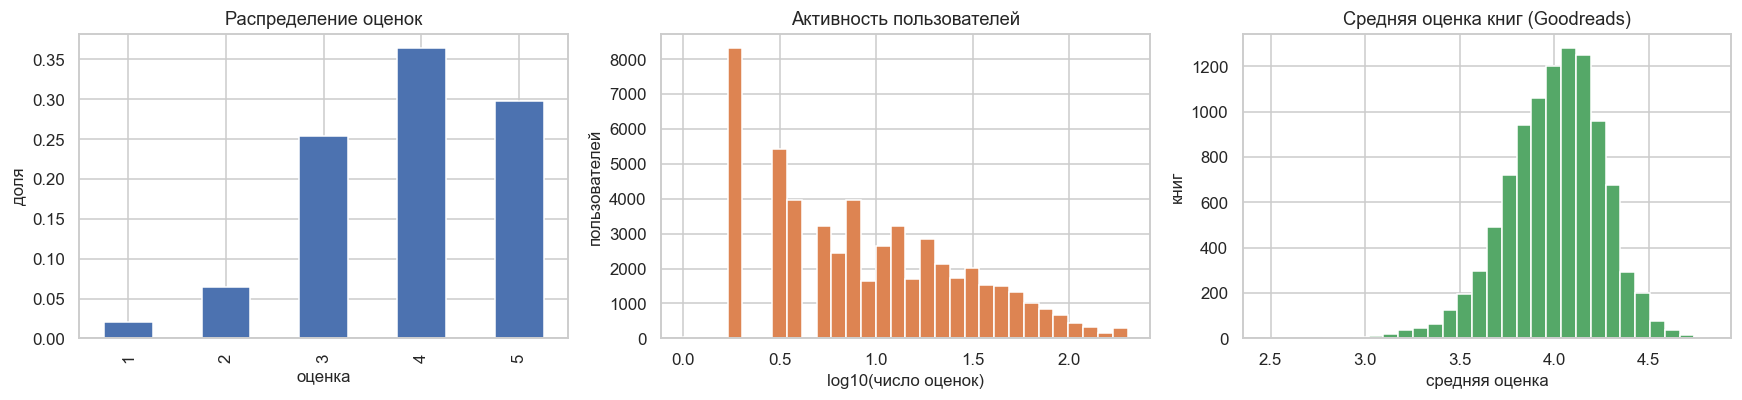

In [26]:
if getattr(pipe, "ds", None) is None:
    pipe.load()
else:
    print("данные уже загружены")
ds = pipe.ds
n_r = len(ds.ratings)
display(pd.Series({"пользователей": ds.n_users, "книг": ds.n_items, "оценок": n_r,
                   "разреженность": 1 - n_r / (ds.n_users * ds.n_items),
                   "доля оценок >= 4": (ds.ratings["rating"] >= 4).mean()}, name="значение").to_frame())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ds.ratings["rating"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color="C0")
ax[0].set(title="Распределение оценок", xlabel="оценка", ylabel="доля")
cnt = ds.ratings.groupby("u").size()
ax[1].hist(np.log10(cnt), bins=30, color="C1", edgecolor="white")
ax[1].set(title="Активность пользователей", xlabel="log10(число оценок)", ylabel="пользователей")
ax[2].hist(ds.books["average_rating"], bins=30, color="C2", edgecolor="white")
ax[2].set(title="Средняя оценка книг (Goodreads)", xlabel="средняя оценка", ylabel="книг")
plt.tight_layout(); plt.show()

Что известно из EDA в ДЗ (графики там, в первом ноутбуке):

- Разреженность около 99.8% и тяжёлый хвост активности: у трети пользователей меньше 5 оценок, а активные (50+) дают 43% всех оценок. Поэтому пользователей имеет смысл делить на типы.
- Оценки смещены к высоким (две трети >= 4), поэтому средняя оценка книги плохо их различает. Релевантной считаем оценку >= 4.
- Популярность внутри выборки неинформативна (не больше 100 оценок на книгу), поэтому Popularity в ДЗ не лучше случайной выдачи.
- Есть локальный сигнал: у 39% понравившихся в test книг тот же автор, что у понравившейся книги из train, у 23% та же серия. Отсюда идея признаков взаимодействия

In [27]:
if getattr(pipe, "splits", None) is None:
    pipe.prepare()
else:
    print("разбиение и признаки уже посчитаны")
sp = pipe.splits
split_tbl = pd.DataFrame({
    "оценок": [len(d) for d in (sp.train_df, sp.val_df, sp.trainval_df, sp.test_df)],
    "релевантных (>=4)": [(d["rating"] >= 4).sum() for d in (sp.train_df, sp.val_df, sp.trainval_df, sp.test_df)],
    "пользователей": [d["u"].nunique() for d in (sp.train_df, sp.val_df, sp.trainval_df, sp.test_df)],
}, index=["train", "val", "trainval", "test"])
split_tbl["доля"] = split_tbl["оценок"] / n_r
display(split_tbl)

[pipeline] 2. разбиение и расширенные признаки ...


[pipeline] 2. разбиение и расширенные признаки: 3.2 c


,оценок,релевантных (>=4),пользователей,доля
train,670163,443158,53424,0.6842
val,106043,70692,45071,0.1083
trainval,776206,513850,53424,0.7925
test,203272,134805,53382,0.2075


# Этап 1. Расширенные признаки

Признаки двух типов (код в К2): статические признаки книг, которые считаются один раз, и признаки по оценкам, которые считаются только по обучающей части, поэтому утечки из test нет.

## 1.1 Тематические категории книг

Ручной словарь жанров не нужен. Матрицу «книга x тег» (1500 самых частых несервисных тегов, вес `log(1+count)`) раскладываем NMF на 20 тем. Каждая тема называется по трём самым характерным тегам, а книга описывается вектором принадлежности темам (сумма равна 1). Так же можно сделать на любых новых данных с тегами

In [28]:
content = pipe.content
main_genre = content.genre.argmax(axis=1)
gtab = pd.DataFrame({"тема (топ-теги)": content.genre_names,
                     "книг, где тема главная": np.bincount(main_genre, minlength=content.n_genres),
                     "средний вес темы": content.genre.mean(axis=0)})
display(gtab.sort_values("книг, где тема главная", ascending=False).reset_index(drop=True))
print("Средняя доля главной темы в профиле книги: %.2f (1.0 - книга целиком в одной теме)" % content.genre.max(axis=1).mean())

,тема (топ-теги),"книг, где тема главная",средний вес темы
0,mystery/crime/thriller,1053,0.0826
1,classics/classic/literature,765,0.0692
2,non-fiction/biography/nonfiction,713,0.0589
3,young-adult/ya/fantasy,597,0.0551
4,non-fiction/nonfiction/psychology,586,0.0553
5,historical-fiction/historical/history,566,0.0642
6,chick-lit/romance/fiction,544,0.0627
7,fantasy/high-fantasy/epic-fantasy,520,0.0561
8,childrens/middle-grade/children,512,0.0344
9,paranormal/urban-fantasy/paranormal-romance,469,0.0453


Средняя доля главной темы в профиле книги: 0.54 (1.0 - книга целиком в одной теме)


## 1.2 Признаки пользователей

По обучающей выборке для каждого пользователя считаем: число оценок и перцентиль активности, среднюю оценку, смещение относительно общей средней, разброс оценок, доли лайков и дизлайков, «мейнстримность» (средняя популярность прочитанных книг по Goodreads), широту вкуса (энтропия тем понравившихся книг), долю книг из серий и повторяемость авторов. По числу оценок пользователь попадает в один из трёх типов: новый (< 5 оценок), обычный (5-29), активный (30+). Типы пригодятся на этапе 2

,доля пользователей,n_ratings,mean_rating,rating_std,like_share,mainstream,genre_entropy,series_share,author_repeat
тип,,,,,,,,,
новые (<5 оценок),0.4388,1.7589,3.8994,0.2152,0.6827,9.4345,0.3504,0.2642,0.0207
обычные (5-29),0.4423,12.2556,3.8623,0.7503,0.6653,9.7150,0.6360,0.4035,0.1529
активные (30+),0.1188,53.4583,3.8496,0.8000,0.6593,10.4796,0.7332,0.4854,0.3069


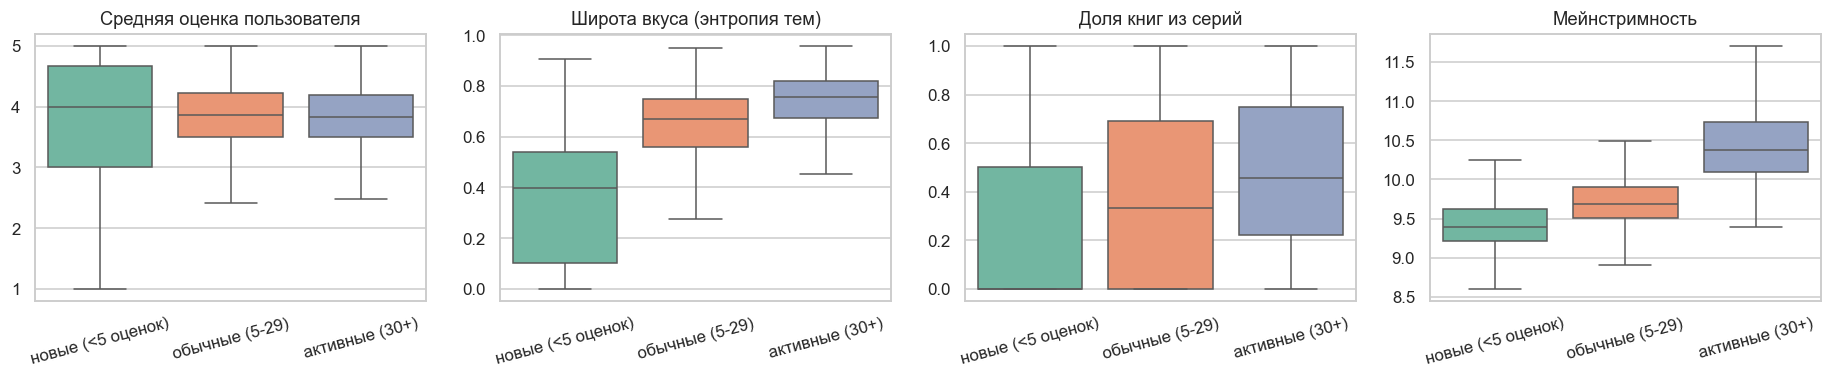

In [29]:
uf = pipe.store_train.user_features.copy()
uf["тип"] = uf["segment"].map(SEGMENT_TITLES)
show = ["n_ratings", "mean_rating", "rating_std", "like_share", "mainstream", "genre_entropy", "series_share", "author_repeat"]
tbl = uf.groupby("тип")[show].mean().loc[[SEGMENT_TITLES[s] for s in range(3)]]
tbl.insert(0, "доля пользователей", uf["тип"].value_counts(normalize=True).reindex(tbl.index))
display(tbl)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
order = [SEGMENT_TITLES[s] for s in range(3)]
for a, col, title in zip(ax, ["mean_rating", "genre_entropy", "series_share", "mainstream"],
                         ["Средняя оценка пользователя", "Широта вкуса (энтропия тем)", "Доля книг из серий", "Мейнстримность"]):
    sns.boxplot(data=uf, x="тип", y=col, order=order, ax=a, showfliers=False, palette="Set2")
    a.set(title=title, xlabel="", ylabel=""); a.tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

Средняя оценка почти одинакова у всех типов (3.85-3.90), доля лайков тоже (0.66-0.68), то есть вкус «в среднем» от активности не зависит. Различается то, насколько информативен профиль. С ростом истории растут разброс оценок (с 0.22 до 0.80, у новичков с 1-2 оценками он мал просто из-за малого числа оценок), широта вкуса (энтропия тем с 0.35 до 0.73), доля книг из серий (с 0.26 до 0.49) и особенно повторяемость авторов (с 0.02 до 0.31). Активные читают и более популярные книги (мейнстримность с 9.4 до 10.5). Получается, что у новичков профиль почти ничего не говорит о вкусе, а у активных он богатый, поэтому для разных типов разумно брать разные комбинации моделей. Доли типов: 44% новые, 44% обычные, 12% активные.

## 1.3 Признаки книг

По обучающей выборке: число оценок и перцентиль популярности, байесовская средняя оценка (сжатая к общей средней, чтобы книга с одной пятёркой не обгоняла остальные), разброс и энтропия распределения оценок («разнообразие оценок»: низкая у книг, которые все оценивают одинаково, высокая у спорных), доля лайков. Из метаданных Goodreads берём логарифм числа оценок, среднюю оценку, энтропию оценок по всему Goodreads и год издания. Плюс тематический профиль из 1.1, автор и серия

,mean,std,min,50%,max
log_n_ratings,4.2122,0.1304,1.9459,4.2341,4.4659
bayes_mean,3.8549,0.2690,2.1782,3.8693,4.7411
rating_std,0.9259,0.1286,0.3774,0.9200,1.7808
rating_entropy,0.7728,0.0843,0.2501,0.7761,0.9882
like_ratio,0.6615,0.1142,0.1248,0.6703,0.9445
log_gr_count,10.1854,0.9369,7.9073,9.9597,15.3801
gr_avg_rating,4.0022,0.2544,2.4700,4.0200,4.8200
gr_rating_entropy,0.7751,0.0750,0.3096,0.7795,0.9920
year,1991.6543,36.4614,1800.0000,2004.0000,2017.0000


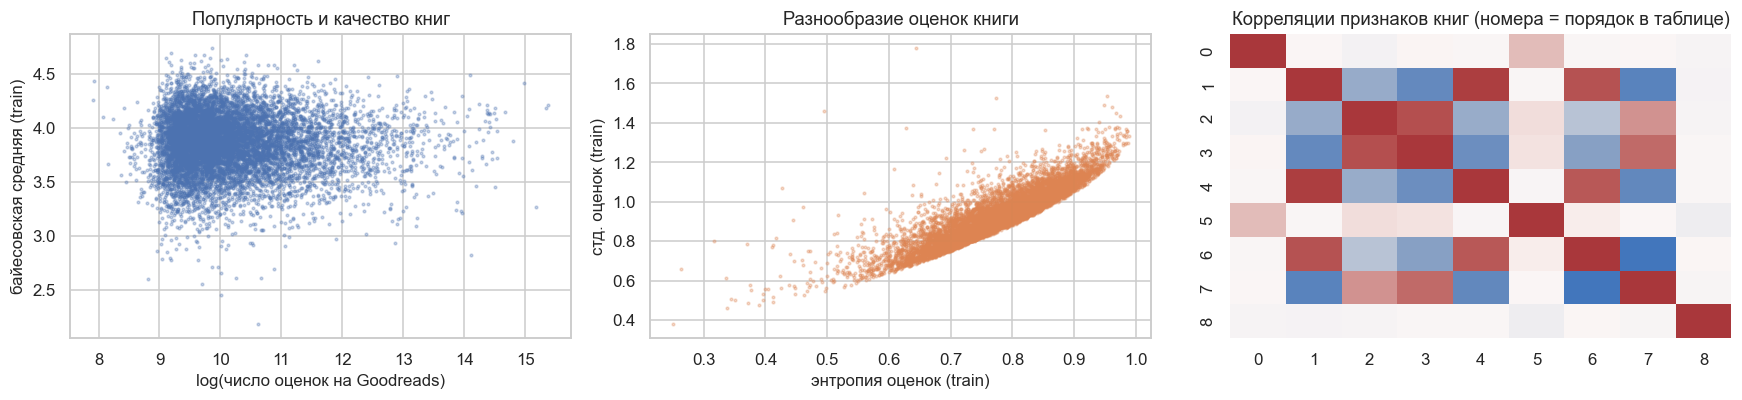

In [30]:
itf = pipe.store_train.item_features
cols = ["log_n_ratings", "bayes_mean", "rating_std", "rating_entropy", "like_ratio", "log_gr_count", "gr_avg_rating", "gr_rating_entropy", "year"]
display(itf[cols].describe().T[["mean", "std", "min", "50%", "max"]])

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].scatter(itf["log_gr_count"], itf["bayes_mean"], s=3, alpha=0.3)
ax[0].set(xlabel="log(число оценок на Goodreads)", ylabel="байесовская средняя (train)", title="Популярность и качество книг")
ax[1].scatter(itf["rating_entropy"], itf["rating_std"], s=3, alpha=0.3, color="C1")
ax[1].set(xlabel="энтропия оценок (train)", ylabel="стд. оценок (train)", title="Разнообразие оценок книги")
corr = itf[cols].corr()
sns.heatmap(corr, ax=ax[2], cmap="vlag", center=0, cbar=False, xticklabels=range(len(cols)), yticklabels=range(len(cols)))
ax[2].set(title="Корреляции признаков книг (номера = порядок в таблице)")
plt.tight_layout(); plt.show()

Число оценок почти не различает книги (log-число оценок 4.21 ± 0.13): потолок в 100 оценок на книгу делает его почти константой, поэтому популярность внутри выборки слабый признак. Байесовская средняя варьируется умеренно (3.85 ± 0.27), доля лайков 0.66 ± 0.11. Метаданные Goodreads информативнее: логарифм числа оценок по всему Goodreads имеет разброс 0.94 (от 7.9 до 15.4), то есть там сохранена настоящая популярность, которая в выборке обрезана. Энтропия оценок у большинства книг около 0.77 (диапазон 0.25-0.99): низкие значения у книг, которые оценивают одинаково, высокие у спорных

## 1.4 Признаки взаимодействий «пользователь, книга»

Для пары (пользователь u, кандидат i) считаем признаки близости к истории пользователя (его лайки в train):

- `same_author_likes`, `same_series_likes`: сколько понравившихся книг написал тот же автор или входит в ту же серию;
- `max_history_sim`: косинус текстовых эмбеддингов до самой близкой понравившейся книги;
- `genre_affinity`: косинус тематического профиля пользователя и книги;
- `pop_gap`: расстояние между популярностью книги и «мейнстримностью» пользователя;
- `item_bias_vs_user`: байесовская средняя книги минус средняя оценка пользователя.

Чтобы проверить, что признаки несут сигнал, берём пары (пользователь, понравившаяся ему в val книга) как положительные и столько же случайных непрочитанных книг как отрицательные, и считаем ROC AUC каждого признака отдельно (0.5 значит, что признак бесполезен)

In [31]:
rng = np.random.default_rng(SEED)
val_pos = sp.val_df[sp.val_df["rating"] >= LIKE_THRESHOLD]
val_pos = val_pos.sample(min(20000, len(val_pos)), random_state=SEED)
neg_i = rng.integers(0, ds.n_items, len(val_pos))
seen_pair = np.asarray(sp.R_train[val_pos["u"].to_numpy(), neg_i]).ravel() > 0
users = np.concatenate([val_pos["u"].to_numpy(), val_pos["u"].to_numpy()[~seen_pair]])
items = np.concatenate([val_pos["i"].to_numpy(), neg_i[~seen_pair]])
labels = np.concatenate([np.ones(len(val_pos)), np.zeros((~seen_pair).sum())])
has_hist = np.asarray(pipe.store_train.likes[users].sum(axis=1)).ravel() > 0         # без истории признаки взаимодействия нулевые
inter = interaction_features(pipe.store_train, users[has_hist], items[has_hist])
lab = labels[has_hist]
auc_tbl = pd.DataFrame({
    "среднее у понравившихся": inter[lab == 1].mean(), "среднее у случайных": inter[lab == 0].mean(),
    "ROC AUC": {c: roc_auc_score(lab, inter[c]) for c in inter.columns}})
display(auc_tbl.sort_values("ROC AUC", ascending=False))

,среднее у понравившихся,среднее у случайных,ROC AUC
max_history_sim,0.7901,0.3552,0.8681
genre_affinity,0.6135,0.2159,0.8624
same_author_likes,1.4200,0.0253,0.6814
same_series_likes,0.6995,0.0053,0.6091
item_bias_vs_user,-0.1325,-0.1762,0.5199
pop_gap,0.4661,0.8764,0.3270


Результат по ROC AUC:

- Лучше всего различают книги текстовая близость к истории `max_history_sim` (0.87) и совпадение тематического профиля `genre_affinity` (0.86).
- `same_author_likes` (0.68) и `same_series_likes` (0.61) по AUC выглядят скромно, потому что отличны от нуля только у небольшой части пар. Но там, где они срабатывают, сигнал сильный: у понравившихся книг в среднем 1.42 понравившихся книги того же автора против 0.03 у случайных. Это тот самый локальный сигнал из EDA.
- У `pop_gap` AUC 0.33, то есть ниже 0.5: признак работает «наоборот» (понравившиеся книги ближе по популярности к привычному для пользователя уровню).
- `item_bias_vs_user` (0.52) почти бесполезен: средняя оценка книги мало говорит о том, понравится ли она. Это согласуется с поведением Popularity в ДЗ.

Как признаки используются дальше:

1. автор и серия стали отдельной моделью гибрида (`AuthorSeriesAffinity`), а текстовая близость и жанры идут в нейросеть и в MMR;
2. признаки пользователей задают тип пользователя (новый, обычный, активный), и от него зависят веса гибрида;
3. признаки книг подаются в книжную башню Two-Tower, признаки пользователей тоже можно подать в пользовательскую, но по абляции в 4.3 это ухудшает качество, поэтому они выключены;
4. приор качества книги (`ItemQualityPrior`) заменяет смещение `b_i` из SVD

# Этап 2. Гибридная система

## 2.1 Компоненты

| Ключ | Модель | Что даёт |
|---|---|---|
| `pop` | Popularity (средняя оценка с порогом) | неперсональный запасной вариант |
| `content` | Content-based (TF-IDF) | работает на книгах без оценок |
| `cf` | Item-based CF (implicit) | лучшая одиночная модель из ДЗ |
| `svd` | SVD (surprise) | оценка качества книги через смещения |
| `pure` | PureSVD (implicit) | глобальные факторы, сильна у активных пользователей |
| `meta` | автор/серия (признаки взаимодействия) | «следующий том серии» |
| `prior` | приор качества книги | неперсональная поправка на качество |
| `neural` | Two-Tower | нейросеть, раздел 4 |

Гиперпараметры моделей из ДЗ взяты как есть (они подбирались там на val): `Item-CF K=10`, `PureSVD f=800`, `SVD f=20`, порог Popularity 40. Для запуска на новых данных в `Pipeline.tune_hyperparams` есть подбор по сетке

In [32]:
print(pd.Series({k: v for k, v in pipe.cfg.params.items()}).to_string())
if getattr(pipe, "models_train", None) is None:
    pipe.fit_train_models()      # все модели на train: нужны для подбора весов и баланса на val
else:
    print("модели на train уже обучены")

popularity       {'strategy': 'mean_rating', 'min_ratings': 40}
item_cf                             {'k': 10, 'shrinkage': 0.0}
svd           {'n_factors': 20, 'n_epochs': 30, 'reg_all': 0...
pure_svd                                     {'n_factors': 800}
[pipeline] 3b. обучение моделей на train ...


[pipeline] 3b. обучение моделей на train: 166.1 c


## 2.2 Стратегии объединения

Взвешенное усреднение. Скоры моделей в разных шкалах, поэтому для каждого пользователя они стандартизуются (z-score по всем книгам), а потом

$$\text{score}(u,i)=c_i\sum_m w_m z_m(u,i)+(1-c_i)\,z_{\text{content}}(u,i),\qquad c_i=\frac{n_i}{n_i+c}.$$

Здесь $c_i$ это доверие к коллаборативным сигналам книги: у книги без оценок $c_i=0$, и её ранжирует только контент. Эта схема взята из ДЗ.

Типы пользователей. Веса $w_m$ подбираем отдельно для новых (< 5 оценок), обычных (5-29) и активных (30+): у новичков коллаборативные модели знают мало, у активных CF и PureSVD работают лучше всего.

Подбор весов. Перебор сетки с шагом 0.1 по 8 моделям это тысячи комбинаций, поэтому используем поиск: старт из чистых моделей, равных весов и случайных точек симплекса, дальше покоординатный локальный поиск. Целевая функция это nDCG@10 на val, для общих весов сумма по типам пользователей в естественных пропорциях. Чтобы не подгонять веса под шум, улучшение принимается только если оно больше `min_gain = 0.0005`, а веса меньше 3% обнуляются. Веса подбираем на моделях, обученных на train, и применяем к моделям, переобученным на train+val.

Сравним четыре варианта гибрида, в каждом следующем добавляется одна идея:

1. Hybrid-1: модели из ДЗ (`pop, svd, pure, cf, content`), общие веса;
2. Hybrid-2: плюс признаки (`meta`, `prior`), общие веса;
3. Hybrid-3: те же компоненты, веса по типам пользователей;
4. Hybrid-4: плюс нейросеть `neural`, веса по типам (и вариант 4a с общими весами)

In [33]:
if getattr(pipe, "weights", None) is None:
    pipe.tune_hybrid()
else:
    print("веса гибрида уже подобраны")
seg_n = {SEGMENT_TITLES[s]: f"{pipe.segment_share[s]:.0%}" for s in pipe.segment_share}
print("Доля типов среди пользователей val (веса общей цели):", seg_n)
display(Markdown("**Качество одиночных моделей на val (nDCG@10, пользователи для подбора весов)**"))
display(pipe.val_single.rename(index=MODEL_TITLES))

[pipeline] 4. подбор весов гибрида (val) ...


[pipeline] 4. подбор весов гибрида (val): 730.8 c


Доля типов среди пользователей val (веса общей цели): {'новые (<5 оценок)': '30%', 'обычные (5-29)': '53%', 'активные (30+)': '18%'}


**Качество одиночных моделей на val (nDCG@10, пользователи для подбора весов)**

,новые (<5 оценок),обычные (5-29),активные (30+),все (взвешенно)
Popularity (mean rating),0.0011,0.0004,0.0009,0.0007
SVD (surprise),0.0008,0.0007,0.0014,0.0009
PureSVD (implicit),0.0827,0.1477,0.1751,0.1334
Item-based CF (implicit),0.1358,0.1645,0.1723,0.1574
Content-based (TF-IDF),0.1021,0.1017,0.0871,0.0992
Author/series affinity,0.0880,0.1121,0.1128,0.1051
Item quality prior,0.0012,0.0003,0.0011,0.0007
Two-Tower (neural),0.1437,0.1399,0.1284,0.1390


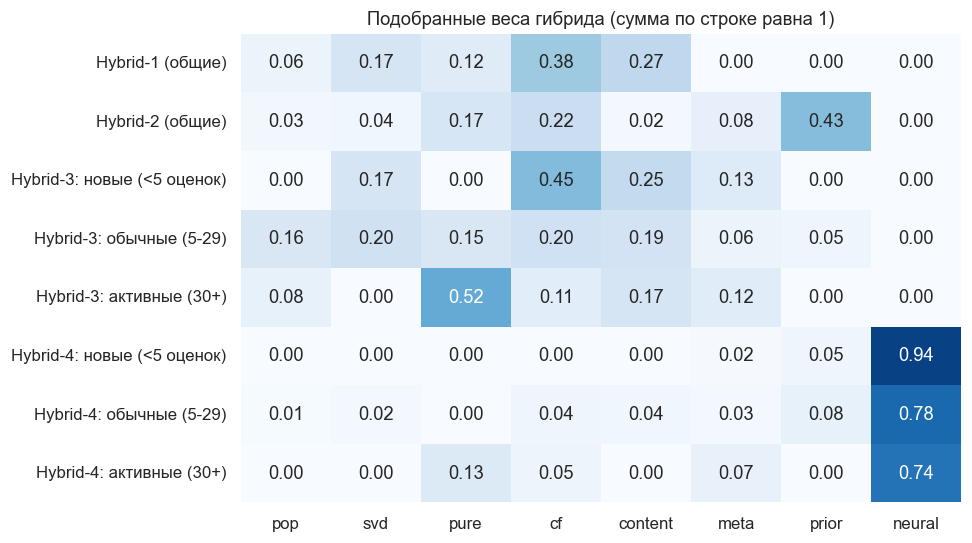

In [34]:
rows = {}
labels_v = {"hw": "Hybrid-1 (общие)", "feat": "Hybrid-2 (общие)", "tt": "Hybrid-4a (общие)"}
for v, lab in labels_v.items():
    if v in pipe.weights:
        rows[lab] = pipe.weights[v][None]
for v, lab in {"feat_seg": "Hybrid-3", "nn_seg": "Hybrid-4"}.items():
    if v in pipe.weights:
        for s in range(3):
            rows[f"{lab}: {SEGMENT_TITLES[s]}"] = pipe.weights[v][s]
W = pd.DataFrame(rows).T.fillna(0.0)
W = W[[c for c in ["pop", "svd", "pure", "cf", "content", "meta", "prior", "neural"] if c in W.columns]]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(W) + 1.5))
sns.heatmap(W, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=1)
ax.set(title="Подобранные веса гибрида (сумма по строке равна 1)")
plt.tight_layout(); plt.show()

Веса надо читать осторожно: z-скоры у разреженных моделей (CF, PureSVD, автор/серия) имеют тяжёлый хвост, а у плотных (нейросеть, контент) ближе к нормальному, поэтому вес отражает и важность модели, и её масштаб. Что всё же видно:

- Hybrid-1: больше всего весов у Item-CF (0.38) и контента (0.27), затем SVD (0.17) и PureSVD (0.12), Popularity получает 0.06.
- Hybrid-3: у новых пользователей PureSVD обнуляется, основную нагрузку несут CF (0.45) и контент (0.25), у активных PureSVD становится главным (0.52). Это согласуется с одиночными моделями: у новичков PureSVD слабая (0.08 nDCG@10 на val против 0.18 у активных).
- Hybrid-4: вес Two-Tower очень большой (0.91 при общих весах, 0.94 / 0.78 / 0.74 по типам), остальное это поправки. У активных ещё PureSVD (0.13), CF (0.05) и автор/серия (0.08).
- Модели, которые сами по себе на уровне случайной выдачи (Popularity, SVD из surprise, приор качества), получают малые или нулевые веса, но не всегда. В общих весах Hybrid-2 приор получил 0.43, хотя выигрыша не дал (раздел 3.1). Значит, вес сам по себе ничего не доказывает, нужна проверка на отложенной выборке.

Вклад компонент в реальную выдачу посчитан в разделе 3.3

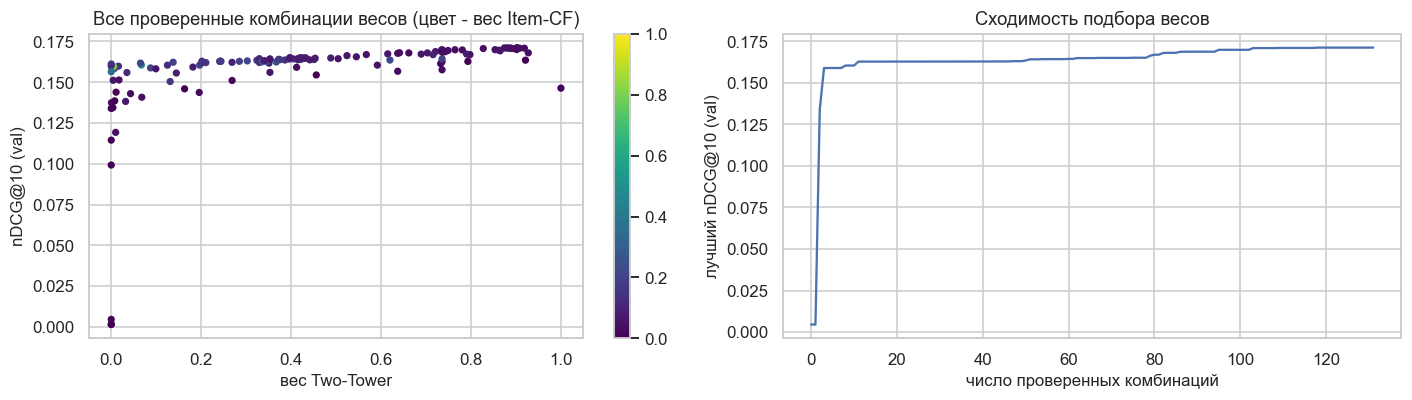

In [35]:
# чувствительность гибрида к весу нейросети и сходимость поиска
key = [k for k in pipe.searches if len(k[0]) == 3 and "neural" in k[1]]
if key:
    hist = pipe.searches[key[0]].history
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    sc = ax[0].scatter(hist["neural"], hist["nDCG@10"], c=hist["cf"], cmap="viridis", s=14)
    ax[0].set(xlabel="вес Two-Tower", ylabel="nDCG@10 (val)", title="Все проверенные комбинации весов (цвет - вес Item-CF)")
    plt.colorbar(sc, ax=ax[0])
    ax[1].plot(hist["nDCG@10"].cummax().values)
    ax[1].set(xlabel="число проверенных комбинаций", ylabel="лучший nDCG@10 (val)", title="Сходимость подбора весов")
    plt.tight_layout(); plt.show()

## 2.3 Генерация кандидатов и балансировка выдачи

Итоговая система (`HybridSystem`) работает в три шага:

1. Единый пул кандидатов. Из каждой модели берём top-N книг (CF 50, PureSVD 30, контент 30, автор/серия 20, Two-Tower 30) и ещё 20 популярных, объединение и есть пул. Прочитанные книги исключаются до формирования пула.
2. Для книг пула считается гибридный скор (веса по типу пользователя).
3. Баланс релевантности и разнообразия: MMR-переранжирование top-50 пула
   $$\arg\max_{i\notin S}\ \lambda\,\widehat{\text{rel}}(i)-(1-\lambda)\max_{j\in S}\cos(e_i,e_j),$$
   где $e_i$ это текстовые эмбеддинги книг, а $\widehat{\text{rel}}$ гибридный скор, приведённый к [0, 1] внутри списка. Дополнительно часть последних позиций можно отдать неперсональному «популярному» (долю подбираем отдельно для каждого типа пользователей). Пользователь без истории получает только популярное.

Параметры выбираются по val по явному правилу: берём наименьшее $\lambda$ (то есть самое сильное разнообразие), при котором nDCG@10 падает не больше чем на 2% от значения без переранжирования. Доля популярного выбирается по типам пользователей по nDCG@10

[pipeline] 5. подбор баланса релевантность / разнообразие (val) ...


[pipeline] 5. подбор баланса релевантность / разнообразие (val): 24.5 c


,λ (1 = без разнообразия),nDCG@10,R@10,ild@10,coverage@10,novelty@10
0,1.0000,0.1670,0.2333,0.3684,0.7977,9.6577
1,0.9000,0.1667,0.2326,0.3928,0.7995,9.6560
2,0.8000,0.1669,0.2332,0.4322,0.8005,9.6548
3,0.7000,0.1661,0.2333,0.4827,0.8039,9.6574
4,0.6000,0.1620,0.2250,0.5370,0.8078,9.6572
5,0.5000,0.1548,0.2164,0.5877,0.8122,9.6564


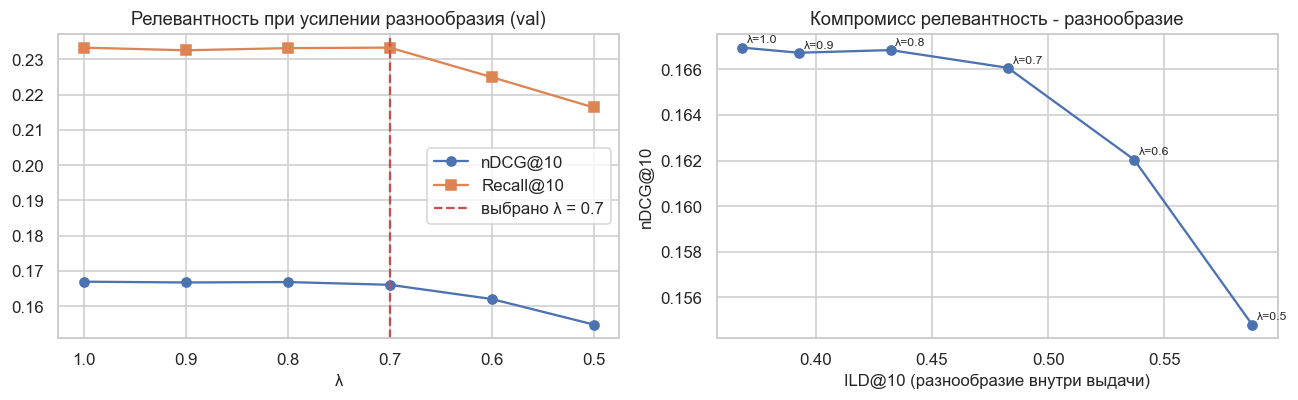

**Доля слотов под популярное** (по типам пользователей, val)

доля популярного,0.0000,0.1000,0.2000
сегмент,,,
активные (30+),0.1692,0.1623,0.1558
новые (<5 оценок),0.1614,0.1588,0.1561
обычные (5-29),0.1676,0.1616,0.1577


Выбрано: {'новые (<5 оценок)': 0.0, 'обычные (5-29)': 0.0, 'активные (30+)': 0.0} | λ = 0.7


In [36]:
if getattr(pipe, "balance_table", None) is None:
    pipe.tune_balance()
else:
    print("баланс уже подобран")
bt = pipe.balance_table
display(bt.rename(columns={"lambda": "λ (1 = без разнообразия)"}))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(bt["lambda"], bt["nDCG@10"], "o-", label="nDCG@10")
ax[0].plot(bt["lambda"], bt["R@10"], "s-", label="Recall@10")
ax[0].axvline(pipe.mmr_lambda, color="r", ls="--", label=f"выбрано λ = {pipe.mmr_lambda}")
ax[0].invert_xaxis(); ax[0].legend(); ax[0].set(xlabel="λ", title="Релевантность при усилении разнообразия (val)")
ax[1].plot(bt["ild@10"], bt["nDCG@10"], "o-")
for _, r in bt.iterrows():
    ax[1].annotate(f"λ={r['lambda']}", (r["ild@10"], r["nDCG@10"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[1].set(xlabel="ILD@10 (разнообразие внутри выдачи)", ylabel="nDCG@10", title="Компромисс релевантность - разнообразие")
plt.tight_layout(); plt.show()
display(Markdown("**Доля слотов под популярное** (по типам пользователей, val)"))
display(pipe.pop_share_table.pivot(index="сегмент", columns="доля популярного", values="nDCG@10"))
print("Выбрано:", {SEGMENT_TITLES[s]: v for s, v in pipe.pop_share.items()}, "| λ =", pipe.mmr_lambda)

# Этап 3. Оценка и оптимизация

Финальное обучение на train+val и оценка на test. Метрики те же, что в ДЗ:

- Precision@K = (число релевантных в top-K) / K;
- Recall@K = (число релевантных в top-K) / (число релевантных у пользователя в test);
- nDCG@K = DCG@K / IDCG@K, $\mathrm{DCG@K}=\sum_{r=1}^{K}\frac{\mathrm{rel}_r}{\log_2(r+1)}$.

Реализация проверена на примерах, посчитанных вручную (раздел К8). Дополнительно считаем метрики выдачи в целом: coverage@K (доля каталога в выдачах), novelty@K (средняя «редкость» книг, $-\log_2 p_i$) и ILD@K (разнообразие внутри выдачи, то есть 1 минус средний косинус эмбеддингов)

In [37]:
if getattr(pipe, "results", None) is None:
    pipe.fit_final()
    pipe.evaluate()
else:
    print("финальные модели и метрики на test уже посчитаны")
results = pipe.results
print("Пользователей в оценке:", int(next(iter(results.values())).summary["n_users"]))

[pipeline] 6. финальное обучение на train+val ...


[pipeline] 6. финальное обучение на train+val: 112.4 c


[pipeline] 7. оценка на test ...


[pipeline] 7. оценка на test: 186.4 c


Пользователей в оценке: 43434


## 3.1 Сравнение гибрида с одиночными моделями

In [38]:
main_cols = ["P@10", "R@10", "nDCG@10", "coverage@10", "novelty@10", "ild@10"]
summary_tbl = results_table(results, main_cols)
display(Markdown("### Сводная таблица (test, K = 10)"))
display(summary_tbl.style.format("{:.4f}").background_gradient(axis=0, subset=["P@10", "R@10", "nDCG@10"], cmap="Greens"))

KS = pipe.cfg.ks
full_tbl = pd.concat({m: pd.DataFrame({name: r.summary for name, r in results.items()}).T[[f"{m}@{k}" for k in KS]]
                      .set_axis([f"K={k}" for k in KS], axis=1) for m in ("P", "R", "nDCG")}, axis=1)
display(Markdown("### Все метрики при K = 5, 10, 20"))
display(full_tbl)

### Сводная таблица (test, K = 10)

,P@10,R@10,nDCG@10,coverage@10,novelty@10,ild@10
Random (reference),0.0004,0.0011,0.0007,0.8691,9.4160,0.8765
Popularity (mean rating),0.0005,0.0016,0.0011,0.0019,9.4102,0.5748
Content-based (TF-IDF),0.0422,0.1645,0.1254,0.9434,9.4147,0.2280
Item-based CF (implicit),0.0752,0.2510,0.2110,0.9830,9.4317,0.4907
PureSVD (implicit),0.0713,0.2105,0.1747,0.8347,9.3924,0.4181
Author/series affinity,0.0483,0.1605,0.1262,0.7410,9.3933,0.5404
Item quality prior,0.0005,0.0016,0.0010,0.0019,9.4140,0.4547
SVD (surprise),0.0005,0.0014,0.0009,0.0036,9.4084,0.4877
Two-Tower (neural),0.0618,0.2317,0.1815,0.9952,9.4663,0.3929
"Hybrid-1: модели ДЗ, общие веса",0.0767,0.2568,0.2136,0.9887,9.4320,0.3841


### Все метрики при K = 5, 10, 20

P                    R                 nDCG              
                                             K=5   K=10   K=20    K=5   K=10   K=20    K=5   K=10   K=20
Random (reference)                        0.0003 0.0004 0.0004 0.0004 0.0011 0.0021 0.0004 0.0007 0.0010
Popularity (mean rating)                  0.0005 0.0005 0.0005 0.0009 0.0016 0.0032 0.0009 0.0011 0.0016
Content-based (TF-IDF)                    0.0588 0.0422 0.0289 0.1232 0.1645 0.2137 0.1133 0.1254 0.1403
Item-based CF (implicit)                  0.1084 0.0752 0.0495 0.1963 0.2510 0.3051 0.1988 0.2110 0.2273
PureSVD (implicit)                        0.1002 0.0713 0.0478 0.1552 0.2105 0.2751 0.1630 0.1747 0.1933
Author/series affinity                    0.0661 0.0483 0.0331 0.1223 0.1605 0.1981 0.1152 0.1262 0.1389
Item quality prior                        0.0005 0.0005 0.0004 0.0008 0.0016 0.0027 0.0007 0.0010 0.0013
SVD (surprise)                            0.0005 0.0005 0.0005 0.0007 0.0014 0.0031 0.0007 0.0009 0.0014
Two-Tower (neural)                        0.0869 0.0618 0.0425 0.1741 0.2317 0.3024 0.1659 0.1815 0.2023
Hybrid-1: модели ДЗ, общие веса           0.1099 0.0767 0.0510 0.1979 0.2568 0.3202 0.2002 0.2136 0.2324
Hybrid-2: + признаки (автор/серия, приор) 0.1099 0.0769 0.0506 0.1965 0.2556 0.3159 0.1996 0.2130 0.2307
Hybrid-3: + веса по сегментам             0.1122 0.0784 0.0519 0.1994 0.2588 0.3207 0.2032 0.2164 0.2346
Hybrid-4a: + Two-Tower, общие веса        0.1137 0.0790 0.0527 0.2078 0.2713 0.3458 0.2095 0.2241 0.2457
Hybrid-4: + Two-Tower, веса по сегментам  0.1161 0.0809 0.0539 0.2109 0.2748 0.3480 0.2132 0.2278 0.2489
Hybrid system (пул + баланс)              0.1173 0.0817 0.0542 0.2117 0.2756 0.3488 0.2143 0.2289 0.2499

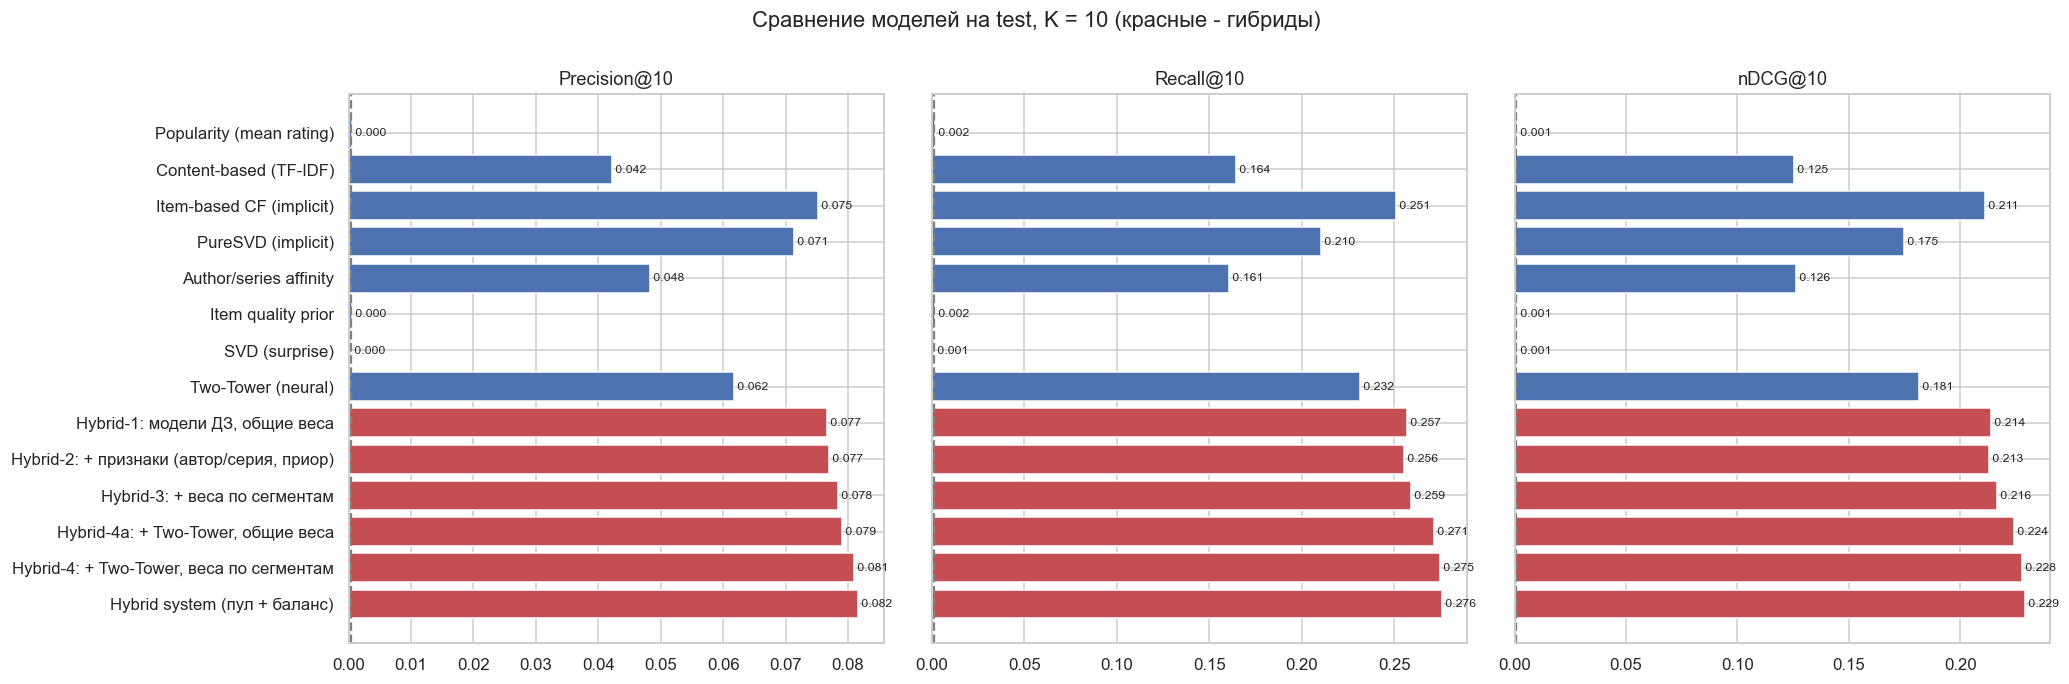

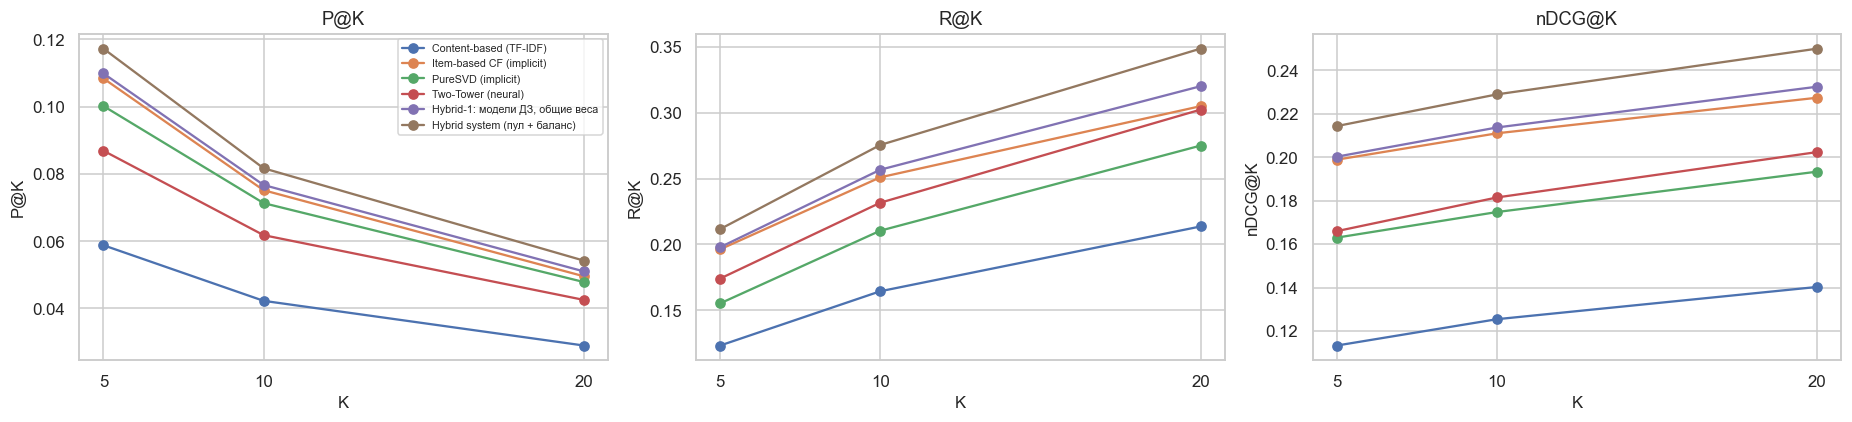

In [39]:
plot_models = [m for m in results if not m.startswith("Random")]
fig, ax = plt.subplots(1, 3, figsize=(19, 6.2))
for a, metric, title in zip(ax, ("P", "R", "nDCG"), ("Precision@10", "Recall@10", "nDCG@10")):
    vals = [results[m].summary[f"{metric}@10"] for m in plot_models]
    colors = ["C3" if m.startswith("Hybrid") else "C0" for m in plot_models]
    bars = a.barh(plot_models, vals, color=colors)
    a.axvline(results["Random (reference)"].summary[f"{metric}@10"], color="gray", ls="--")
    for b, v in zip(bars, vals):
        a.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center", fontsize=8)
    a.set(title=title); a.invert_yaxis()
    if metric != "P": a.set_yticklabels([])
plt.suptitle("Сравнение моделей на test, K = 10 (красные - гибриды)", y=1.0)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
show_models = ["Content-based (TF-IDF)", "Item-based CF (implicit)", "PureSVD (implicit)", "Two-Tower (neural)",
               "Hybrid-1: модели ДЗ, общие веса", "Hybrid system (пул + баланс)"]
for a, metric in zip(ax, ("P", "R", "nDCG")):
    for m in show_models:
        a.plot(KS, [results[m].summary[f"{metric}@{k}"] for m in [m] for k in KS], "o-", label=m)
    a.set(xlabel="K", ylabel=f"{metric}@K", title=f"{metric}@K", xticks=KS)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Одиночные модели делятся на три группы. Первая на уровне случайной выдачи: Popularity, SVD (surprise), приор качества (потолок в 100 оценок на книгу делает популярность и средние оценки неинформативными, это было видно и в ДЗ). Вторая слабые персональные: контент (0.125) и автор/серия (0.126). Третья сильные: PureSVD (0.175), Two-Tower (0.182), Item-CF (0.211). Все гибриды лучше всех одиночных моделей при любом K: Hybrid-1 0.214, Hybrid-3 0.216, Hybrid-4 0.228, итоговая система 0.229 (nDCG@10). Отрыв от лучшей одиночной модели растёт с K: при K = 20 Recall у Item-CF 0.305, у итоговой системы 0.349

### Вклад каждой идеи

Парное сравнение по пользователям (разность метрики и 95% доверительный интервал). Разность считается значимой, если интервал не содержит нуля. Каждый шаг сравниваем с предыдущим и с лучшей одиночной моделью из ДЗ

разность  95% ДИ от  95% ДИ до  значимо
шаг                                                метрика                                         
Hybrid-1: модели ДЗ, общие веса  vs  Item-based... nDCG@10    0.0027     0.0022     0.0032     True
                                                   R@10       0.0058     0.0048     0.0067     True
Hybrid-2: + признаки (автор/серия, приор)  vs  ... nDCG@10   -0.0007    -0.0012    -0.0001     True
                                                   R@10      -0.0012    -0.0022    -0.0002     True
Hybrid-3: + веса по сегментам  vs  Hybrid-2: + ... nDCG@10    0.0034     0.0029     0.0039     True
                                                   R@10       0.0033     0.0023     0.0042     True
Hybrid-4: + Two-Tower, веса по сегментам  vs  H... nDCG@10    0.0114     0.0103     0.0125     True
                                                   R@10       0.0160     0.0141     0.0178     True
Hybrid system (пул + баланс)  vs  Hybrid-4: + T... nDCG@10    0.0011     0.0006     0.0016     True
                                                   R@10       0.0008    -0.0004     0.0019    False
ИТОГО: Hybrid system (пул + баланс)  vs  Item-b... nDCG@10    0.0179     0.0166     0.0192     True
                                                   R@10       0.0246     0.0226     0.0266     True

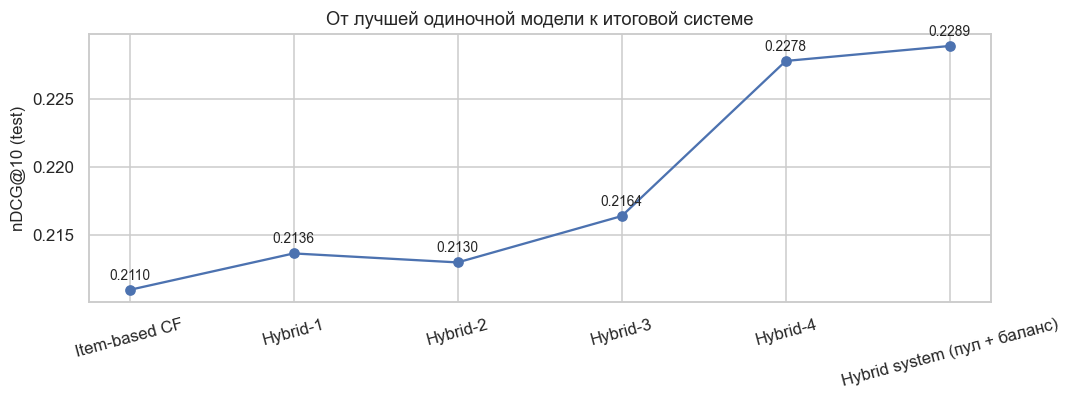

In [40]:
chain = ["Item-based CF (implicit)", "Hybrid-1: модели ДЗ, общие веса", "Hybrid-2: + признаки (автор/серия, приор)",
         "Hybrid-3: + веса по сегментам", "Hybrid-4: + Two-Tower, веса по сегментам", "Hybrid system (пул + баланс)"]
chain = [c for c in chain if c in results]
rows = []
for prev, cur in zip(chain[:-1], chain[1:]):
    for metric in ("nDCG@10", "R@10"):
        d = paired_diff(results[cur], results[prev], metric)
        rows.append({"шаг": f"{cur}  vs  {prev}", "метрика": metric, **d.to_dict()})
for metric in ("nDCG@10", "R@10"):
    d = paired_diff(results[chain[-1]], results[chain[0]], metric)
    rows.append({"шаг": f"ИТОГО: {chain[-1]}  vs  {chain[0]}", "метрика": metric, **d.to_dict()})
display(pd.DataFrame(rows).set_index(["шаг", "метрика"]))

fig, ax = plt.subplots(figsize=(10, 3.8))
vals = [results[c].summary["nDCG@10"] for c in chain]
ax.plot(range(len(chain)), vals, "o-")
for i, v in enumerate(vals):
    ax.annotate(f"{v:.4f}", (i, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(range(len(chain))); ax.set_xticklabels([c.split(":")[0] if c.startswith("Hybrid-") else c.replace(" (implicit)", "") for c in chain], rotation=15)
ax.set(ylabel="nDCG@10 (test)", title="От лучшей одиночной модели к итоговой системе")
plt.tight_layout(); plt.show()

- Hybrid-1 против Item-CF: +0.0027 nDCG@10. Простое смешивание моделей из ДЗ даёт небольшой, но значимый выигрыш.
- Hybrid-2 против Hybrid-1: -0.0007. Добавленные признаки (автор/серия, приор качества) на общих весах не помогли, разница значима, но ничтожна. Как отдельная модель автор/серия полезна (0.126 против 0.125 у контента), а как добавка к смеси сильных моделей ничего не прибавляет.
- Hybrid-3 против Hybrid-2: +0.0034. Разделение по типам пользователей помогает.
- Hybrid-4 против Hybrid-3: +0.0114. Нейросеть даёт самый большой шаг, почти в три раза больше любого другого.
- Итоговая система против Hybrid-4: +0.0011 по nDCG@10, по Recall@10 разница незначима. Балансировка в основном меняет разнообразие, а не релевантность.
- Всего относительно Item-CF: +0.0179 nDCG@10 (интервал 0.0166-0.0192) и +0.0246 Recall@10.

Интервалы учитывают только разброс по пользователям (см. ограничения в конце)

## 3.2 Анализ по сегментам пользователей

**nDCG@10 по типам пользователей (test)**; пользователей в оценке: обычные (5-29) - 21721, новые (<5 оценок) - 14260, активные (30+) - 7453

,новые (<5 оценок),обычные (5-29),активные (30+)
Popularity (mean rating),0.0010,0.0011,0.0015
Content-based (TF-IDF),0.1169,0.1289,0.1317
Item-based CF (implicit),0.1629,0.2187,0.2802
PureSVD (implicit),0.0910,0.1899,0.2907
Author/series affinity,0.0862,0.1378,0.1692
Item quality prior,0.0006,0.0010,0.0016
SVD (surprise),0.0003,0.0010,0.0017
Two-Tower (neural),0.1706,0.1809,0.2040
"Hybrid-1: модели ДЗ, общие веса",0.1655,0.2204,0.2861
"Hybrid-2: + признаки (автор/серия, приор)",0.1635,0.2192,0.2895


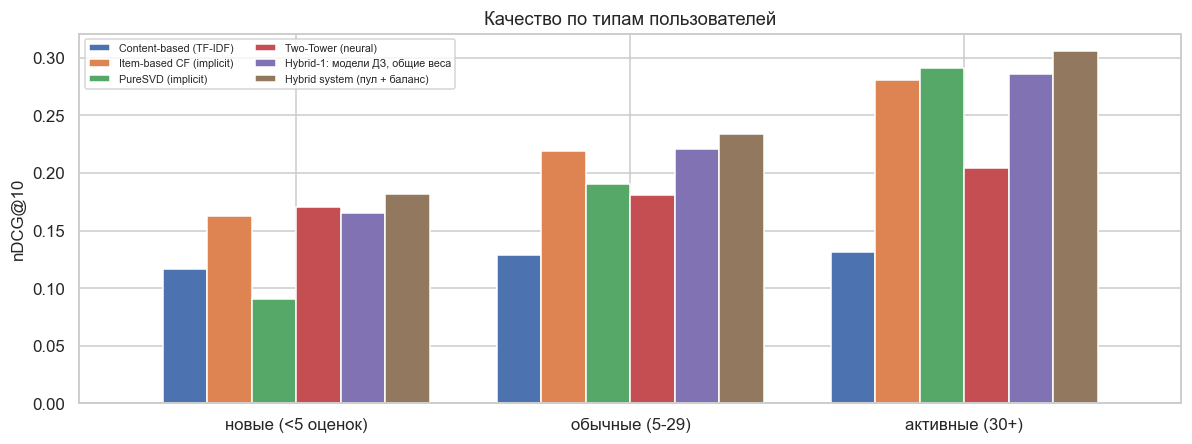

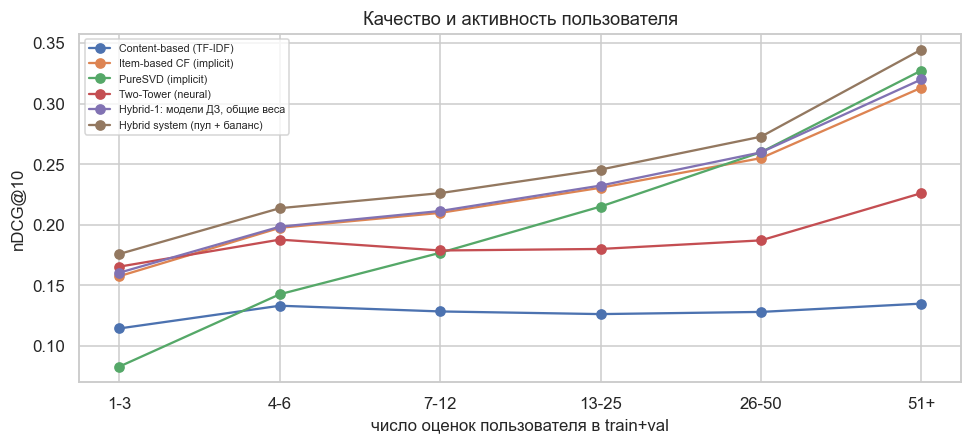

In [41]:
seg_tbl = pipe.metrics_by_segment("nDCG@10")
cnt_by_seg = pd.Series(pipe.store_tv.user_segment[results["Item-based CF (implicit)"].per_user.index]).map(SEGMENT_TITLES).value_counts()
display(Markdown("**nDCG@10 по типам пользователей (test)**; пользователей в оценке: " + ", ".join(f"{k} - {v}" for k, v in cnt_by_seg.items())))
display(seg_tbl.loc[[m for m in seg_tbl.index if not m.startswith("Random")]])

show = ["Content-based (TF-IDF)", "Item-based CF (implicit)", "PureSVD (implicit)", "Two-Tower (neural)",
        "Hybrid-1: модели ДЗ, общие веса", "Hybrid system (пул + баланс)"]
ax = seg_tbl.loc[show].T.plot.bar(figsize=(11, 4.2), rot=0, width=0.8)
ax.set(ylabel="nDCG@10", title="Качество по типам пользователей"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

act_bins = [0, 3, 6, 12, 25, 50, 10**6]; act_labels = ["1-3", "4-6", "7-12", "13-25", "26-50", "51+"]
fig, ax = plt.subplots(figsize=(9, 4.2))
for m in show:
    pu = results[m].per_user
    ax.plot(act_labels, pu.groupby(pd.cut(pu["n_train"], act_bins, labels=act_labels))["nDCG@10"].mean().values, "o-", label=m)
ax.set(xlabel="число оценок пользователя в train+val", ylabel="nDCG@10", title="Качество и активность пользователя")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

По типам пользователей (nDCG@10, test):

- Новые (< 5 оценок): лучшая одиночная модель Two-Tower (0.171), затем Item-CF (0.163). PureSVD слаба (0.091), потому что у неё мало данных для вектора пользователя. Hybrid-4 даёт 0.183 (+12% к Item-CF).
- Обычные (5-29): Item-CF (0.219) лучше Two-Tower (0.181) и PureSVD (0.190), гибрид 0.231-0.234 (+6-7%).
- Активные (30+): лучшая одиночная PureSVD (0.291), Item-CF 0.280, Two-Tower 0.204, гибрид 0.302-0.305 (+9% к Item-CF, +5% к PureSVD).
- Качество всех персональных моделей, кроме контента, растёт с длиной истории: Item-CF с 0.16 до 0.28, автор/серия с 0.09 до 0.17. Контент почти не зависит от типа (0.12-0.13).
- Универсально лучшей модели нет: лидер меняется от Two-Tower (новички) через Item-CF (обычные) к PureSVD (активные). Это обоснование гибрида с весами по типам: Hybrid-3 лучше Hybrid-2 на 0.003 nDCG@10, а по типам выигрыш виден в основном у активных (с 0.290 до 0.299).
- Итоговая система у новичков немного уступает Hybrid-4 (0.182 против 0.183), это цена MMR, а у обычных и активных чуть лучше

## 3.3 Релевантность и разнообразие: что меняет балансировка

,nDCG@10,R@10,ild@10,coverage@10,novelty@10
Item-based CF (implicit),0.2110,0.2510,0.4907,0.9830,9.4317
Content-based (TF-IDF),0.1254,0.1645,0.2280,0.9434,9.4147
Two-Tower (neural),0.1815,0.2317,0.3929,0.9952,9.4663
"Hybrid-4: + Two-Tower, веса по сегментам",0.2278,0.2748,0.3690,0.9787,9.4644
Hybrid system (пул + баланс),0.2289,0.2756,0.4820,0.9819,9.4662


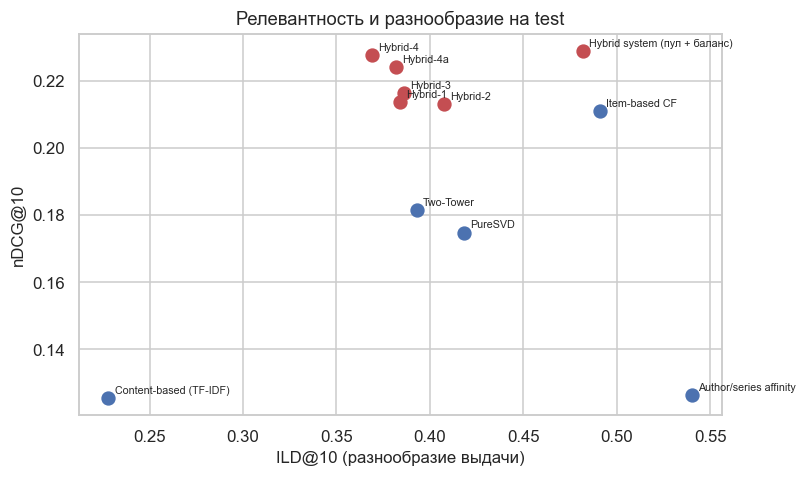

In [42]:
div_cols = ["nDCG@10", "R@10", "ild@10", "coverage@10", "novelty@10"]
cmp_ = ["Item-based CF (implicit)", "Content-based (TF-IDF)", "Two-Tower (neural)",
        "Hybrid-4: + Two-Tower, веса по сегментам", "Hybrid system (пул + баланс)"]
cmp_ = [c for c in cmp_ if c in results]
display(results_table(results, div_cols).loc[cmp_])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for m in results:
    if m.startswith(("Random", "Popularity", "SVD", "Item quality")):
        continue
    s = results[m].summary
    ax.scatter(s["ild@10"], s["nDCG@10"], s=70, color="C3" if m.startswith("Hybrid") else "C0")
    ax.annotate(m.split(":")[0].replace(" (implicit)", "").replace(" (neural)", ""), (s["ild@10"], s["nDCG@10"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set(xlabel="ILD@10 (разнообразие выдачи)", ylabel="nDCG@10", title="Релевантность и разнообразие на test")
plt.tight_layout(); plt.show()

In [43]:
# статистика пула кандидатов: сколько книг в пуле и какую долю релевантных книг test он «захватывает»
rng = np.random.default_rng(SEED)
rel_u = np.unique(sp.test_df.loc[sp.test_df["rating"] >= LIKE_THRESHOLD, "u"])
us = np.sort(rng.choice(rel_u, min(2000, len(rel_u)), replace=False))
seen = sp.R_trainval[us]
pool = pipe.system.pool_mask(us, seen)
rel = to_csr(sp.test_df[sp.test_df["rating"] >= LIKE_THRESHOLD], ds.shape, value=None, dtype=np.int8)[us].toarray() > 0
top50 = pipe.system.hybrid.score(us); top50[seen.toarray() > 0] = -np.inf
t10, t50 = top_k(top50, 10), top_k(top50, 50)
r_ = lambda idx: np.take_along_axis(rel, idx, 1).sum() / rel.sum()
display(pd.Series({"средний размер пула (книг)": pool.sum(1).mean(),
                   "доля релевантных книг test, попавших в пул": (pool & rel).sum() / rel.sum(),
                   "то же для top-10 гибрида": r_(t10), "то же для top-50 гибрида": r_(t50),
                   "доля пула в каталоге": pool.sum(1).mean() / ds.n_items}, name="значение").to_frame())

,значение
средний размер пула (книг),126.2125
"доля релевантных книг test, попавших в пул",0.5246
то же для top-10 гибрида,0.2599
то же для top-50 гибрида,0.4681
доля пула в каталоге,0.0126


Item-CF самая разнообразная одиночная модель (ILD 0.49), контент даёт самые похожие друг на друга книги (0.23), Two-Tower посередине (0.39). У Hybrid-4 самая высокая релевантность, но разнообразие невысокое (0.37): смесь опирается на сильный общий сигнал. Пул кандидатов с MMR (λ = 0.7) возвращает разнообразие на уровень Item-CF (0.48) без потери релевантности (nDCG@10 0.2278 против 0.2289). Покрытие каталога (0.98-0.995) и новизна (9.4-9.5) у всех моделей почти одинаковые, то есть выдача не сводится к узкому набору хитов.

Подбор баланса на val. При λ = 0.7 nDCG@10 почти не падает (0.1661 против 0.1670, минус 0.5%), а ILD растёт с 0.37 до 0.48. При λ = 0.6 потеря уже 3%, поэтому правило «не больше 2%» выбирает 0.7. Доля популярного снижает nDCG для всех типов пользователей (у активных 0.169, 0.162, 0.156 при 0, 10 и 20% популярного), поэтому выбрано 0. Механизм реализован и проверен, но в этих данных популярность не помогает. Пул кандидатов в среднем содержит 126 книг (1.3% каталога) и включает 52% релевантных книг test, тогда как top-50 гибрида покрывает 47%. То есть пул позволяет скорить малую часть каталога и почти ничего не терять

### Из чего складывается скор книг в выдаче

Веса гибрида нельзя сравнивать напрямую, потому что у моделей разный масштаб z-скоров. Поэтому раскладываем гибридный скор книг из top-10 на вклады компонент: для каждой берём $c_i\,w_m z_m(u,i)$ (с нормированным весом сегмента), усредняем по выдаче пользователей сегмента и нормируем на сумму. Так видно, какие модели реально двигают выдачу

In [44]:
hyb = pipe.hybrids["nn_seg" if pipe.cfg.use_neural else "feat_seg"]
z = hyb.components_z(us)
s = np.array(hyb.blend_z(z, us), dtype=np.float32)
s[seen.toarray() > 0] = -np.inf
top = top_k(s, 10)
rows = {}
for sg in range(3):
    r = np.flatnonzero(hyb.segments[us] == sg)
    if not len(r):
        continue
    w = hyb.weights[sg]; tot = sum(v for v in w.values() if v > 0)
    contrib = {k: (np.take_along_axis(z[k][r], top[r], 1) * hyb.conf[top[r]] * v / tot).mean()
               for k, v in w.items() if v > 0 and k in z}
    c = pd.Series(contrib)
    rows[SEGMENT_TITLES[sg]] = c / c.sum()
contrib_tbl = pd.DataFrame(rows).T.fillna(0.0)
display(contrib_tbl.rename(columns=MODEL_TITLES).style.format("{:.0%}").background_gradient(axis=1, cmap="Blues"))

,Item-based CF (implicit),Content-based (TF-IDF),Author/series affinity,Two-Tower (neural),Popularity (mean rating),Item quality prior,PureSVD (implicit),SVD (surprise)
новые (<5 оценок),0%,0%,3%,96%,0%,1%,0%,0%
обычные (5-29),26%,6%,7%,60%,0%,1%,0%,0%
активные (30+),17%,0%,16%,43%,0%,0%,24%,0%


У новых пользователей Two-Tower даёт 96% вклада в скор книг из top-10. У обычных 60% (и Item-CF 26%). У активных вклад распределён шире: Two-Tower 43%, PureSVD 24%, CF 17%, автор/серия 16%. Это согласуется с идеей сегментов: чем длиннее история, тем больше нагрузка на глобальные коллаборативные модели и локальный сигнал серий, а у новичков остаётся в основном нейросеть с контентной частью

## 3.4 Холодный старт книг

Как в ДЗ: случайные 10% каталога полностью убираются из обучения, все модели (включая нейросеть) переобучаются, и ранжируем только эти «новые» книги. Релевантными считаются те, которые пользователь оценил на 4 и выше. Для гибрида сравниваем два варианта работы с книгами без оценок: только контент (как в ДЗ) и смесь контента с нейросетью (у Two-Tower есть контентная башня, обученная с dropout ID-эмбеддинга)

Пользователей в оценке: 26298; книг-кандидатов: 1000; число оценок новых книг в обучении: 0

,P@10,R@10,nDCG@10,coverage@10
Random (reference),0.0023,0.0094,0.0055,1.0000
Popularity (mean rating),0.0028,0.0122,0.0072,0.0100
Content-based (TF-IDF),0.0780,0.3325,0.2573,0.9950
Item-based CF (implicit),0.0028,0.0122,0.0072,0.0100
PureSVD (implicit),0.0023,0.0089,0.0054,0.4150
Author/series affinity,0.0760,0.2731,0.2405,0.7510
Item quality prior,0.0035,0.0145,0.0086,0.0100
SVD (surprise),0.0028,0.0122,0.0072,0.0100
Two-Tower (neural),0.0538,0.2369,0.1551,0.9430
Hybrid-4 (холодные книги: контент),0.0780,0.3325,0.2573,0.9950


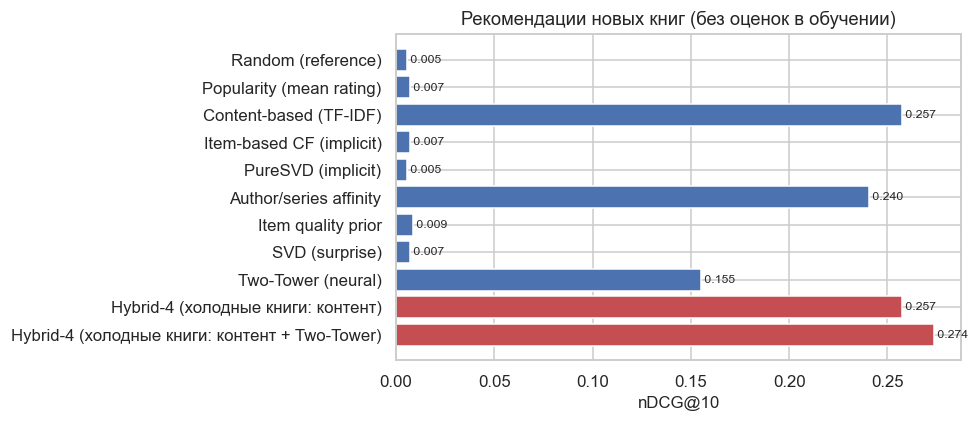

In [45]:
rng = np.random.default_rng(7)
n_cold = max(10, ds.n_items // 10)
cold_items = np.sort(rng.choice(ds.n_items, n_cold, replace=False))
is_cold = np.zeros(ds.n_items, dtype=bool); is_cold[cold_items] = True
warm_df = sp.trainval_df[~is_cold[sp.trainval_df["i"].to_numpy()]]
R_warm = to_csr(warm_df, ds.shape)
store_warm = build_features(ds, warm_df, pipe.content)
cold_ratings = ds.ratings[is_cold[ds.ratings["i"].to_numpy()]]

ncfg = dataclasses.replace(pipe.cfg.neural, epochs=pipe.neural_best_epoch)
models_cold = build_components(pipe.cfg, ds, warm_df, R_warm, store_warm, neural_cfg=ncfg)
counts_warm = np.asarray(R_warm.getnnz(axis=0)).ravel()
wv = "nn_seg" if pipe.cfg.use_neural else "feat_seg"
hyb_a = HybridRecommender(models_cold, pipe.weights[wv], counts_warm, store_warm.user_segment, c=pipe.cfg.conf_c)
cold_models = {MODEL_TITLES[k]: m for k, m in models_cold.items()}
cold_models["Hybrid-4 (холодные книги: контент)"] = hyb_a
if pipe.cfg.use_neural:
    cold_models["Hybrid-4 (холодные книги: контент + Two-Tower)"] = HybridRecommender(
        models_cold, pipe.weights[wv], counts_warm, store_warm.user_segment, c=pipe.cfg.conf_c,
        cold={"content": 0.5, "neural": 0.5})
results_cold = {n: evaluate_ranking(m, R_warm, cold_ratings, ks=KS, candidates=cold_items) for n, m in cold_models.items()}
cold_tbl = results_table(results_cold, ["P@10", "R@10", "nDCG@10", "coverage@10"])
display(Markdown(f"Пользователей в оценке: {int(next(iter(results_cold.values())).summary['n_users'])}; книг-кандидатов: {len(cold_items)}; "
                 f"число оценок новых книг в обучении: {int(counts_warm[cold_items].sum())}"))
display(cold_tbl.style.format("{:.4f}").background_gradient(axis=0, subset=["P@10", "R@10", "nDCG@10"], cmap="Greens"))
fig, ax = plt.subplots(figsize=(9, 4))
vals = cold_tbl["nDCG@10"]
bars = ax.barh(vals.index, vals.values, color=["C3" if i.startswith("Hybrid") else "C0" for i in vals.index])
ax.set(xlabel="nDCG@10", title="Рекомендации новых книг (без оценок в обучении)"); ax.invert_yaxis()
for b, v in zip(bars, vals.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

Модели на оценках здесь бессильны: Item-CF, SVD и Popularity дают nDCG@10 0.007 (у всех нулевые скоры для книг без оценок, порядок получается произвольным), PureSVD 0.005, случайная выдача 0.006. Работают контентные источники: контент 0.257, автор/серия 0.241. Two-Tower как одиночная модель слабее контента (0.155), но гибрид со смесью контент + Two-Tower лучше всех (0.274, +6.5% к одному контенту): нейросеть добавляет сигнал, которого нет у чистого TF-IDF

# 4. Продвинутая часть: нейросеть Two-Tower

## 4.1 Архитектура

Выбрана модель Two-Tower (двухбашенная, с общим пространством эмбеддингов):

```
История лайков пользователя ──► усреднение ID-эмбеддингов ──────┐
                              ► усреднение текстовых эмбеддингов ┴─► MLP ─► вектор пользователя (64, L2-норма) ─┐
                                                                                                                  ├─► cos / τ
ID книги ─► ID-эмбеддинг (с dropout) ┐                                                                            │
Текстовый эмбеддинг книги (SVD от TF-IDF) ├─► MLP ─► вектор книги (64, L2-норма) ─────────────────────────────────┘
Признаки книги (10 шт.) + тематический профиль ┘
```

- Башня пользователя не хранит вектор в таблице, а строит его из истории лайков (ID и текстовые эмбеддинги книг, усреднение). Новому пользователю достаточно передать его лайки, переобучать модель не нужно. Числовые признаки пользователя (9 шт., этап 1) можно подключить флагом `feat_user`, но абляция в 4.3 показала, что они ухудшают качество, поэтому в итоговой модели выключены.
- Башня книги использует ID-эмбеддинг, контент и числовые признаки книги (популярность, байесовская средняя, энтропия оценок, метаданные Goodreads, тематический профиль). С вероятностью 0.3 ID-эмбеддинг при обучении обнуляется, так башня учится работать по контенту и признакам, и это помогает на книгах без оценок.
- Обучение. Берём пары (пользователь, понравившаяся книга), целевую книгу вырезаем из истории (иначе сеть подсматривает ответ), 30% оставшейся истории случайно скрываем (history dropout). Лосс это softmax по книгам из других пар батча (in-batch negatives) с logQ-коррекцией частот, температура 0.07, оптимизатор Adam, косинусное расписание lr.
- Инференс. Векторы книг считаются один раз, скоры пользователя это одно матричное произведение, поэтому эмбеддинги можно положить в ANN-индекс.
- Число эпох выбираем по nDCG@10 на val, финальную модель на train+val обучаем с найденным числом эпох

## 4.2 Обучение

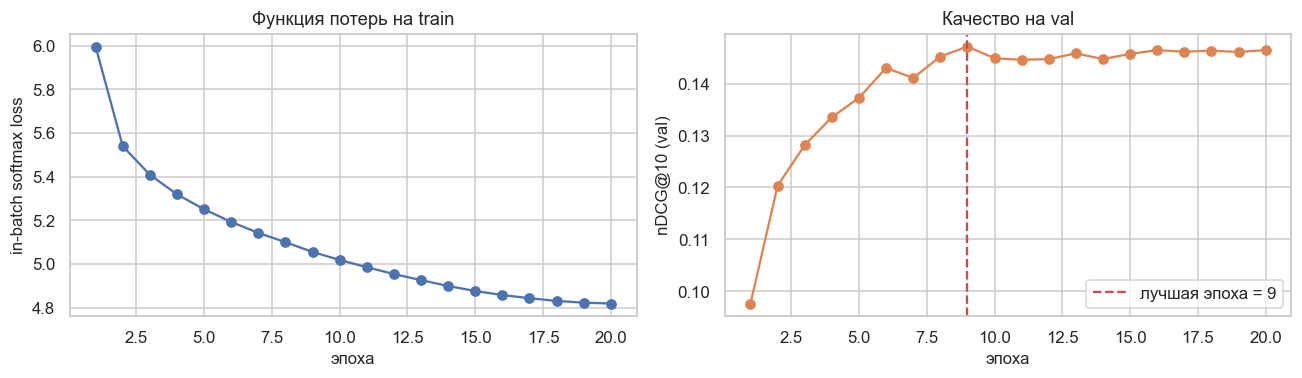

Параметров в модели: 1386688


In [46]:
hist = pipe.neural_history
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(hist["epoch"], hist["loss"], "o-"); ax[0].set(xlabel="эпоха", ylabel="in-batch softmax loss", title="Функция потерь на train")
ax[1].plot(hist["epoch"], hist["val_nDCG@10"], "o-", color="C1")
ax[1].axvline(pipe.neural_best_epoch, color="r", ls="--", label=f"лучшая эпоха = {pipe.neural_best_epoch}")
ax[1].set(xlabel="эпоха", ylabel="nDCG@10 (val)", title="Качество на val"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Параметров в модели:", sum(p.numel() for p in pipe.models["neural"].net.parameters()))

Лучшая эпоха по nDCG@10 на val девятая, дальше качество не растёт, поэтому финальная модель на train+val обучается 9 эпох. В сети около 1.39 млн параметров

## 4.3 Абляция: что даёт контент и признаки

Обучаем варианты сети на train с тем же числом эпох, что у итоговой модели, и сравниваем на одной и той же выборке val-пользователей (3000 человек). Показаны лучшая и последняя эпохи, чтобы было видно и потенциал варианта, и его устойчивость

,"nDCG@10 (val, лучшая эпоха)",эпоха,"nDCG@10 (val, последняя эпоха)","время, с"
только ID (история + ID книги),0.1198,20,0.1198,167.8843
ID + контент,0.1325,15,0.1319,187.1328
ID + контент + признаки книг (боевая модель),0.1328,18,0.1325,209.0659
ID + контент + признаки пользователей,0.1208,18,0.1204,185.2042
ID + контент + признаки обеих башен,0.1196,19,0.1191,186.9635
контент + признаки книг (без ID),0.0995,15,0.0982,121.0188


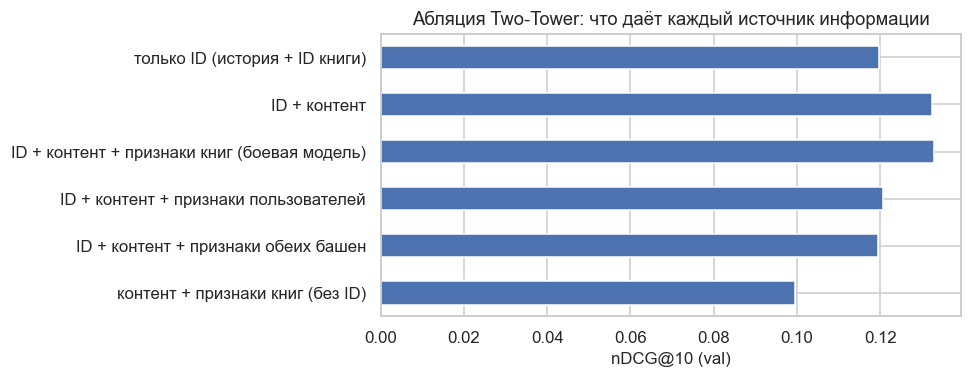

In [47]:
rel_val = np.unique(sp.val_df.loc[sp.val_df["rating"] >= LIKE_THRESHOLD, "u"])
ev_abl = FastEvaluator(sp.R_train, sp.val_df, np.sort(np.random.default_rng(1).choice(rel_val, min(3000, len(rel_val)), replace=False)))
E = pipe.cfg.neural.epochs          # то же число эпох, что у итоговой модели
base = dataclasses.replace(pipe.cfg.neural, epochs=E)
variants = {
    "только ID (история + ID книги)": dataclasses.replace(base, use_content=False, use_features=False),
    "ID + контент": dataclasses.replace(base, use_features=False),
    "ID + контент + признаки книг (боевая модель)": base,
    "ID + контент + признаки пользователей": dataclasses.replace(base, feat_user=True, feat_item=False),
    "ID + контент + признаки обеих башен": dataclasses.replace(base, feat_user=True, feat_item=True),
    "контент + признаки книг (без ID)": dataclasses.replace(base, use_id=False),
}
rows = {}
for name, vcfg in variants.items():
    t0 = time.time()
    m = TwoTowerRecommender(vcfg).fit(sp.R_train, pipe.store_train, evaluator=ev_abl)
    curve = [r["val_nDCG@10"] for r in m.history_]
    rows[name] = {"nDCG@10 (val, лучшая эпоха)": max(curve), "эпоха": int(np.argmax(curve)) + 1,
                  "nDCG@10 (val, последняя эпоха)": curve[-1], "время, с": time.time() - t0}
abl = pd.DataFrame(rows).T
abl["эпоха"] = abl["эпоха"].astype(int)
display(abl)
fig, ax = plt.subplots(figsize=(9, 3.6))
abl["nDCG@10 (val, лучшая эпоха)"].iloc[::-1].plot.barh(ax=ax, color="C0")
ax.set(xlabel="nDCG@10 (val)", title="Абляция Two-Tower: что даёт каждый источник информации")
plt.tight_layout(); plt.show()

Выводы по nDCG@10 на val:

- Контент даёт главный прирост: ID-эмбеддинги без контента дают 0.120, с текстовыми эмбеддингами книг 0.133 (+10%).
- Признаки книг почти ничего не меняют: 0.1328 против 0.1325 без них, это в пределах шума. Мы оставили их в модели, потому что они не вредят.
- Признаки пользователей вредят: с ними nDCG падает до 0.121 (с признаками обеих башен 0.120). История лайков уже кодирует вкус пользователя, а добавленные агрегаты, скорее всего, дают сети лёгкий путь к переобучению. Поэтому `feat_user` выключен, и это решение принято по абляции.
- Без ID-эмбеддинга (только контент и признаки книг) качество 0.100, то есть около 75% от полной модели. Контентный путь работает сам по себе, но ID добавляет точности на известных книгах. Именно такая часть сети работает на книгах без оценок (раздел 3.4).
- Лучшая эпоха у большинства вариантов 15-20, а значения на лучшей и последней эпохе почти совпадают, так что обучение стабильное

## 4.4 Что выучила сеть

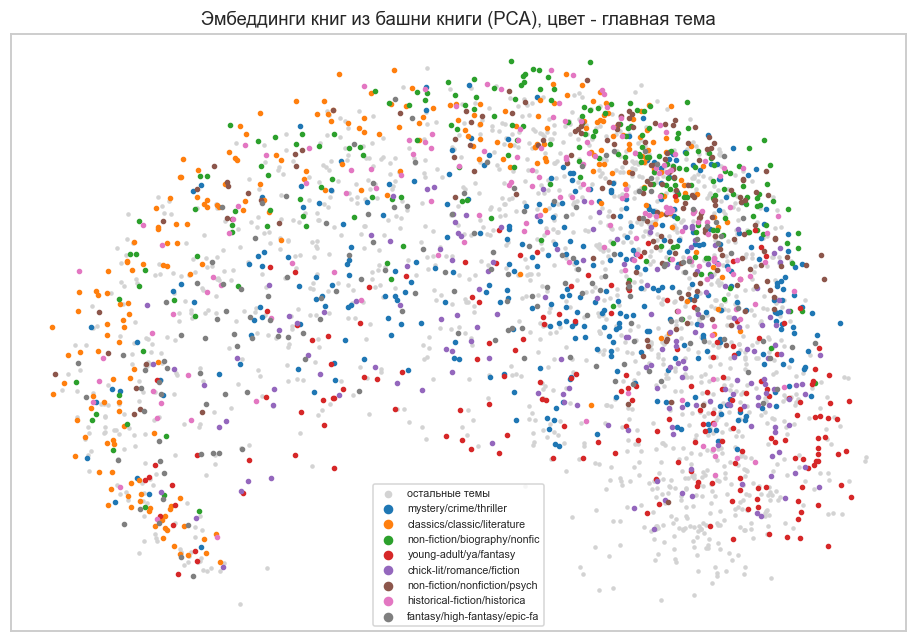

**Ближайшие по Two-Tower к «The Hunger Games (The Hunger Games, #1)»**

,title,authors,cos
0,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.9829
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",0.9758
2,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.9745
3,The Hobbit,J.R.R. Tolkien,0.9685
4,Water for Elephants,Sara Gruen,0.9671


**Ближайшие по Two-Tower к «Harry Potter and the Sorcerer's Stone (Harry Potter, #1)»**

,title,authors,cos
0,The Hobbit,J.R.R. Tolkien,0.9786
1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,0.9758
2,To Kill a Mockingbird,Harper Lee,0.9743
3,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,0.9717
4,Charlotte's Web,"E.B. White, Garth Williams, Rosemary Wells",0.9695


**Ближайшие по Two-Tower к «Pride and Prejudice»**

,title,authors,cos
0,Jane Eyre,"Charlotte Brontë, Michael Mason",0.9815
1,The Diary of a Young Girl,"Anne Frank, Eleanor Roosevelt, B.M. Mooyaart-D...",0.9769
2,Sense and Sensibility,"Jane Austen, Tony Tanner, Ros Ballaster",0.9766
3,Gone with the Wind,Margaret Mitchell,0.9762
4,To Kill a Mockingbird,Harper Lee,0.9742


In [48]:
tt = pipe.models["neural"]
iv = tt.item_vecs_.numpy()
n_pts = min(3000, ds.n_items)
sel = np.random.default_rng(0).choice(ds.n_items, n_pts, replace=False)
xy = PCA(2, random_state=0).fit_transform(iv[sel])
top_genres = pd.Series(main_genre[sel]).value_counts().index[:8]
fig, ax = plt.subplots(figsize=(8.5, 6))
other = ~np.isin(main_genre[sel], top_genres)
ax.scatter(xy[other, 0], xy[other, 1], s=4, color="lightgray", label="остальные темы")
for g, c in zip(top_genres, sns.color_palette("tab10", 8)):
    m = main_genre[sel] == g
    ax.scatter(xy[m, 0], xy[m, 1], s=7, color=c, label=content.genre_names[g][:28])
ax.legend(fontsize=7, markerscale=2); ax.set(title="Эмбеддинги книг из башни книги (PCA), цвет - главная тема", xticks=[], yticks=[])
plt.tight_layout(); plt.show()

def similar_by_neural(item: int, n: int = 5) -> pd.DataFrame:
    sims = iv @ iv[item]; sims[item] = -np.inf
    idx = np.argsort(-sims)[:n]
    return ds.books.loc[idx, ["title", "authors"]].assign(cos=sims[idx]).reset_index(drop=True)

for prefix in ["The Hunger Games", "Harry Potter and the Sorcerer's Stone", "Pride and Prejudice"]:
    hit = ds.books.index[ds.books["title"].str.startswith(prefix)]
    item = int(hit[0]) if len(hit) else int(ds.books["ratings_count"].idxmax())
    display(Markdown(f"**Ближайшие по Two-Tower к «{ds.books.loc[item, 'title']}»**"))
    display(similar_by_neural(item))

## 4.5 Интеграция в гибрид и сравнение с классическими методами

Нейросеть добавлена в гибрид как ещё одна компонента (стандартизованный скор, веса подбираются на val, как у остальных), а её top-30 включён в пул кандидатов. Результаты на test есть в таблицах раздела 3.1, ниже сводка по нейросети

In [49]:
nn_rows = ["Content-based (TF-IDF)", "PureSVD (implicit)", "Two-Tower (neural)", "Item-based CF (implicit)",
           "Hybrid-3: + веса по сегментам", "Hybrid-4: + Two-Tower, веса по сегментам", "Hybrid system (пул + баланс)"]
display(results_table(results, ["P@10", "R@10", "nDCG@10", "ild@10", "coverage@10"]).loc[nn_rows])
rows = []
for a, b in [("Two-Tower (neural)", "Content-based (TF-IDF)"), ("Two-Tower (neural)", "PureSVD (implicit)"),
             ("Two-Tower (neural)", "Item-based CF (implicit)"),
             ("Hybrid-4: + Two-Tower, веса по сегментам", "Hybrid-3: + веса по сегментам"),
             ("Hybrid-4: + Two-Tower, веса по сегментам", "Item-based CF (implicit)")]:
    rows.append({"сравнение": f"{a}  -  {b}", **paired_diff(results[a], results[b], "nDCG@10").to_dict()})
display(pd.DataFrame(rows).set_index("сравнение"))

,P@10,R@10,nDCG@10,ild@10,coverage@10
Content-based (TF-IDF),0.0422,0.1645,0.1254,0.2280,0.9434
PureSVD (implicit),0.0713,0.2105,0.1747,0.4181,0.8347
Two-Tower (neural),0.0618,0.2317,0.1815,0.3929,0.9952
Item-based CF (implicit),0.0752,0.2510,0.2110,0.4907,0.9830
Hybrid-3: + веса по сегментам,0.0784,0.2588,0.2164,0.3860,0.9881
"Hybrid-4: + Two-Tower, веса по сегментам",0.0809,0.2748,0.2278,0.3690,0.9787
Hybrid system (пул + баланс),0.0817,0.2756,0.2289,0.4820,0.9819


,разность,95% ДИ от,95% ДИ до,значимо
сравнение,,,,
Two-Tower (neural) - Content-based (TF-IDF),0.0560,0.0540,0.0581,True
Two-Tower (neural) - PureSVD (implicit),0.0067,0.0045,0.0089,True
Two-Tower (neural) - Item-based CF (implicit),-0.0295,-0.0315,-0.0275,True
"Hybrid-4: + Two-Tower, веса по сегментам - Hybrid-3: + веса по сегментам",0.0114,0.0103,0.0125,True
"Hybrid-4: + Two-Tower, веса по сегментам - Item-based CF (implicit)",0.0168,0.0155,0.0181,True


Как одиночная модель сеть (nDCG@10 0.182) лучше PureSVD (0.175) и контента (0.125), но хуже Item-CF (0.211), все разности значимы. Зато у неё лучшее покрытие каталога (0.995 против 0.983 у Item-CF), и из тяжёлых моделей она сильнее всех у новичков. Главный эффект виден в гибриде: Hybrid-4 лучше Hybrid-3 на 0.011 nDCG@10 и лучше Item-CF на 0.017. Нейросеть и классические модели ошибаются по-разному, поэтому в смеси они дополняют друг друга

In [50]:
# качественный пример: один и тот же пользователь, рекомендации разных моделей
u_demo = int(np.flatnonzero(sp.R_trainval.getnnz(axis=1) >= 30)[3]) if (sp.R_trainval.getnnz(axis=1) >= 30).sum() > 3 else int(sp.R_trainval.getnnz(axis=1).argmax())
uid = int(ds.user_ids[u_demo])
liked = sp.trainval_df[(sp.trainval_df["u"] == u_demo) & (sp.trainval_df["rating"] == 5)].head(8)
display(Markdown(f"**Пользователь {uid}**: любимые книги (оценка 5), первые 8"))
display(ds.books.loc[liked["i"], ["title", "authors"]].reset_index(drop=True))
for name, model in [("Item-based CF (implicit)", pipe.models["cf"]), ("Two-Tower", pipe.models.get("neural")),
                    ("Итоговая система", pipe.system)]:
    if model is None:
        continue
    rec = model.rank(np.array([u_demo]), 5, sp.R_trainval[[u_demo]])[0] if hasattr(model, "rank") else model.recommend(np.array([u_demo]), 5, sp.R_trainval)[0]
    display(Markdown(f"*{name}*"))
    display(ds.books.loc[rec, ["title", "authors"]].reset_index(drop=True))

**Пользователь 41**: любимые книги (оценка 5), первые 8

,title,authors
0,"Prodigy (Legend, #2)",Marie Lu
1,"Cress (The Lunar Chronicles, #3)",Marissa Meyer
2,"Tempted (House of Night, #6)","P.C. Cast, Kristin Cast"
3,"Lover Awakened (Black Dagger Brotherhood, #3)",J.R. Ward
4,"The Throne of Fire (Kane Chronicles, #2)",Rick Riordan
5,"Linger (The Wolves of Mercy Falls, #2)",Maggie Stiefvater
6,"Champion (Legend, #3)",Marie Lu
7,"Reached (Matched, #3)",Ally Condie


*Item-based CF (implicit)*

,title,authors
0,"For a Few Demons More (The Hollows, #5)",Kim Harrison
1,"The Never War (Pendragon, #3)",D.J. MacHale
2,"The Reality Bug (Pendragon, #4)",D.J. MacHale
3,"Every Which Way But Dead (The Hollows, #3)",Kim Harrison
4,"Raven Rise (Pendragon, #9)",D.J. MacHale


*Two-Tower*

,title,authors
0,"A Perfect Blood (The Hollows, #10)",Kim Harrison
1,Gregor and the Code of Claw (Underland Chronic...,Suzanne Collins
2,"For a Few Demons More (The Hollows, #5)",Kim Harrison
3,Gregor and the Marks of Secret (Underland Chro...,Suzanne Collins
4,"River Marked (Mercy Thompson, #6)",Patricia Briggs


*Итоговая система*

,title,authors
0,"A Perfect Blood (The Hollows, #10)",Kim Harrison
1,"The Never War (Pendragon, #3)",D.J. MacHale
2,"For a Few Demons More (The Hollows, #5)",Kim Harrison
3,"The Reality Bug (Pendragon, #4)",D.J. MacHale
4,"Raven Rise (Pendragon, #9)",D.J. MacHale


# 5. Сквозной пайплайн

Весь процесс оформлен как класс `Pipeline` с параметрами в `PipelineConfig`. Этапы идут строго по порядку, и именно их мы вызывали выше по одному:

```
load()              загрузка и проверка схемы CSV, очистка            ─┐
prepare()           разбиение 70/10/20, признаки (книги, пользователи) │ предобработка
fit_train_models()  обучение моделей на train                          │ обучение
tune_hybrid()       подбор весов по типам пользователей (val)          │
tune_balance()      выбор λ (MMR) и доли популярного (val)            ─┘
fit_final()         переобучение на train+val, сборка HybridSystem    ─  генерация рекомендаций
evaluate()          Precision / Recall / nDCG, разнообразие, сегменты ─  оценка качества
export()            рекомендации, метрики, веса, конфигурация, время  ─  артефакты
```

`Pipeline.run()` выполняет всё сразу, `pipe.recommend(user_id, n)` отдаёт рекомендации:

```python
pipe = Pipeline(PipelineConfig(data_dir="data", out_dir="artifacts/run1")).run()   # весь процесс
pipe.recommend(user_id=1, n=10)                                                    # рекомендации итоговой системы
```

Перезапуск на новых данных. Достаточно указать другую папку с `ratings.csv`, `books.csv`, `tags.csv`, `book_tags.csv` в формате Goodbooks-10k: схема проверяется при загрузке, а разбиение, признаки, обучение, подбор весов и оценка выполняются заново. Ничего не зашито под конкретные данные, весь случайный выбор зафиксирован `seed`. Ниже этапы сохраняют артефакты, а затем весь пайплайн запускается заново на другом (синтетическом) наборе данных

[pipeline] 8. экспорт результатов ...


[pipeline] 8. экспорт результатов: 2.5 c


,файл,"размер, КБ"
0,config.json,1.2000
1,hybrid_weights.json,1.9000
2,metrics_by_segment_ndcg10.csv,1.4000
3,metrics_test.csv,3.9000
4,recommendations.csv,1374.2000
5,report.json,1.3000


,user_id,rank,book_id,title,authors
0,1,1,4769,The Bastard of Istanbul,Elif Shafak
1,1,2,6898,The Happy Prince,Oscar Wilde
2,1,3,6885,"Geisha, a Life","Mineko Iwasaki, Rande Brown"
3,1,4,5335,The Palace of Illusions,Chitra Banerjee Divakaruni
4,1,5,3493,"Many Lives, Many Masters: The True Story of a ...",Brian L. Weiss
5,1,6,6772,رباعيات خيام,"Omar Khayyám, محمدعلی فروغی, قاسم غنی"
6,1,7,3928,When Nietzsche Wept,Irvin D. Yalom
7,1,8,7433,Looking for Alibrandi,Melina Marchetta
8,1,9,2902,The Fifth Mountain,Paulo Coelho
9,1,10,8857,Revolting Rhymes,"Roald Dahl, Quentin Blake"


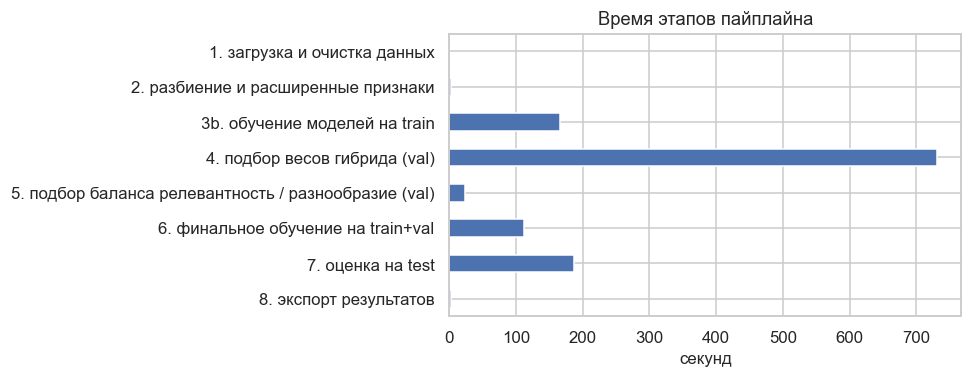

In [51]:
pipe.export()
out = Path(pipe.cfg.out_dir)
display(pd.DataFrame({"файл": sorted(p.name for p in out.iterdir()),
                      "размер, КБ": [round(p.stat().st_size / 1024, 1) for p in sorted(out.iterdir())]}))
display(pd.read_csv(out / "recommendations.csv").head(10))

tm = pd.Series(pipe.timings)
fig, ax = plt.subplots(figsize=(9, 3.6))
tm.iloc[::-1].plot.barh(ax=ax, color="C0"); ax.set(xlabel="секунд", title="Время этапов пайплайна")
plt.tight_layout(); plt.show()

In [52]:
# перезапуск всего пайплайна на новых данных: другой набор (синтетический, другой размер и другие id)
import tempfile
tmp = Path(tempfile.mkdtemp())
synthetic_dataset(tmp / "data", n_users=400, n_books=200, seed=5)
cfg2 = PipelineConfig(
    data_dir=str(tmp / "data"), out_dir=str(tmp / "out"), seed=1,
    params={"popularity": {"strategy": "mean_rating", "min_ratings": 3}, "item_cf": {"k": 5, "shrinkage": 0.0},
            "svd": {"n_factors": 5, "n_epochs": 5, "reg_all": 0.1, "random_state": 0}, "pure_svd": {"n_factors": 30}},
    neural=TwoTowerConfig(epochs=4, batch_size=256, hidden=32, emb_dim=16, out_dim=16, hist_len=20),
    n_topics=6, emb_dim=16, tune_users_per_segment=80, search_random=4, search_sweeps=1, n_export_users=100)
t0 = time.time()
pipe2 = Pipeline(cfg2, verbose=False).run()
print(f"Пайплайн на новых данных выполнен за {time.time() - t0:.0f} с: {pipe2.ds.n_users} пользователей, {pipe2.ds.n_items} книг")
display(results_table(pipe2.results, ["P@10", "R@10", "nDCG@10"]).loc[
    ["Random (reference)", "Item-based CF (implicit)", "Two-Tower (neural)", "Hybrid system (пул + баланс)"]])
display(pipe2.recommend(int(pipe2.ds.user_ids[0]), 5))

Пайплайн на новых данных выполнен за 1 с: 400 пользователей, 200 книг


,P@10,R@10,nDCG@10
Random (reference),0.0123,0.0639,0.0334
Item-based CF (implicit),0.0372,0.1438,0.0852
Two-Tower (neural),0.0391,0.1716,0.0986
Hybrid system (пул + баланс),0.0436,0.1668,0.1014


,rank,book_id,title,authors
0,1,111,Book 110,Author 27
1,2,96,Book 95,Author 23
2,3,86,Book 85,Author 21
3,4,44,Book 43,Author 10
4,5,47,Book 46,Author 11


# Итоговые выводы

## 1. Результаты

На test при K = 10 (полный прогон, seed = 42, 43 434 пользователя):

| Модель | P@10 | R@10 | nDCG@10 | ILD@10 |
|---|---|---|---|---|
| Random | 0.0004 | 0.0011 | 0.0007 | 0.88 |
| Content-based (TF-IDF) | 0.042 | 0.165 | 0.125 | 0.23 |
| Author/series affinity | 0.048 | 0.161 | 0.126 | н/д |
| PureSVD | 0.071 | 0.211 | 0.175 | 0.42 |
| Two-Tower (neural) | 0.062 | 0.232 | 0.182 | 0.39 |
| Item-based CF | 0.075 | 0.251 | **0.211** | 0.49 |
| Hybrid-1 (модели ДЗ) | 0.077 | 0.257 | 0.214 | н/д |
| Hybrid-3 (+ веса по типам) | 0.078 | 0.259 | 0.216 | 0.39 |
| Hybrid-4 (+ Two-Tower, веса по типам) | 0.081 | 0.275 | 0.228 | 0.37 |
| **Итоговая система (пул + MMR, λ = 0.7)** | **0.082** | **0.276** | **0.229** | **0.48** |

Итоговая система лучше лучшей одиночной модели из ДЗ (Item-CF) на 8.5% по nDCG@10 (0.229 против 0.211) и на 9.8% по Recall@10 (0.276 против 0.251). Разность значима: 95% доверительный интервал по пользователям для nDCG@10 от +0.017 до +0.019. Основной прирост даёт Two-Tower в гибриде (Hybrid-3 → Hybrid-4, с 0.216 до 0.228, это +5%). Пул кандидатов с MMR сохраняет релевантность (0.228 и 0.229) и поднимает разнообразие (ILD с 0.37 до 0.48) при почти том же покрытии каталога (0.98). По типам пользователей итоговая система лучше Item-CF везде: новые 0.182 против 0.163 (+12%), обычные 0.234 против 0.219 (+7%), активные 0.305 против 0.280 (+9%).

Что не сработало. Признаки (автор/серия, приор качества) в гибриде на общих весах выигрыша не дали (Hybrid-2 против Hybrid-1: -0.0007). «Слоты популярного» на val вредны для всех типов пользователей (nDCG падает с ростом доли популярного), поэтому оптимальная доля равна 0. Популярность в этих данных неинформативна, потому что в `ratings.csv` не больше 100 оценок на книгу. Признаки пользователей в нейросети ухудшили качество (абляция 4.3).

## 2. Сильные и слабые стороны подходов

| Подход | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity / SVD (surprise) / приор качества | простые, не требуют истории | в этой выборке на уровне случайной выдачи |
| Content-based | работает на книгах без оценок, объяснимый, не зависит от типа пользователя (0.12-0.13) | рекомендует «похожее по тексту», потолок около 0.125 |
| Автор/серия | ловит серии и авторов, растёт с историей (0.09 → 0.17) | не знает качества и вкуса сообщества |
| Item-CF | лучшая классическая модель, сильна у новичков (0.163) и обычных | потолок на активных, на новых книгах ранжирует как случайность |
| PureSVD | лучшая одиночная модель у активных (0.291) | у новичков очень слаба (0.091), на новых книгах бесполезна |
| Two-Tower | лучшая одиночная модель у новичков (0.171), покрывает почти весь каталог (0.995), даёт основной прирост в гибриде | как одиночная уступает Item-CF (0.182 против 0.211), нужно обучение (около 2 минут на CPU) |
| Гибрид по типам | у новичков опирается на нейросеть и CF, у активных на PureSVD | веса получены на z-скорах, буквально их читать нельзя |
| Итоговая система (пул + MMR) | баланс релевантности и разнообразия, фильтр прочитанного, быстрый скоринг (пул около 126 книг из 10 000) | сложнее в поддержке, у новичков MMR немного снижает качество (0.1819 против 0.1834 у Hybrid-4) |

Холодный старт книг. Контент (0.257) и автор/серия (0.241) работают, CF и PureSVD ранжируют новые книги как случайность (0.007 и 0.005). Two-Tower сам по себе слабее контента (0.155), но смесь контента с Two-Tower лучше обоих (0.274, +6.5% к одному контенту).

## 3. Что выбирать

1. Если нужна одна классическая модель, то Item-based CF по лайкам, как в ДЗ.
2. Если нейросеть не нужна, то Hybrid-3 (модели ДЗ, автор/серия, веса по типам пользователей): +2.6% к nDCG@10 относительно CF, выигрыш скромный, но значимый.
3. Если нейросеть допустима, то Hybrid-4 или итоговая система: Two-Tower в смеси даёт основной прирост (+8.5% к CF), а MMR с λ около 0.7 сохраняет релевантность и поднимает разнообразие.
4. Для новых книг брать контент и контентную башню Two-Tower, коллаборативные компоненты отключать через доверие $c_i$.
5. Для пользователей без истории показывать неперсональную выдачу (популярное или онбординг), затем контент и CF. Для пользователей с 1-4 оценками лучше всего работает нейросеть.

## 4. Ограничения

- Шум оценки. Доверительные интервалы считаются по пользователям при фиксированных разбиении и обучении, разброс по seed мы не оценивали. Различия порядка 0.001-0.002 nDCG@10 (Hybrid-2 против Hybrid-1, пул + MMR против Hybrid-4) формально значимы, но малы и могут не повториться при другом разбиении.
- Протокол. Временных меток нет, поэтому разбиение случайное внутри пользователя и модель может «видеть будущее» пользователя. Это ограничение ДЗ, мы сохранили его для сопоставимости.
- Данные. Не больше 100 оценок на книгу делают популярность и среднюю оценку почти бесполезными, поэтому часть идей (популярное в выдаче, приор качества, SVD из surprise) выигрыша не дала.
- Вес нейросети. В Hybrid-4 у Two-Tower вес 0.74-0.94, то есть гибрид это в основном нейросеть с поправками от CF, PureSVD и автора/серии.
- Время. Полный запуск ноутбука занимает около 40 минут на CPU (около 12 минут подбор весов, ещё около 15 минут абляция и холодный старт).

## 5. Что сделано по заданию

Базовая часть: гибрид на моделях из ДЗ, расширенные признаки пользователей, книг и взаимодействий (с проверкой информативности), баланс персонализации и разнообразия (пул кандидатов, MMR, слоты популярного, фильтр прочитанного), сравнение с одиночными моделями, анализ по типам пользователей и вклада каждой идеи, Precision@K, Recall@K, nDCG@K (проверены вручную в К8), дополнительно coverage, novelty и ILD, графики.

Продвинутая часть: Two-Tower (архитектура, обучение, абляция, интеграция в гибрид) и сквозной пайплайн `Pipeline` с экспортом артефактов и перезапуском на новых данных (проверено на синтетическом наборе в разделе 5)